#  <div align="center"> Model of  fatty acid de novo synthesis 
    
    
<img src="FADNS_simple.svg" width=1200 height=600/>

    
In this part we investigate the search of parameters to reproduce the data from *Topolska et al. 2020*.

We consider the simple description of the invitro experiment of the paper where Acetyl-CoA, malonyl-CoA and NADPH are incubated in presence of Fatty acid synthase. 
    
   Total volume  =  200 $\mu L$,
   - NADPH = 200 $\mu M$,
   - Acetyl-CoA =  50 $\mu M$,
   - Malonyl-CoA = 80 $\mu M$,
   - Mass FASN =  16.5 $\mu g$,
   - Molecular Mass = 540 KDa = $540 \times 10^3 g/mol$ 
   - We calculated the concentration of FASN which yields to $0.153 \mu M$.
    
  We modify the previous version of the model by adding an additional step where the free FASN first attached to acetyl-CoA to form and intermediate that we call $EC2$ (complex enzyme substrate), the EC2 received the malonyl-CoA and NADPH to fom the next complex that we term as $EC4$. In the subsequent steps, the couple malonyl-CoA NADPH are added to form a complex enzyme substrate $EC_{2i}$, where $2i$ represent the number of carbon. Every complex from EC4 to EC18 are sujected to two additional reaction apart from the elongation reaction. Those reaction are:
* The formation of $C_{2i}FA$ with a rate $K_{di}$.
* An influx resulting from the association of the free enzyme with a $C_{2i}FA$. This reactions occurs with the rate $k_{ai}$

<!-- $AceylC0A$ + $n$ $MalonylCoA$ + $2n$ $(NADPH + H^{+})$ $\longrightarrow$ $n$ $CO_2$ +$(n+1)$ $COA$ + $2n$ $NADP^{+}$ + $CH_{3}(CH_{2})_{n}COOH$

<img src="FADNS_full.svg" width=800 height=400/>


The model considers mass action kinetics where fix amount of Acetyl-CoACarboxylase 1 and Fatty acid synthetase are given as well are rducing equivalents, which are considered to be conserved. The process each processes are represented step-wise and  the individual reactions are considered to be irreversible. all the external metabolites are considered as parameters. 

We further suppose that there is a compound in the cell that produce $ATP$ from $ADP$ and $Pi$, we can further suppose that there is no limitation of $Pi$. Subsequently, we make a similar consideration for the production of  and $NADPH$ following  

<span style="color:red"> $$ ADP + Pi \longrightarrow ATP, \qquad   v_{adp\rightarrow atp} =  \dfrac{V_{max_{adp}}\cdot ADP}{K_{m_{adp}} + ADP} $$ </span>

<span style="color:red">  $$NADP^{+} +H^{+} \longrightarrow NADPH, \qquad   v_{nadp\rightarrow nadph} = \dfrac{V_{max_{nadp}} \cdot NADP^{+}}{ K_{m_{nadp}}+ NADP^{+}}$$ </span>


### 10.09.2021


After verifications, we dont't need to produce ATP via ADP as the conservation relation warranty the availability of the conserve quatities. However, it is important to check on the initial conditions to make sure that it doesn't violate the conservation relations. -->

In [1]:
import json
import random as rd
import sys
import time
import itertools as it
import string
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple

import matplotlib._color_data as mcd
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from lmfit import Parameter, Parameters, minimize, report_fit
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.sample import saltelli
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange

from model import *
from read_and_convert_topolska_data import read_and_convert_data


import scienceplots
#plt.style.use("default")
plt.style.use('science')


#plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]


RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

In [2]:
(
    initial_phase_data,
    time_nefas1_simulation,
    total_nefas1,
) = read_and_convert_data()


time_initial_phase = initial_phase_data[:, 0]
data_initial_phase = initial_phase_data[:, 1:]
max_time_nefas1_simulation = time_nefas1_simulation[-1]

total_C14 = (1.5 / 100) * (100 / 115.5) * total_nefas1
total_C16 = (100 / 115.5) * total_nefas1
total_C18 = (14 / 100) * (100 / 115.5) * total_nefas1
topolska_long_run_data = np.array([total_C14, total_C16, total_C18]).T
time_simulations = time_nefas1_simulation.copy()

In [3]:
initial_phase_data

array([[0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00],
       [2.000000e+01, 3.135000e-03, 8.819250e-02, 1.402500e-02],
       [4.000000e+01, 6.294750e-03, 1.775400e-01, 2.871000e-02],
       [6.000000e+01, 9.487500e-03, 2.668050e-01, 4.314750e-02],
       [8.000000e+01, 1.270500e-02, 3.616800e-01, 5.733750e-02],
       [1.000000e+02, 1.575750e-02, 4.521000e-01, 7.119750e-02],
       [1.200000e+02, 1.897500e-02, 5.437575e-01, 8.627025e-02]])

# Fuction for simulations 

In [4]:
def multi_plot_time_course(
    groups: list[list],
    func: callable,
    model: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex =False,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    group = group of compounds to be plotted (just giving the oportunityto plot them together)
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)

    nrows = ceil(len(groups) / ncols)
 

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    for ax, group in zip(axs.flatten(), groups):
        data.reindex(columns=group).plot(ax=ax, linewidth=3)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=16.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=16.0)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontsize=16.0)

    fig.tight_layout()
    return fig,axs


In [5]:
def multi_plot_fluxes(
    fluxes_list: list[list[str]],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
      flux_groups = list of list of  fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    nrows = ceil(len(fluxes_list) / ncols)
    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    for ax, group in zip(axs.flatten(), fluxes_list):
        fluxes.reindex(columns=group).plot(
            ax=ax,
            fontsize=16,
            linewidth=3,
        )
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=16.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=16.0)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontsize=16.0)
    fig.tight_layout()
    return fig, axs

In [6]:
def plot_fluxes_individually(
    list_fluxes: list[str],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharey=False,
    sharex=True,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
    list_fluxes = list of fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )

    y = y.T
    fluxes = pd.DataFrame(rates(y, par))

    nrows = ceil(len(list_fluxes) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharey=sharey,
        sharex=sharex,
        squeeze=False,
    )
    for ax, group in zip(axs.flatten(), list_fluxes):
        fluxes.loc[:, group].plot(ax=ax, linewidth=3)
        ax.set_title(group, fontsize=16.0)
        
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=16.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=16.0)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontsize=16.0)
    fig.tight_layout()
    return fig, axs

In [7]:
def plot_individual_time_course(
    compounds_to_plot: list[str],
    func: callable,
    model: callable,
    y0: list[float],
    max_time: float,
    ncp_list: list[float],
    par: dict[str, float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex =True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    

    nrows = ceil(len(compounds_to_plot) / ncols)
   

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    for ax, group in zip(axs.flatten(), compounds_to_plot):
        data.loc[:,  group].plot(ax=ax, linewidth =3)
        ax.set_title(group, fontsize=16.0)
#         ax.set_ylabel(ylabel, fontsize=16.0)
#         ax.set_xlabel(xlabel, fontsize=16.0)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=16.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=16.0)
    fig.patch.set_alpha(0.0) # to make the axis transparent 
    fig.suptitle(title, fontsize=16.0)

    fig.tight_layout()
    
    return fig, axs
   

# Simulation of the model 

## First choice parameters 
We consider the scenario in which only three type of fatty acids could be produced, those are C14, C16 and C18. Therefore, all the $ka_i = 0$, $kd_1$ to $kd_5$ are all 0. The value of $\kappa$ was calculated by considering the quasi steady state of all enzyme species and the initial phase data from *Topolska et al*. 2020.

In [13]:
par = {
    "beta": 1,
    "kappa": 1,
    "delta": 1,  #
    "kd1": 0,
    "kd2": 0,
    "kd3": 0,
    "kd4": 0,
    "kd5": 0,
    "kd6": 1,
    "kd7":1,  #
    "kd8": 1,
   
}

## The initial conditions 

In the tracer experiment by *Topolska et al. 2020* to measure the t

According to *Topolska et al. 2020* A the malonyl-CoA that was used for this experiment was contaminated by acetyl-CoA and there we have to make the corrections for the right amount of each substrates used in this experiment. 
The main product of the de novo fatty acids synthesis which is C16:0 
The correction for the initial conditions for acetyl-CoA and malonyl-CoA was first tried by 

In [14]:
# list of time points to be considered by the integrator 
ncp_list1 = [i for i in range(0,120, 1)] 
ncp_list2 = [i for i in range(0,4800)]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)
time_initial_phase = initial_phase_data[:,0]

y0_dict = dict(zip(compounds, init))
# modifying initial conditions
y0_dict["AcetylCoA"] = (50 +37.74)
y0_dict["NADPH"] = 200
y0_dict["MalonylCoA"] = 21.04
# y0_dict["C4FA"] = 0.0
# y0_dict["C6FA"] = 0.0
# y0_dict["C8FA"] = 0.0
# y0_dict["C10FA"] = 0.0
# y0_dict["C12FA"] = 0.0
y0_dict["C14FA"] = 0.0
y0_dict["C16FA"] = 0.0
y0_dict["C18FA"] = 0.0
y0_dict["E"] =  0.153
y0 = np.fromiter(y0_dict.values(), dtype=float)
    


In [15]:
compounds

['AcetylCoA',
 'MalonylCoA',
 'C14FA',
 'C16FA',
 'C18FA',
 'E',
 'EC2',
 'EC4',
 'EC6',
 'EC8',
 'EC10',
 'EC12',
 'EC14',
 'EC16',
 'EC18',
 'NADPH']

In [16]:
system(1, y0, par)

array([-13.42422,  -0.     ,   0.     ,   0.     ,   0.     , -13.42422,
        13.42422,   0.     ,   0.     ,   0.     ,   0.     ,   0.     ,
         0.     ,   0.     ,   0.     ,  -0.     ])

# Check the fluxes 

### Plot fluxes by group

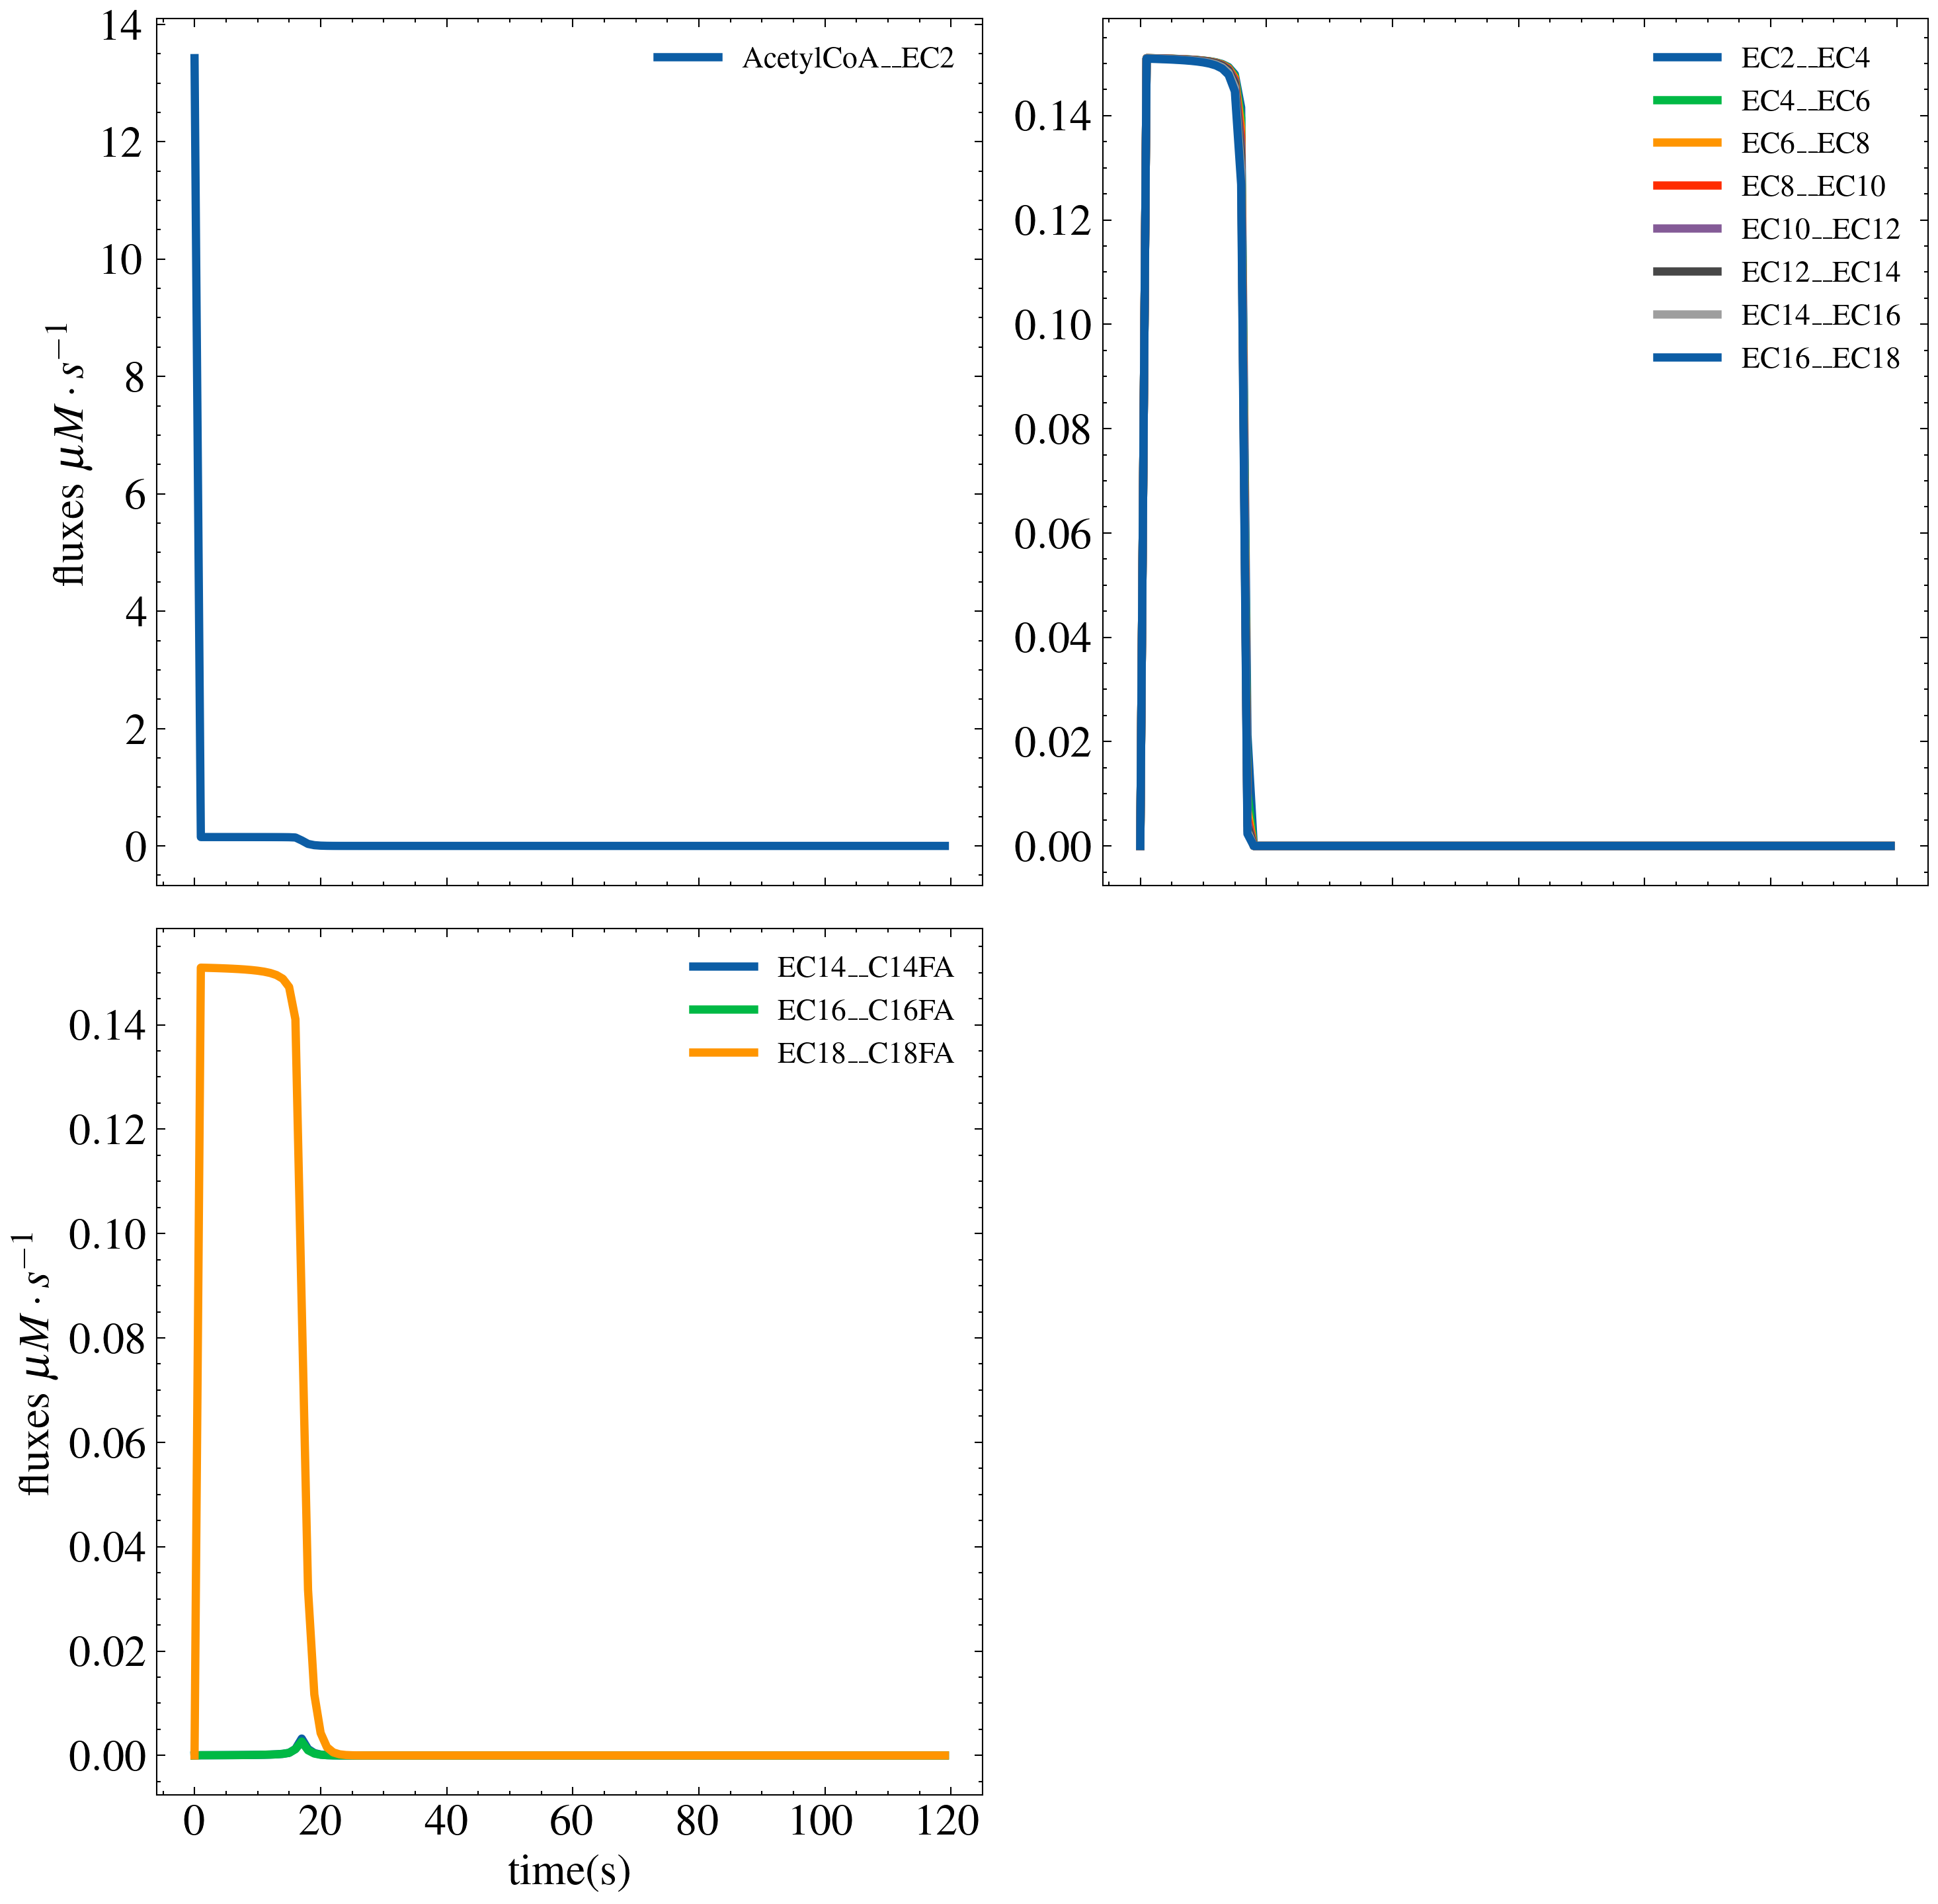

In [20]:
flux_groups = [
    ["AcetylCoA__EC2"],
    [
        "EC2__EC4",
        "EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        "EC16__EC18",
    ],
    [
    
        "EC14__C14FA",
        "EC16__C16FA",
        "EC18__C18FA",
    ],
    
]



fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model = system,
    rates= rates,
    y0 =y0,
    par=par,
    max_time=max_time1,
    ncp_list= ncp_list1,
    ncols= 2,
    resizer=5,
    sharey=False,
    title = None,
    xlabel = "time(s)",
    ylabel = "fluxes $\mu M \cdot s^{-1}$",
)

axs[1,1].set_axis_off()







### Elongation individual fluxes 

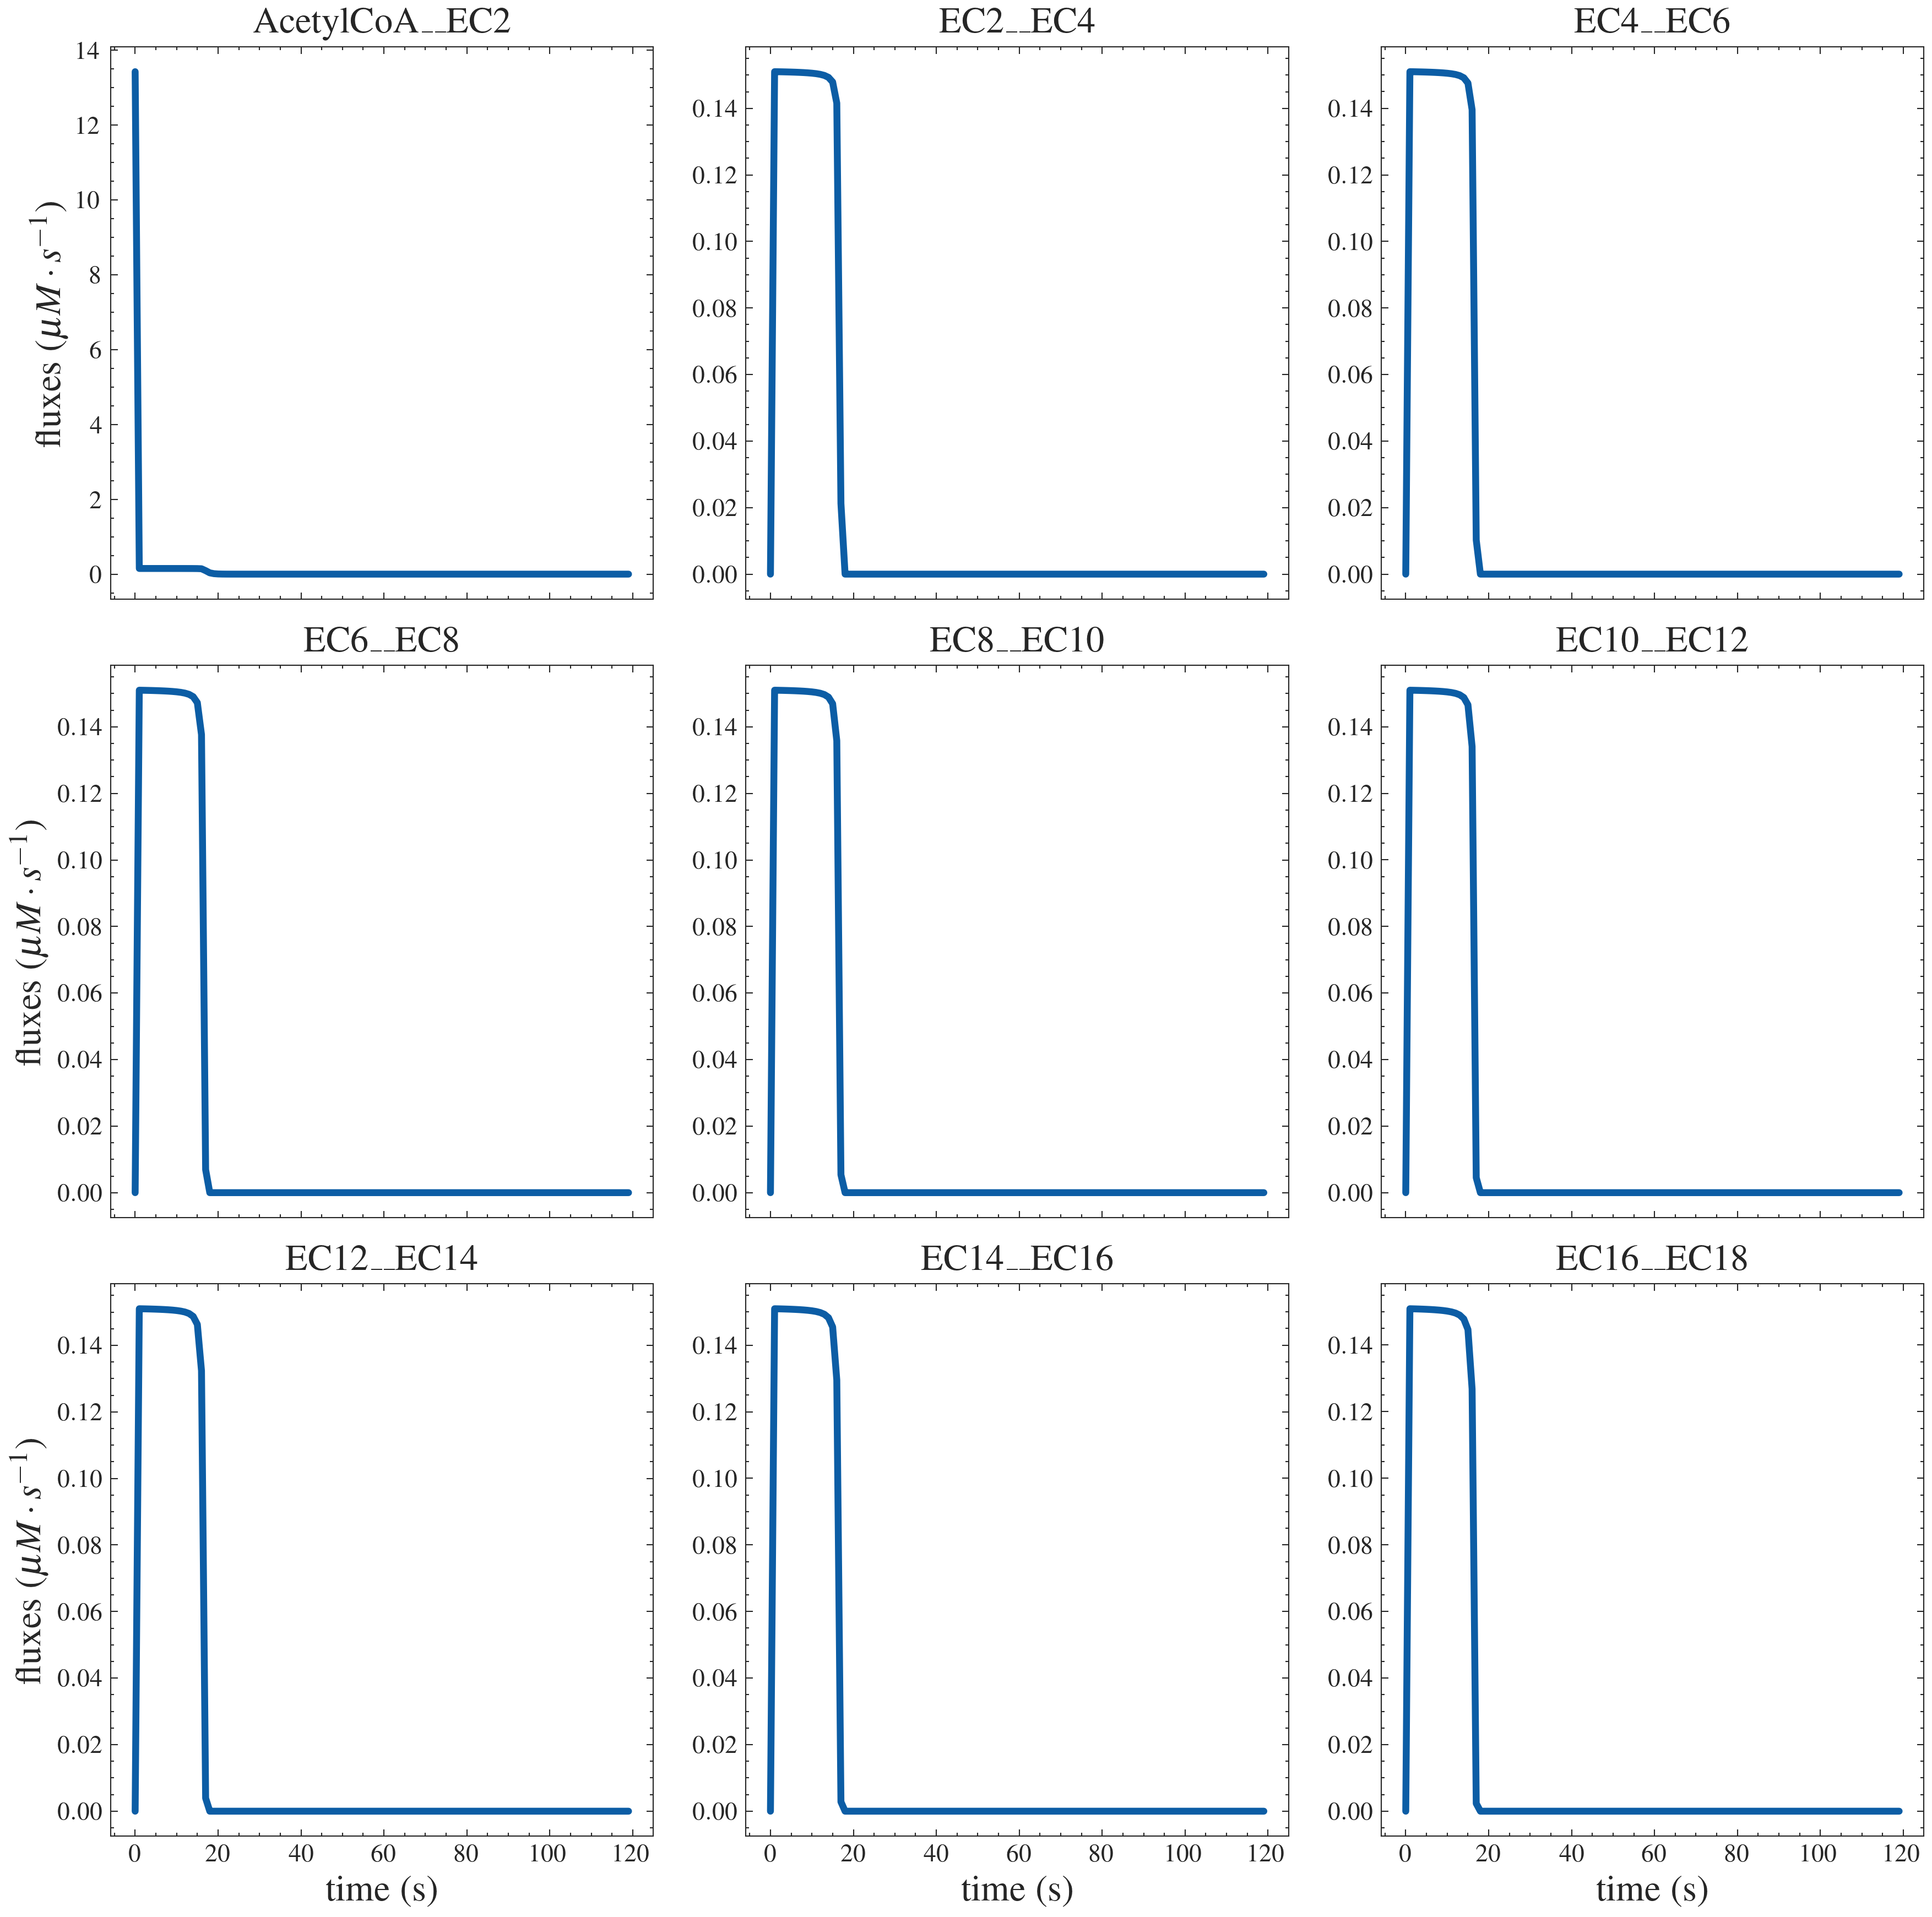

In [152]:
elongation_fluxes = [
    "AcetylCoA__EC2",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
    "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
]

fig, axs = plot_fluxes_individually(
        list_fluxes= elongation_fluxes,
        model= system,
        rates = rates,
        y0= y0,
        par=par,
        max_time =max_time1,
        ncp_list = ncp_list1,
        ncols = 3,
        resizer=4,
        sharey=False,
#         title: str = None,
          xlabel = "time (s)",
       ylabel = "fluxes ($\mu M \cdot s^{-1}$)",
    )


### production individual fluxes 

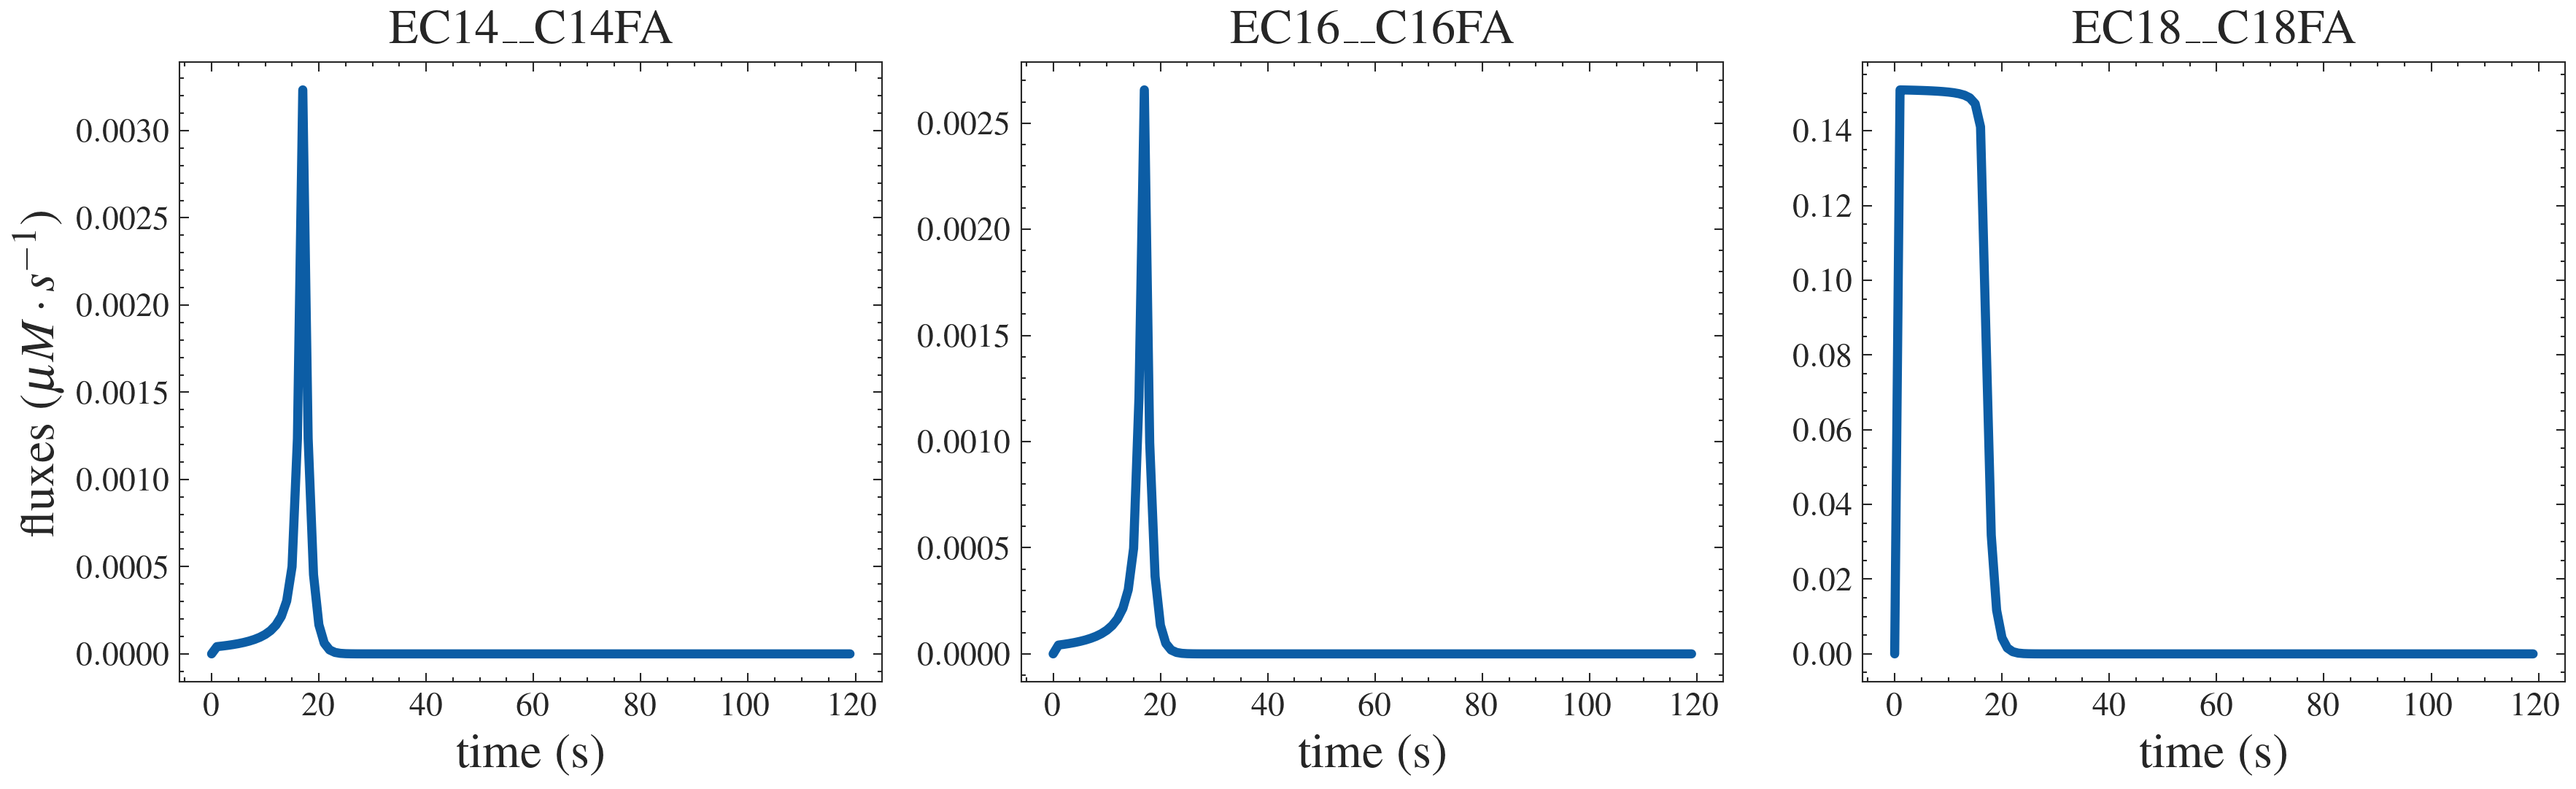

In [153]:
production_fluxes = [
    
# "EC4__C4FA",
# "EC6__C6FA",
# "EC8__C8FA",
# "EC10__C10FA",
# "EC12__C12FA",
"EC14__C14FA",
"EC16__C16FA",
"EC18__C18FA",
]


fig, axs = plot_fluxes_individually(
        list_fluxes= production_fluxes,
        model= system,
        rates = rates,
        y0= y0,
        par=par,
        max_time =max_time1,
        ncp_list = ncp_list1,
        ncols = 3,
        resizer=4,
        sharey=False,
#         title: str = None,
          xlabel = "time (s)",
       ylabel = "fluxes ($\mu M \cdot s^{-1}$)",
    )


# Plot the time course 

### Plot time course by group

To Estimate the value of parameters that reproduce Topolska and al. data, we first consider the rapid binding given that the subtrates are in excess.Furthermore we consider that production of short and meduim chain fatty acid are negligeable compare to to those of LCFAS as shown by experimental data.On this assumptions, instantaneously the concentration of the total enzyme is sensibly equal to the concentrattion of $EC_{16}$ species. From this concentration of the enzyme we can estimate $k_{d7}$ and $\delta$. For the estimation of the later, we additionnally assume that the flux into $EC_{18}$ are equal to the flux of production of of $C18:0$ FA. The latter assumption makes $K_{d8}$
a minor parameter for the systemunder this assumptions,  the rate of release $v_{out\_{C16}}$ of palmitic acid ($C16:0$ )is calculated in the following 

$$
v_{out\_{C16}} =  k_{d7} \times EC16 
$$, 
which implies that 
$$
 k_{d7}  = \dfrac{v_{out\_{C16}}}{EC16 }
$$

From the initial phase data phace data we can infer $v_{out\_{C16}}$  as the concentration $C16$ after 120 secondes  divided by the time (12 0secondes). Hence   $$v_{out\_{C16}} \simeq \dfrac{0.55}{120} =0.0046 \mu M^{-1} s^{-1}$$

 we have $$k_{d7} = 0.03 s^{-1}, \qquad  \delta= 1.17e-06 \mu M ^{-3} s^{-1}$$

Of course the value of beta and Kappa does not matter for the initial phase as we setted  $k_{di}\quad  1\leq i \leq 5$ to 0.  We only have  choose the value of $\beta$ and $\kappa$ fast enough for the rapid binding to be furfilled. but here we give abitrary values to these parameters. 

In [154]:
par = {
    "beta": 1e-01,
    "kappa": 1e-2,
    "delta": 1.16e-06,  #
    # "kd1": 0,
    # "kd2": 0,
    # "kd3": 0,
    # "kd4": 0,
    # "kd5": 0,
    "kd6": 1,
    "kd7": 0.03,  #
    "kd8": 1,
 
}

In [5]:
time_course = [
    ["NADPH"],["AcetylCoA"], ["MalonylCoA"],
   
    ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
    
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title="Time course",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
for i in range(3):
    axs[1, 1].scatter(time_initial_phase, data_initial_phase[:, i])
# axs[1, 1].scatter(time_initial_phase, data_initial_phase[:, 1])   
# axs[1, 2].scatter(time_initial_phase, data_initial_phase[:, 2])

NameError: name 'simulate_time_course' is not defined

## Remark:
With the abitrary value of $\beta$  and $\kappa$ and the calculation of $k_{d7}$ and $\delta$ we are able to reproduice the initial phase data. We also set  $k_{d6}$ and $k_{d8}$. 



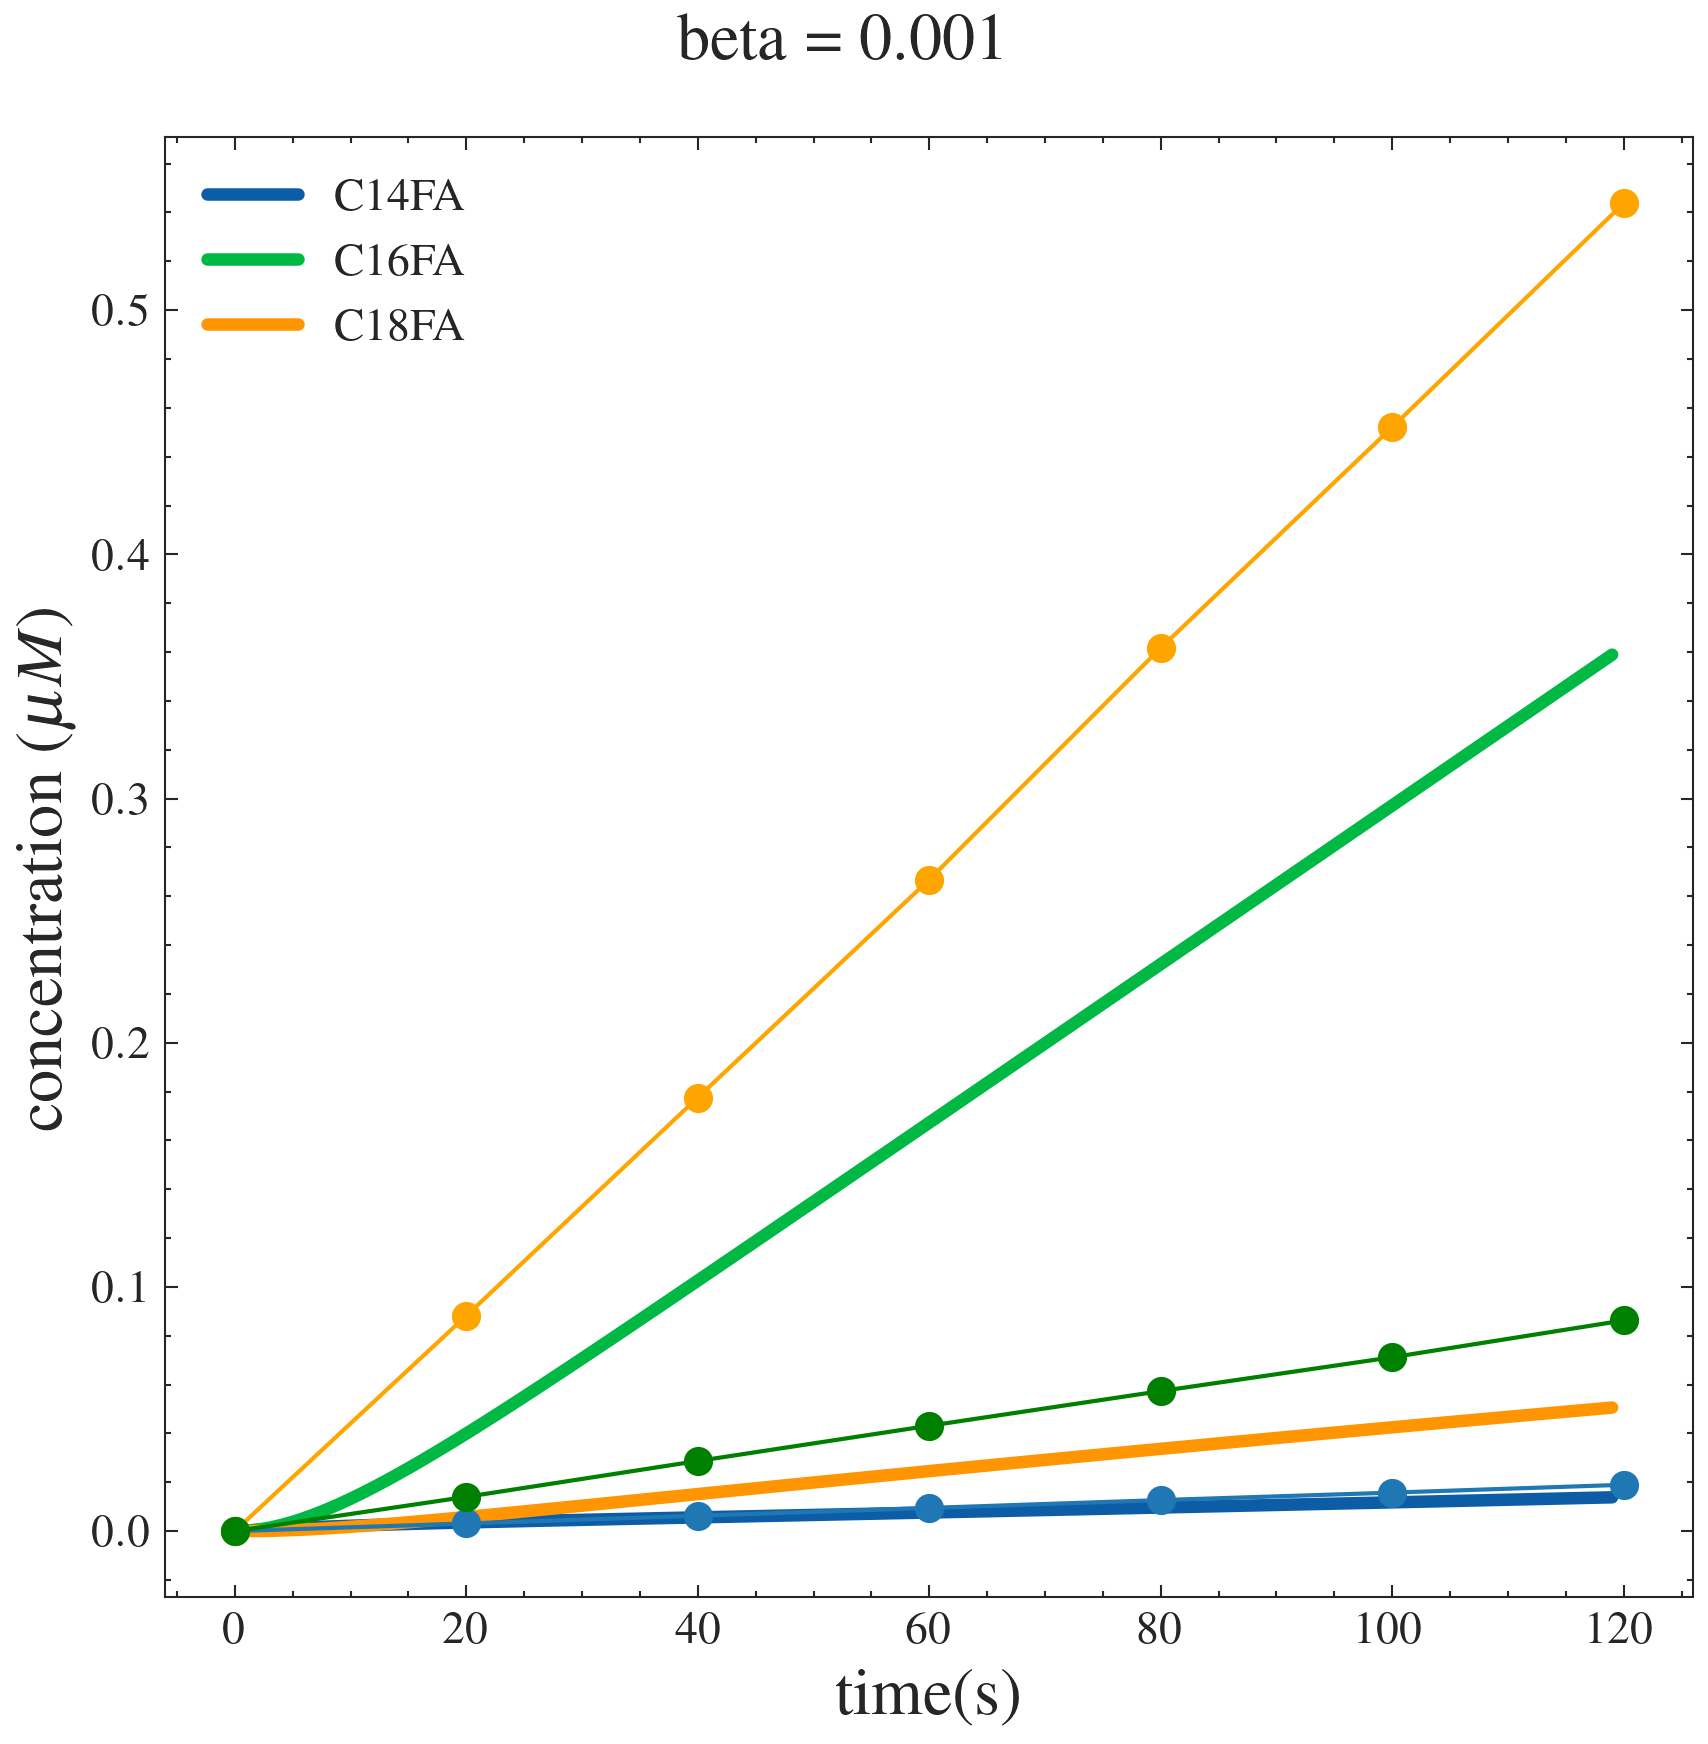

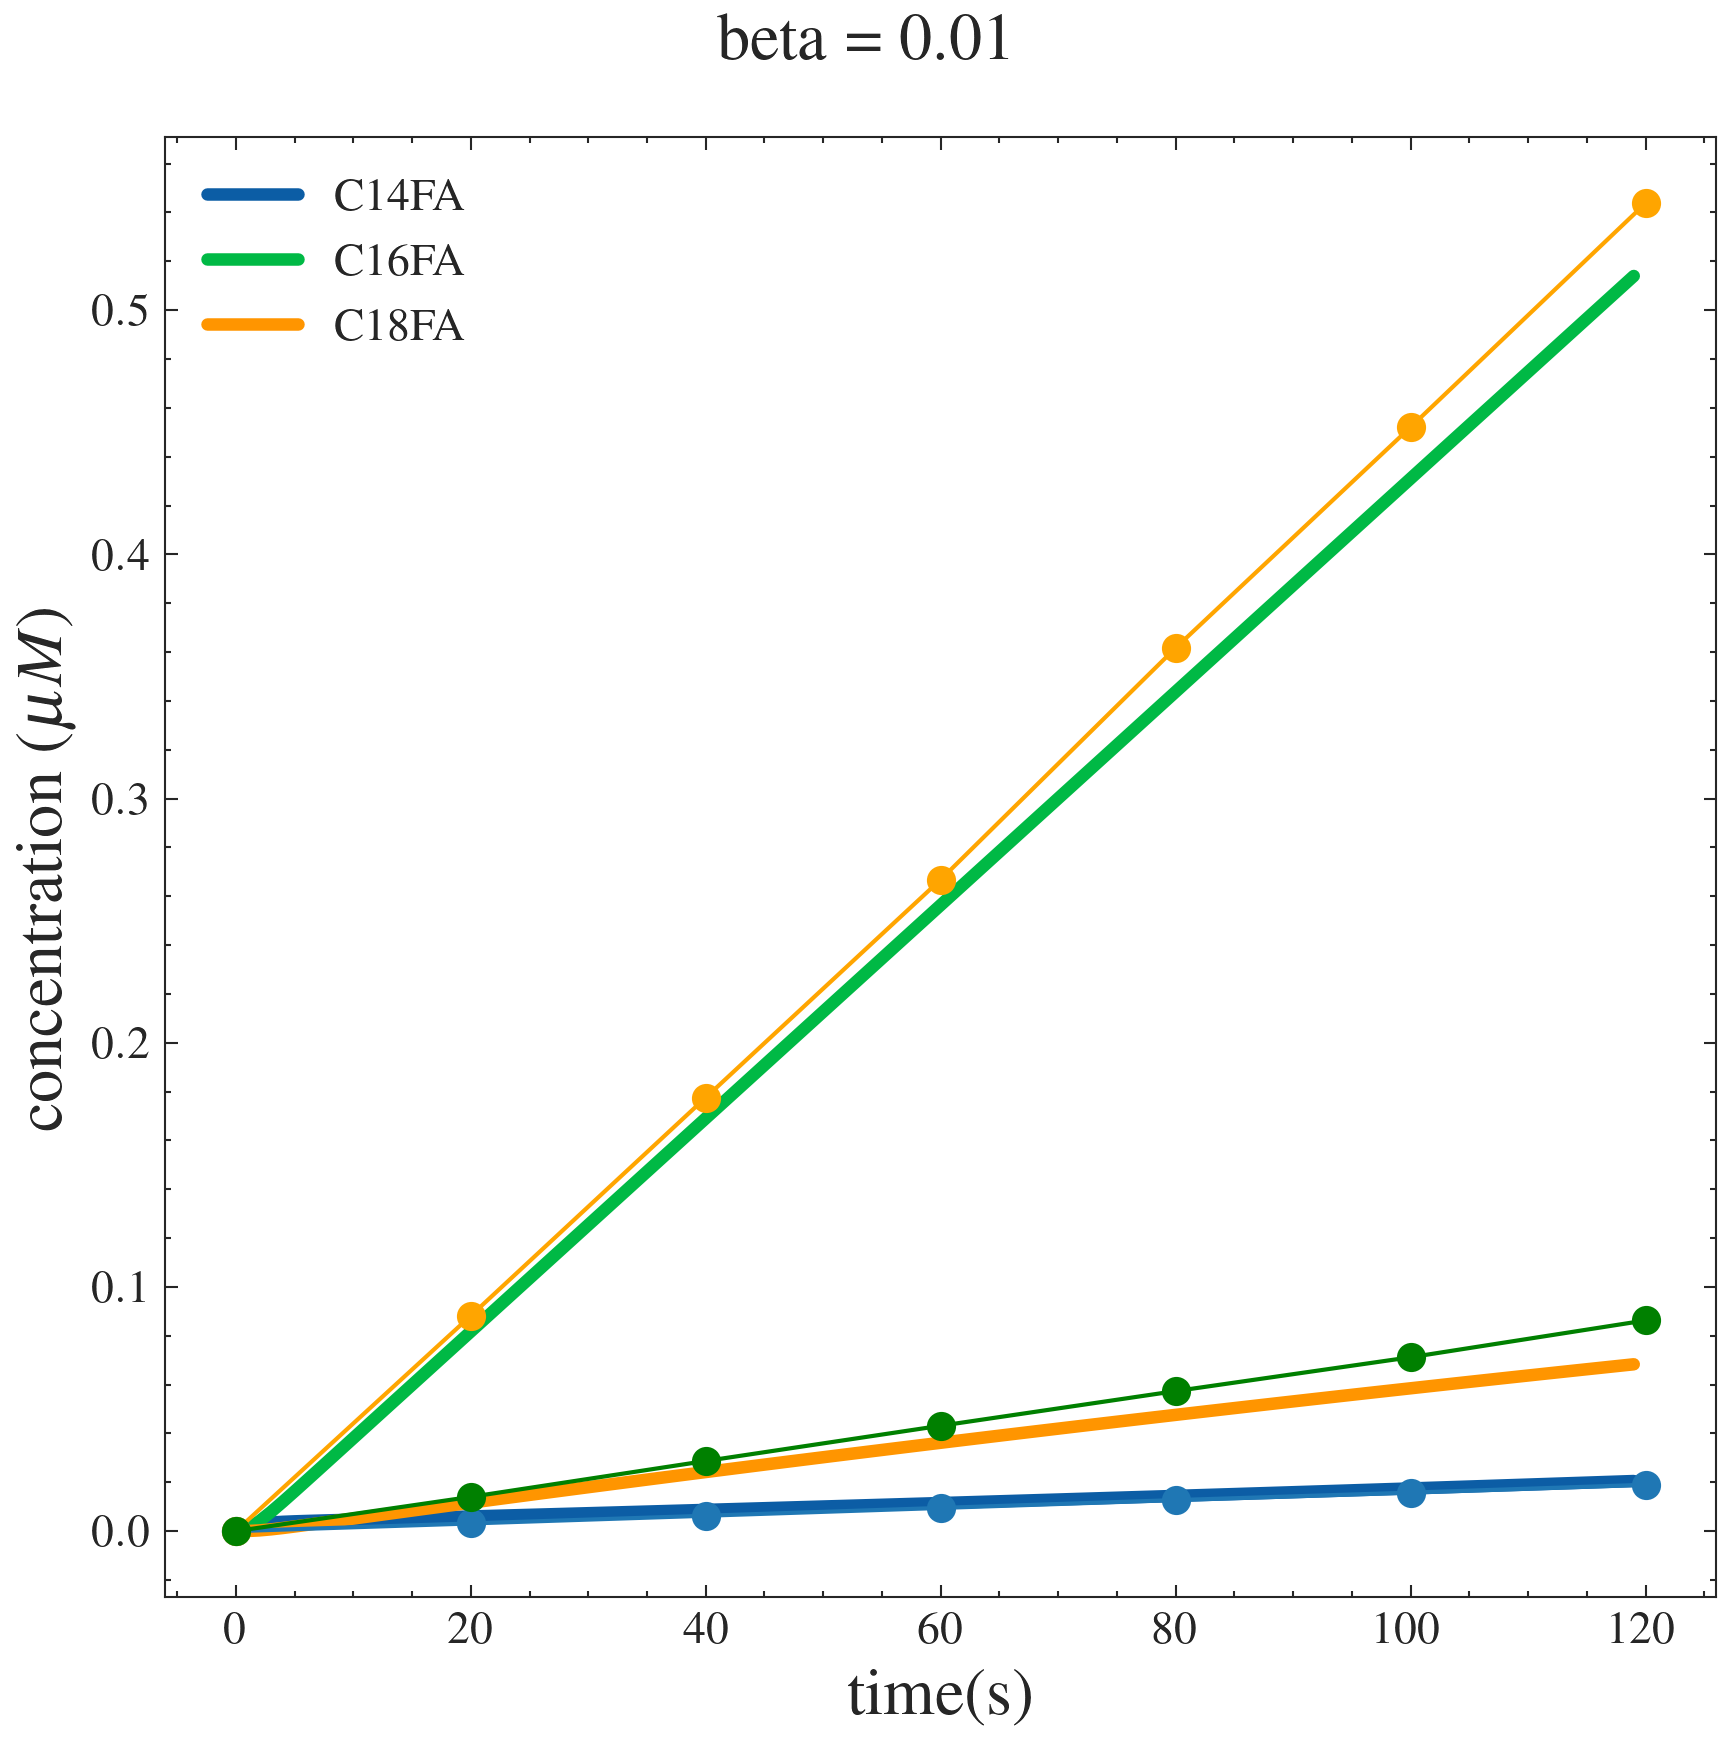

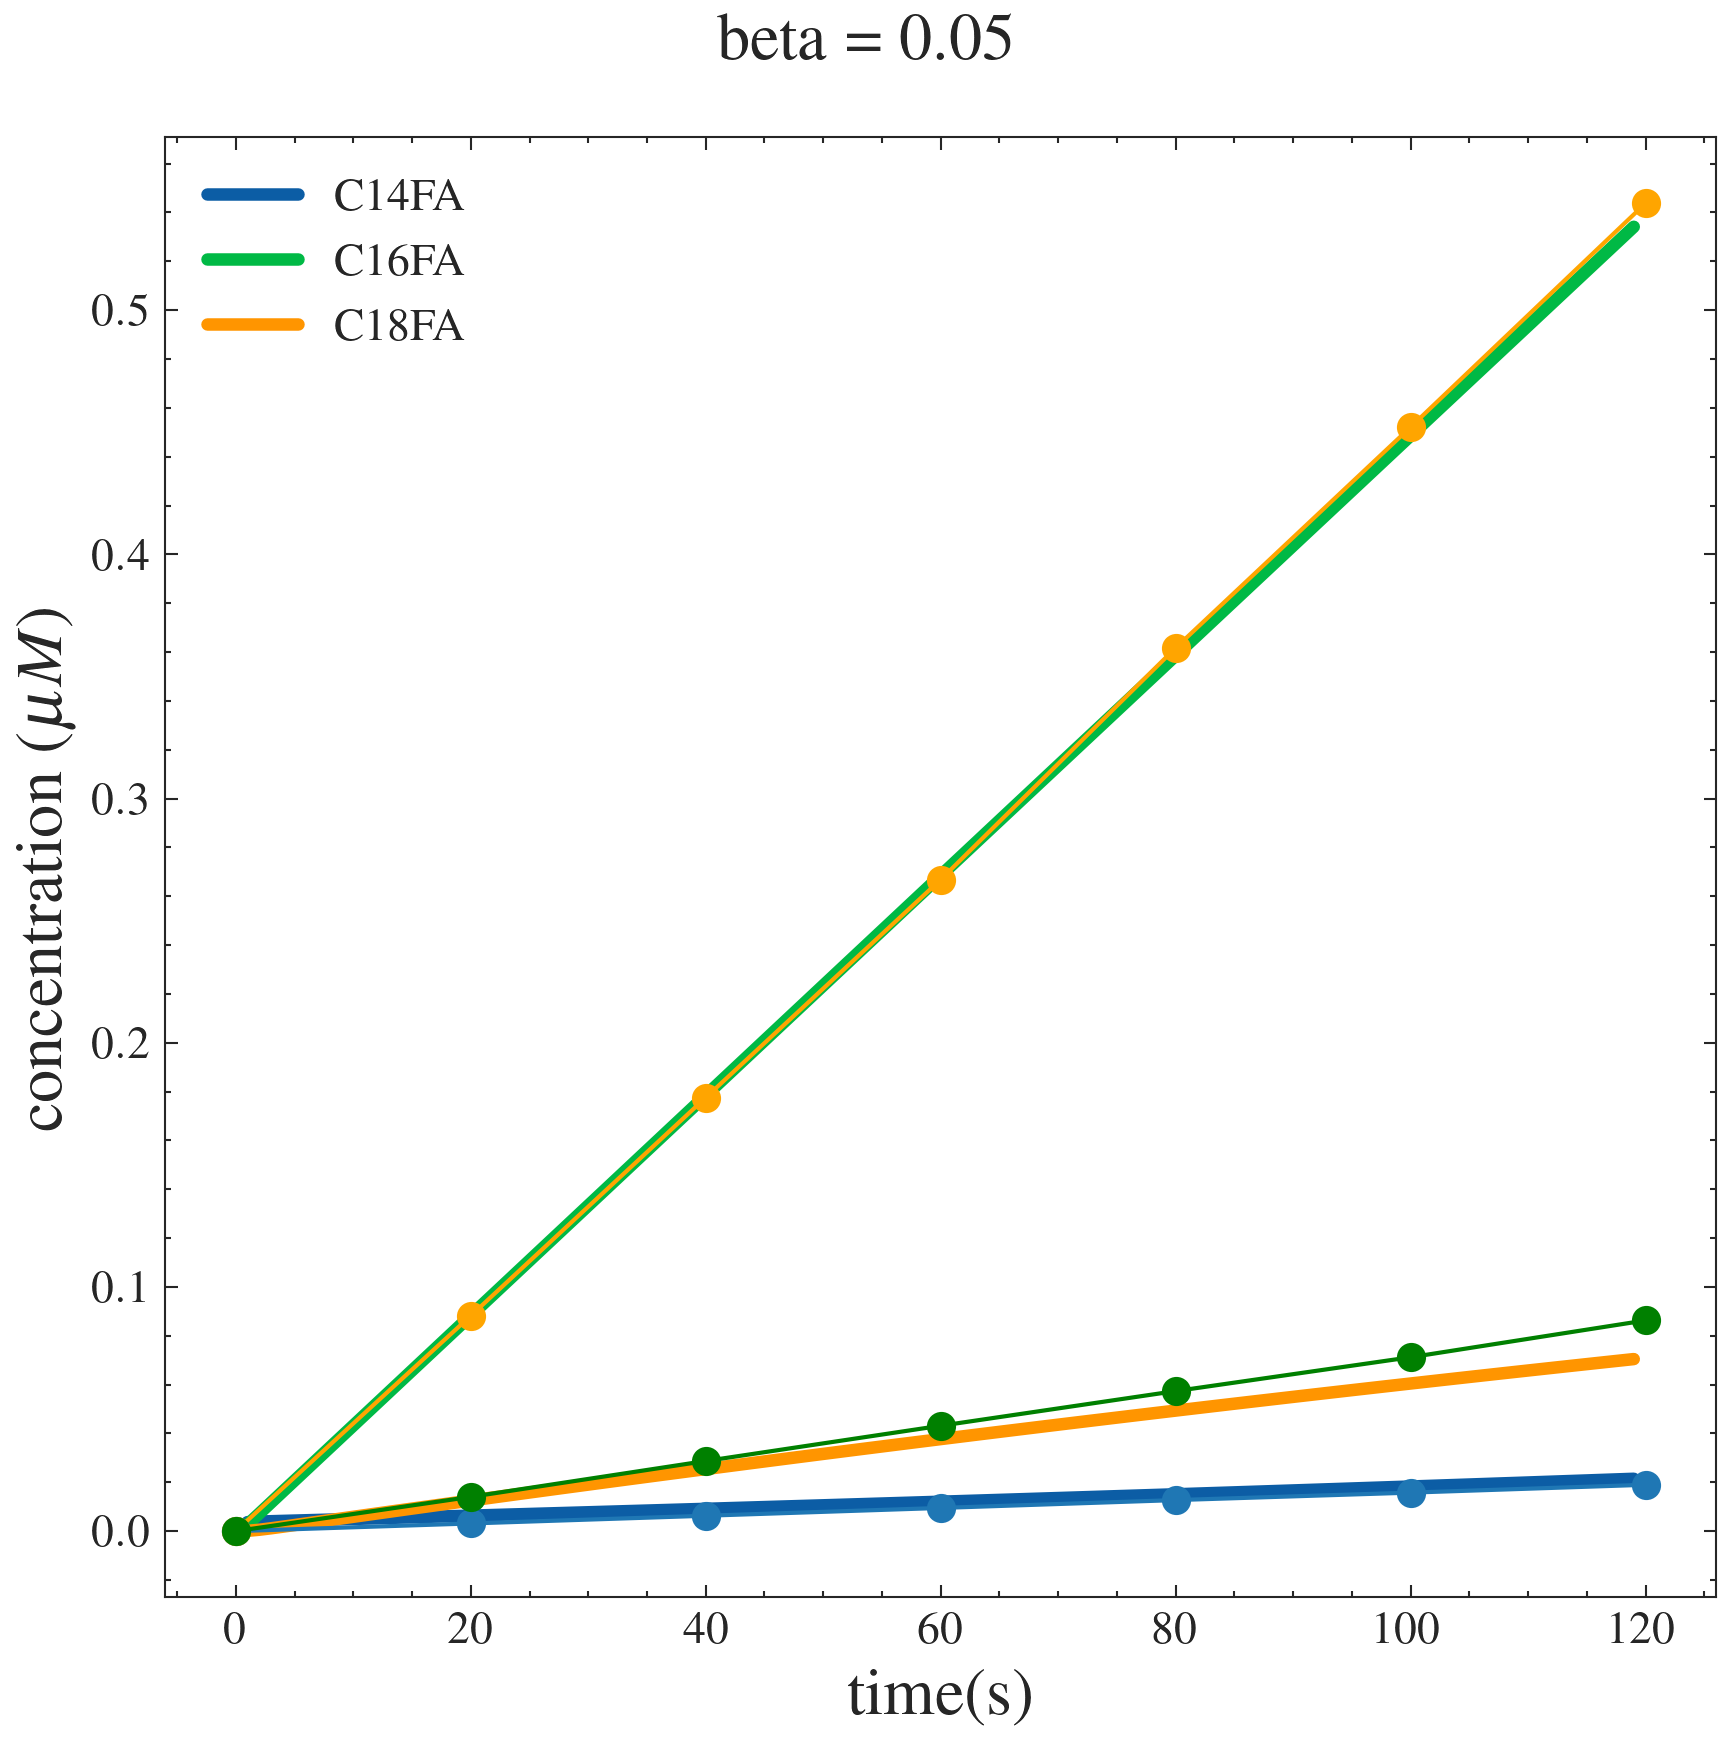

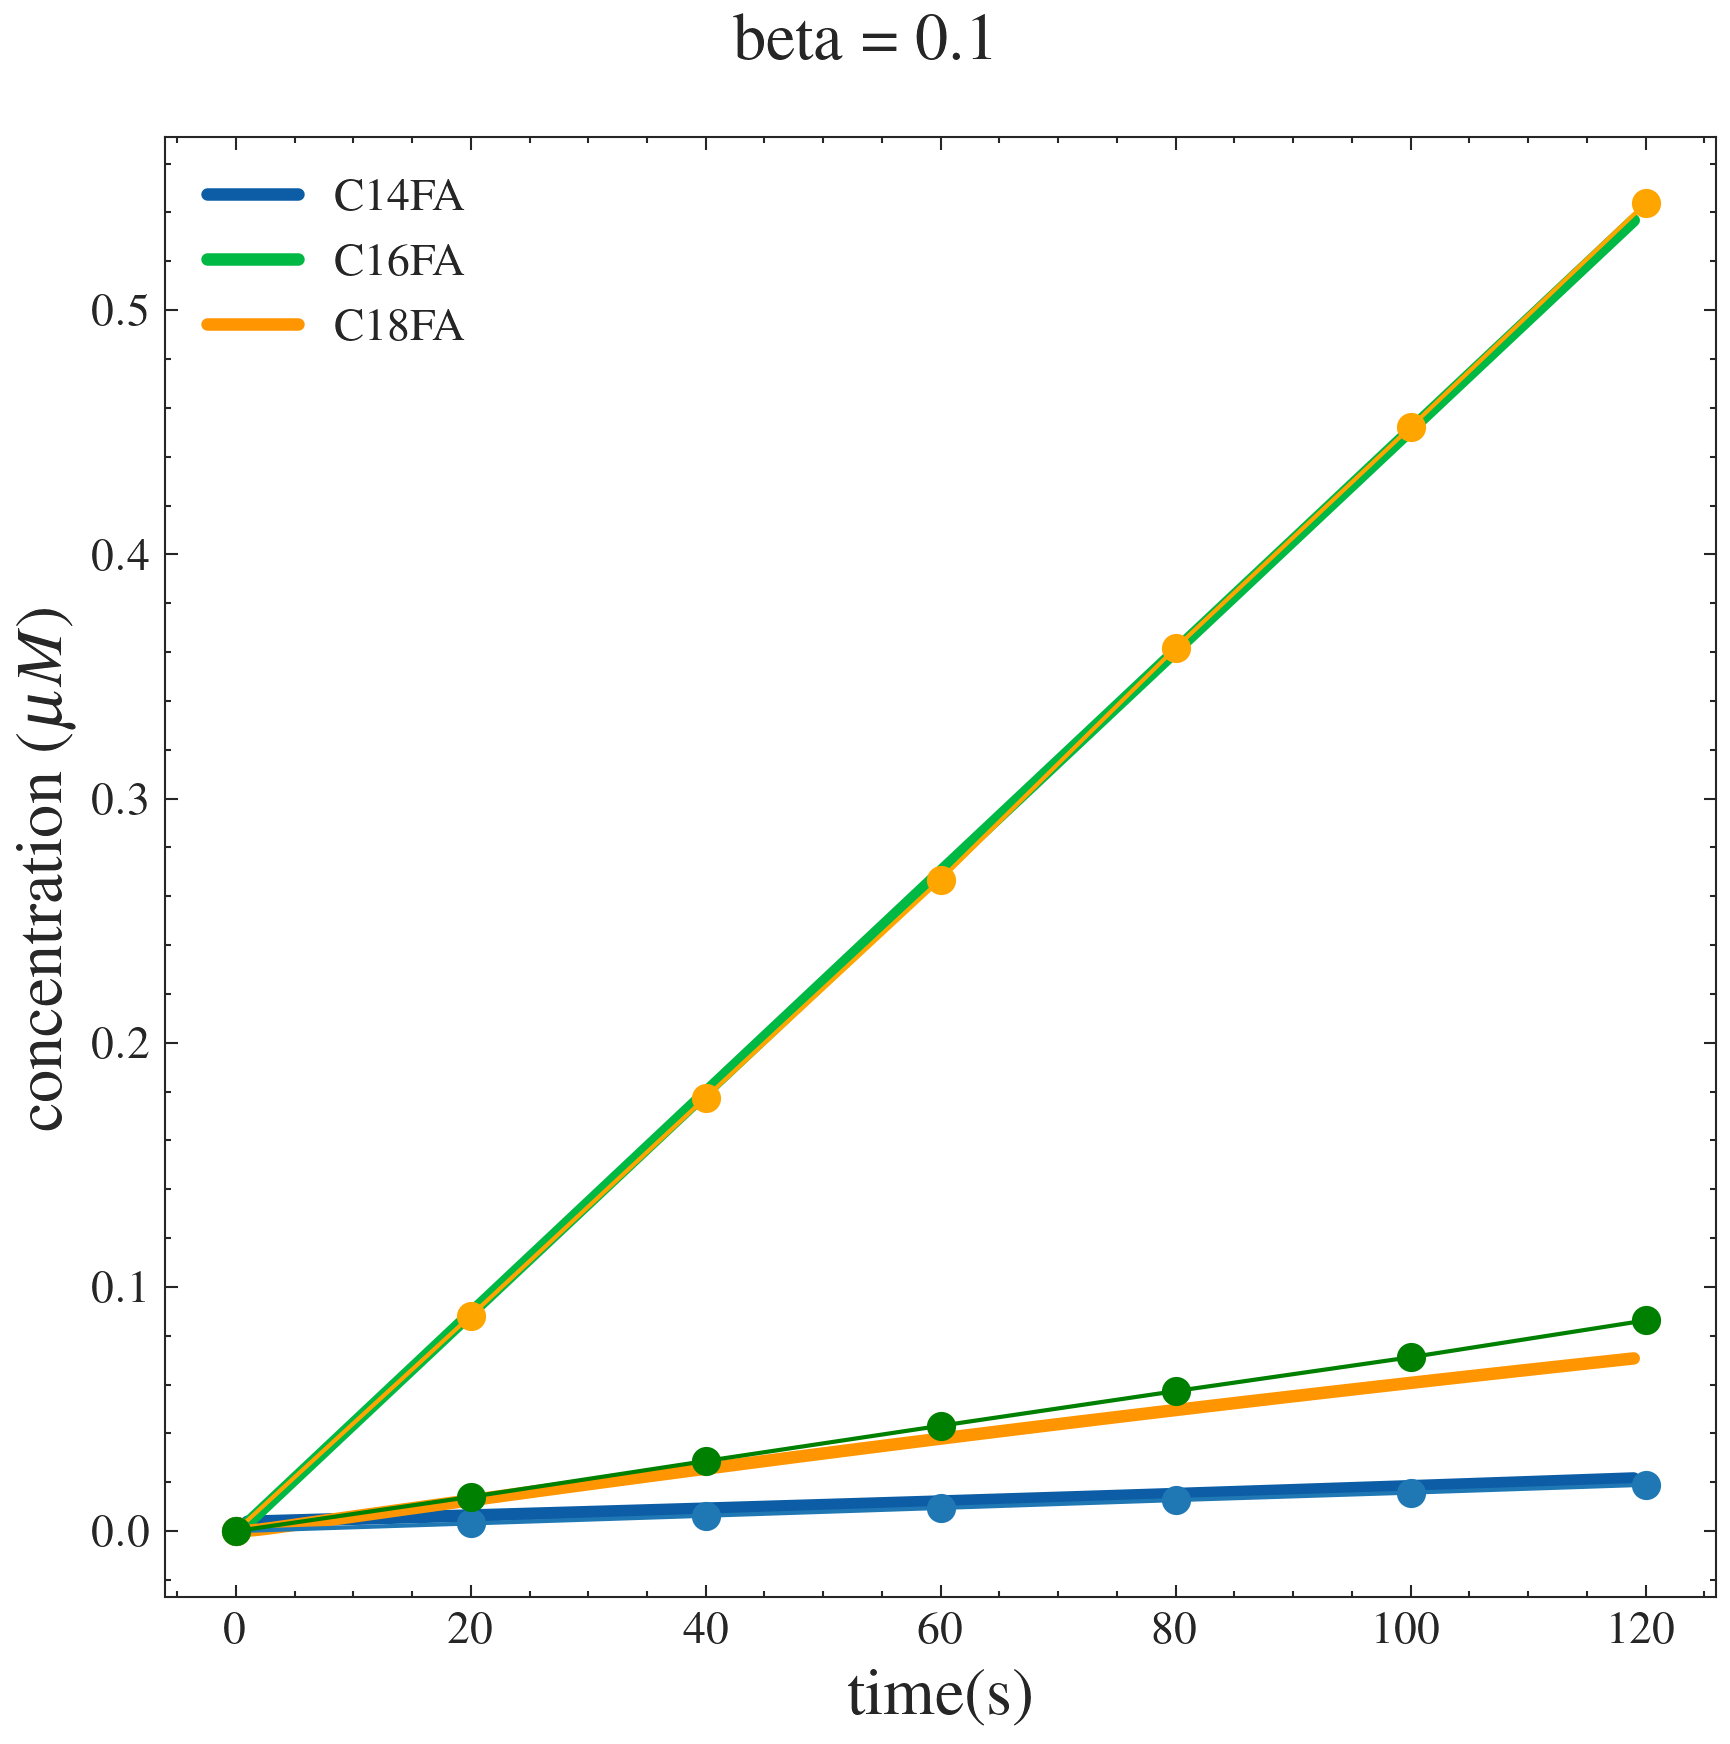

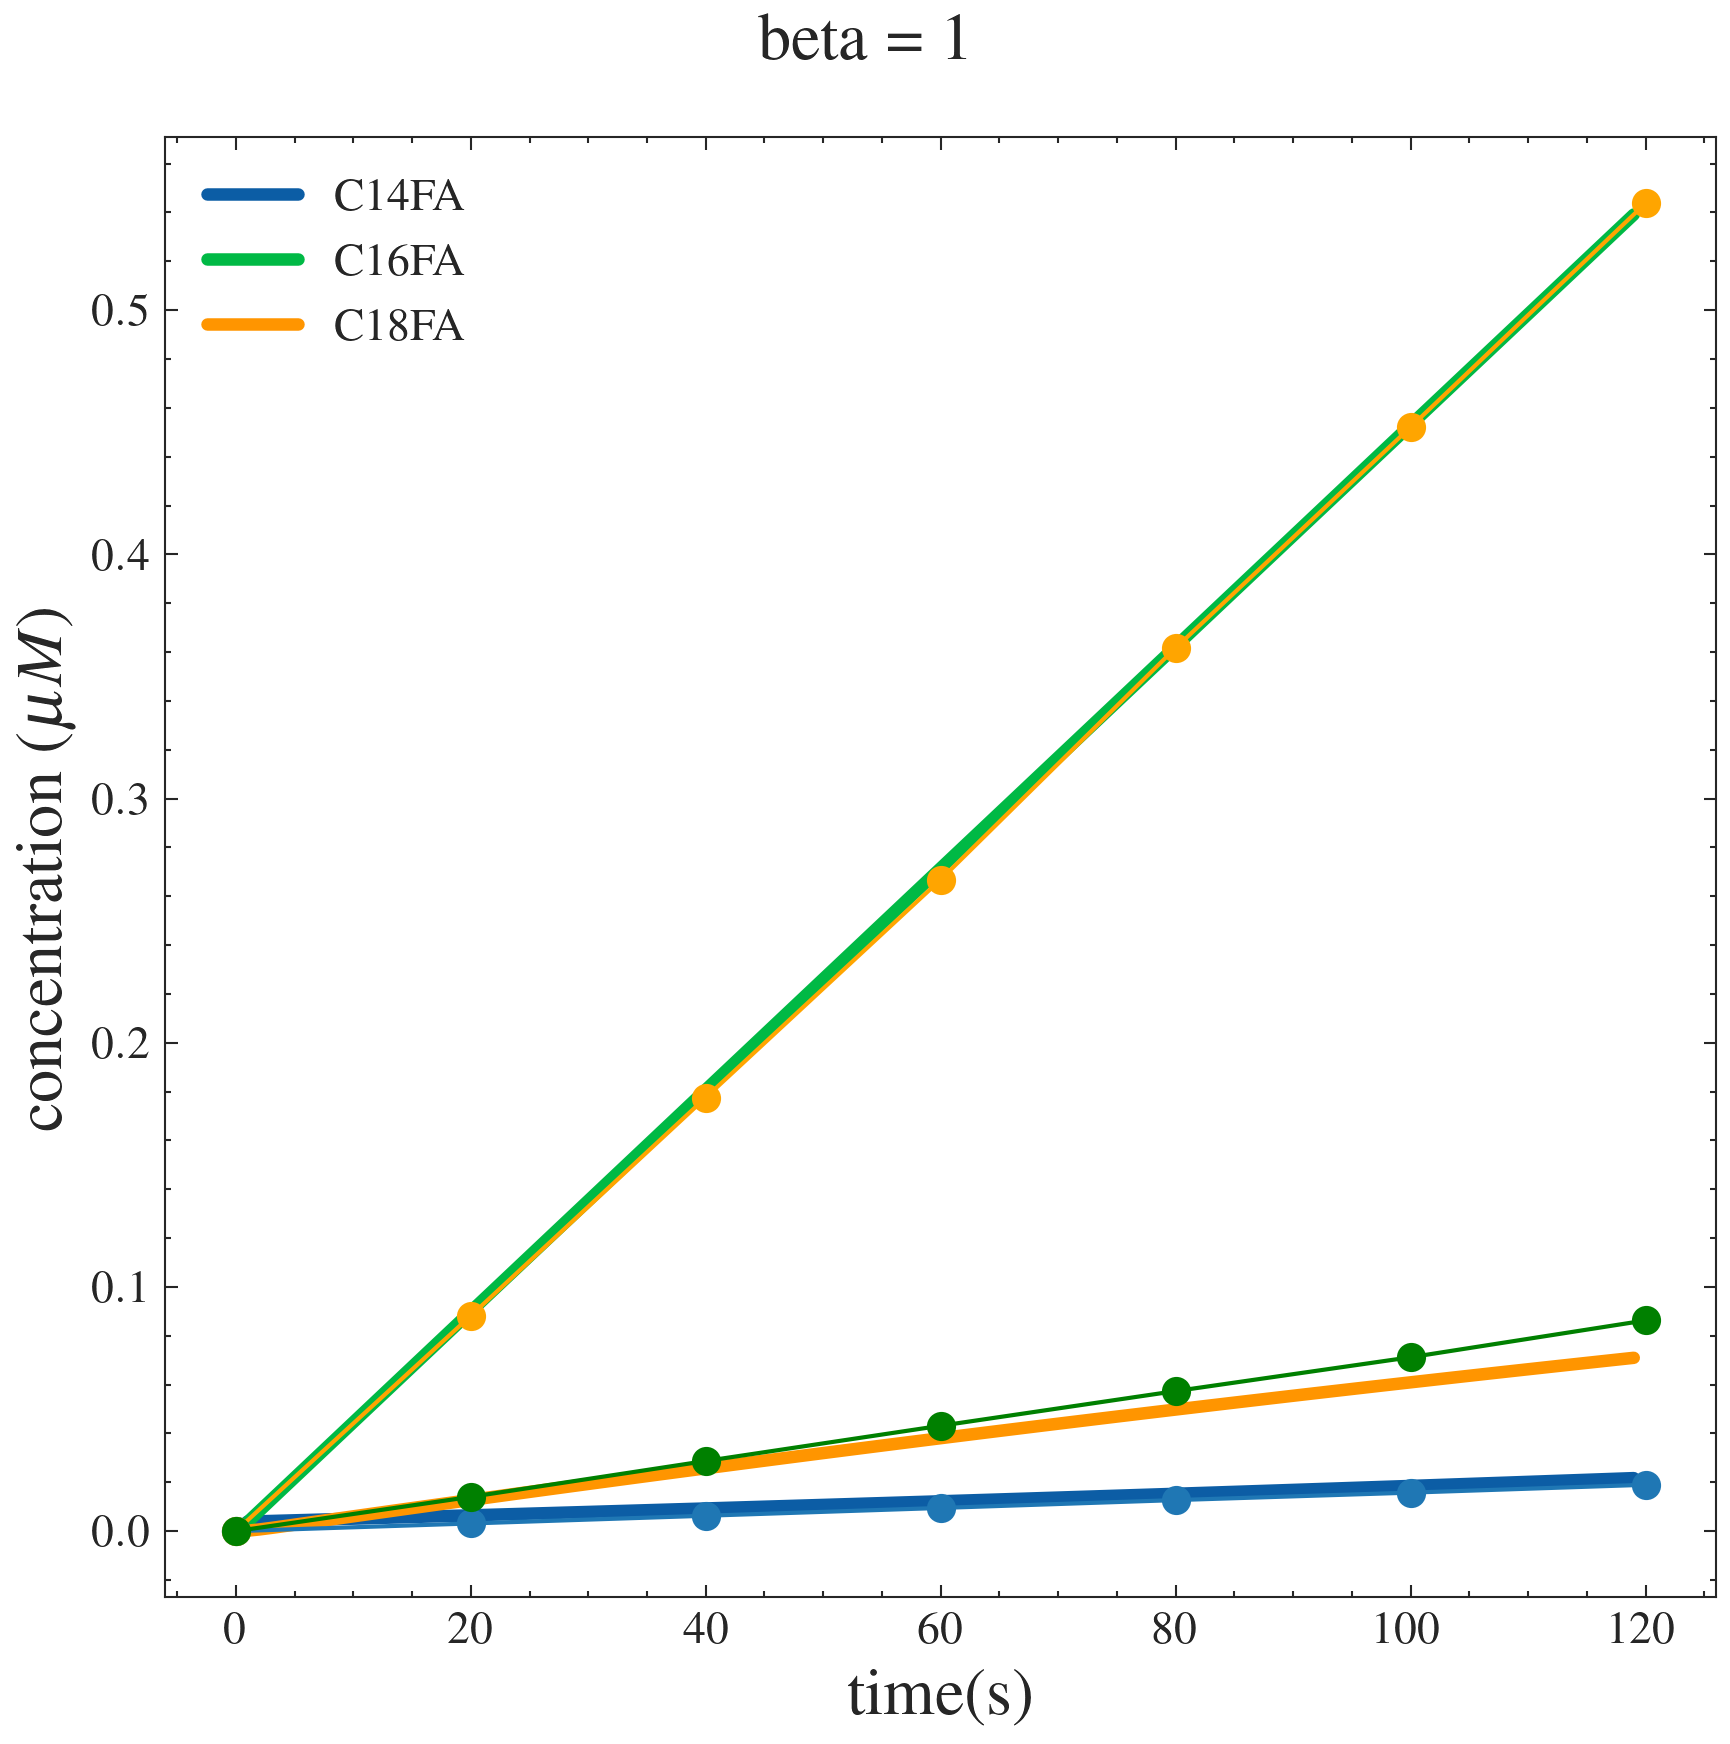

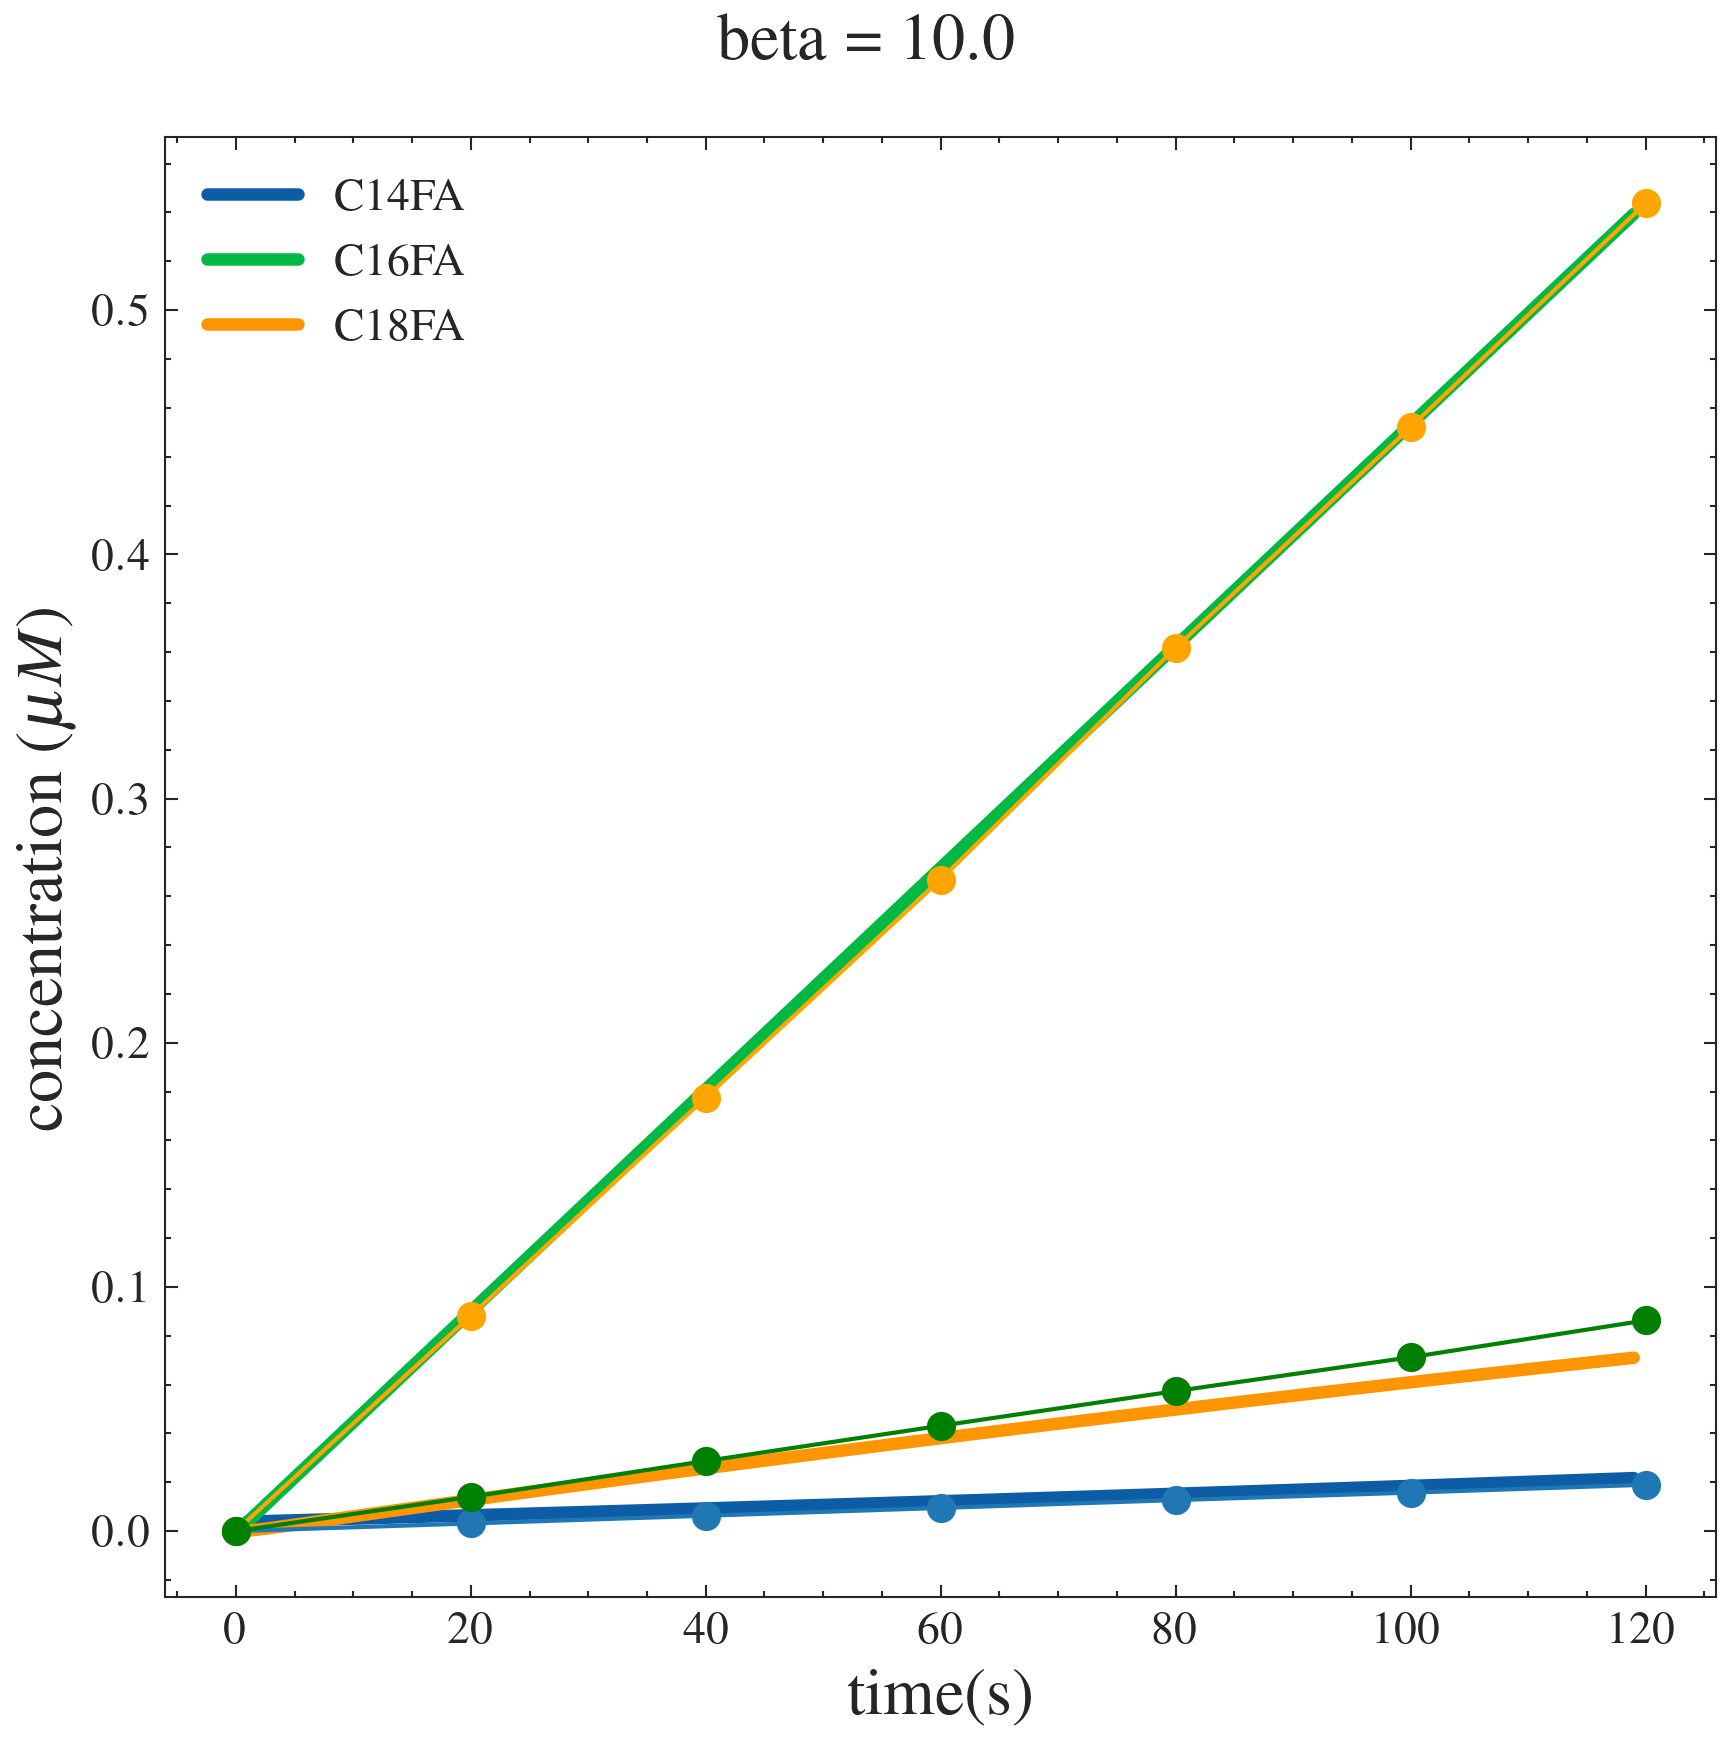

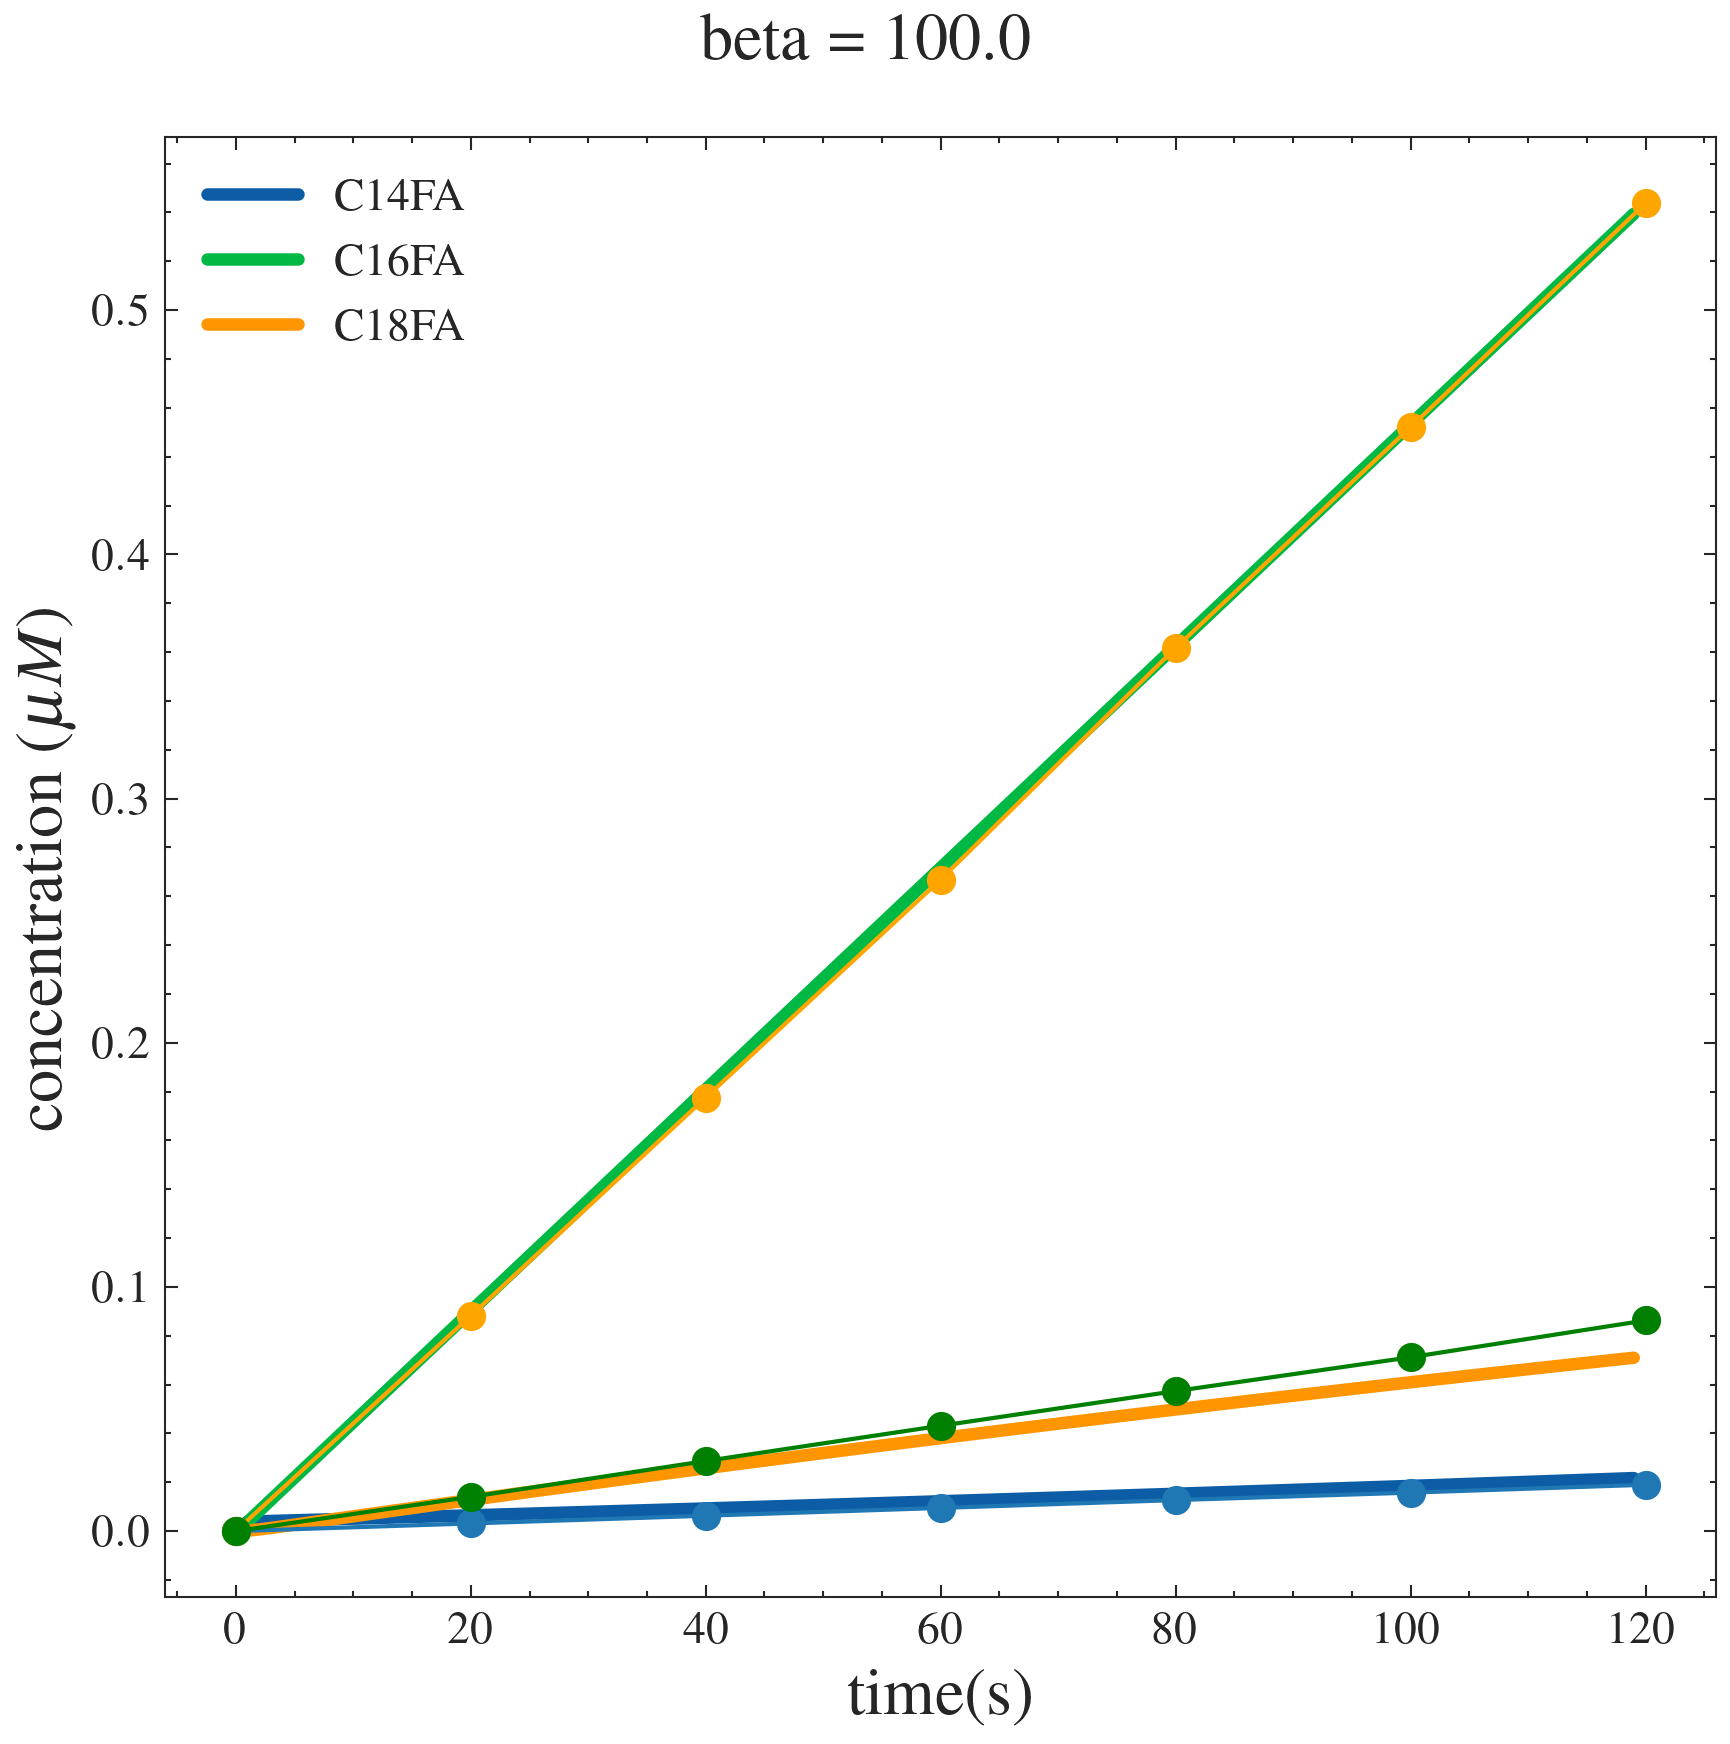

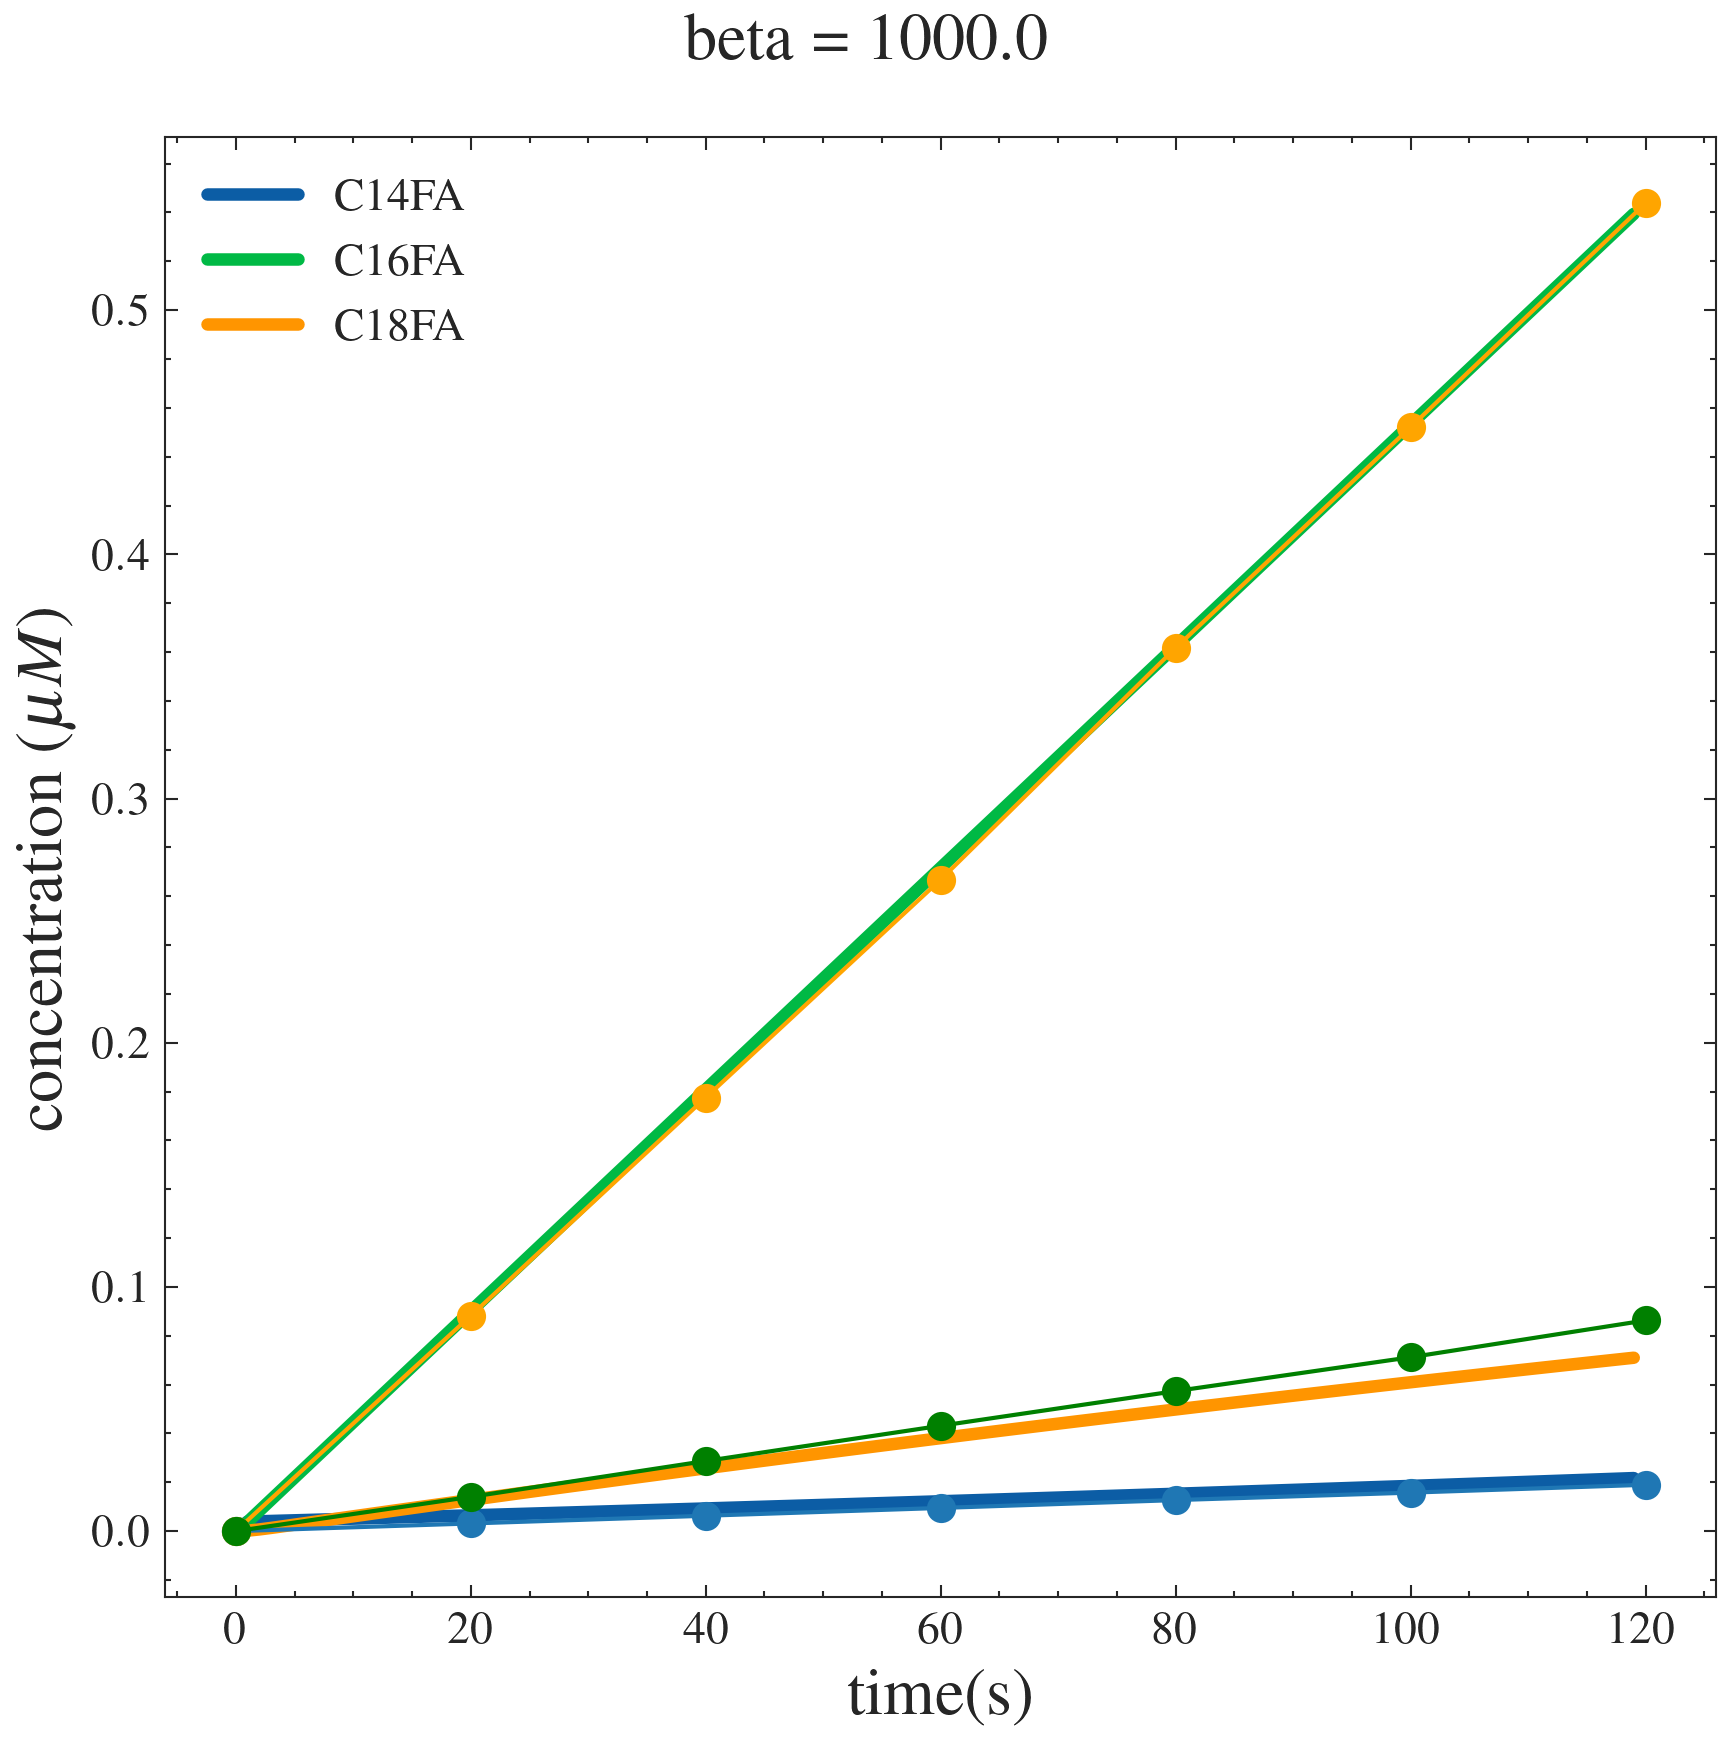

In [156]:
data_interest = [
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]
par_copy1 = par.copy()
colors = ["#1f77b4", "orange", "green"]

vals =[1e-3, 1e-2, 5e-2, 1e-1, 1, 1e1, 1e2, 1e3]

for val in vals:
    par_copy1["beta"] = val
    fig, axs = multi_plot_time_course(
        groups=data_interest,
        func=simulate_time_course,
        model=system,
        y0=y0,
        max_time=max_time1,
        ncp_list=ncp_list1,
        par=par_copy1,
        compounds=compounds,
        ncols=1,
        resizer=6,
        sharey=False,
        title=f"beta = {val}",
        xlabel="time(s)",
        ylabel="concentration ($\mu M$)",
    )
    # adding data to a particular graph
    for i in range(3):
        axs[0, 0].plot(time_initial_phase, data_initial_phase[:, i], "o-", color=colors[i])
        plt.savefig(RESULTS_DIR /f"beta={val}.png")       
        
par["beta"] = 1e-01

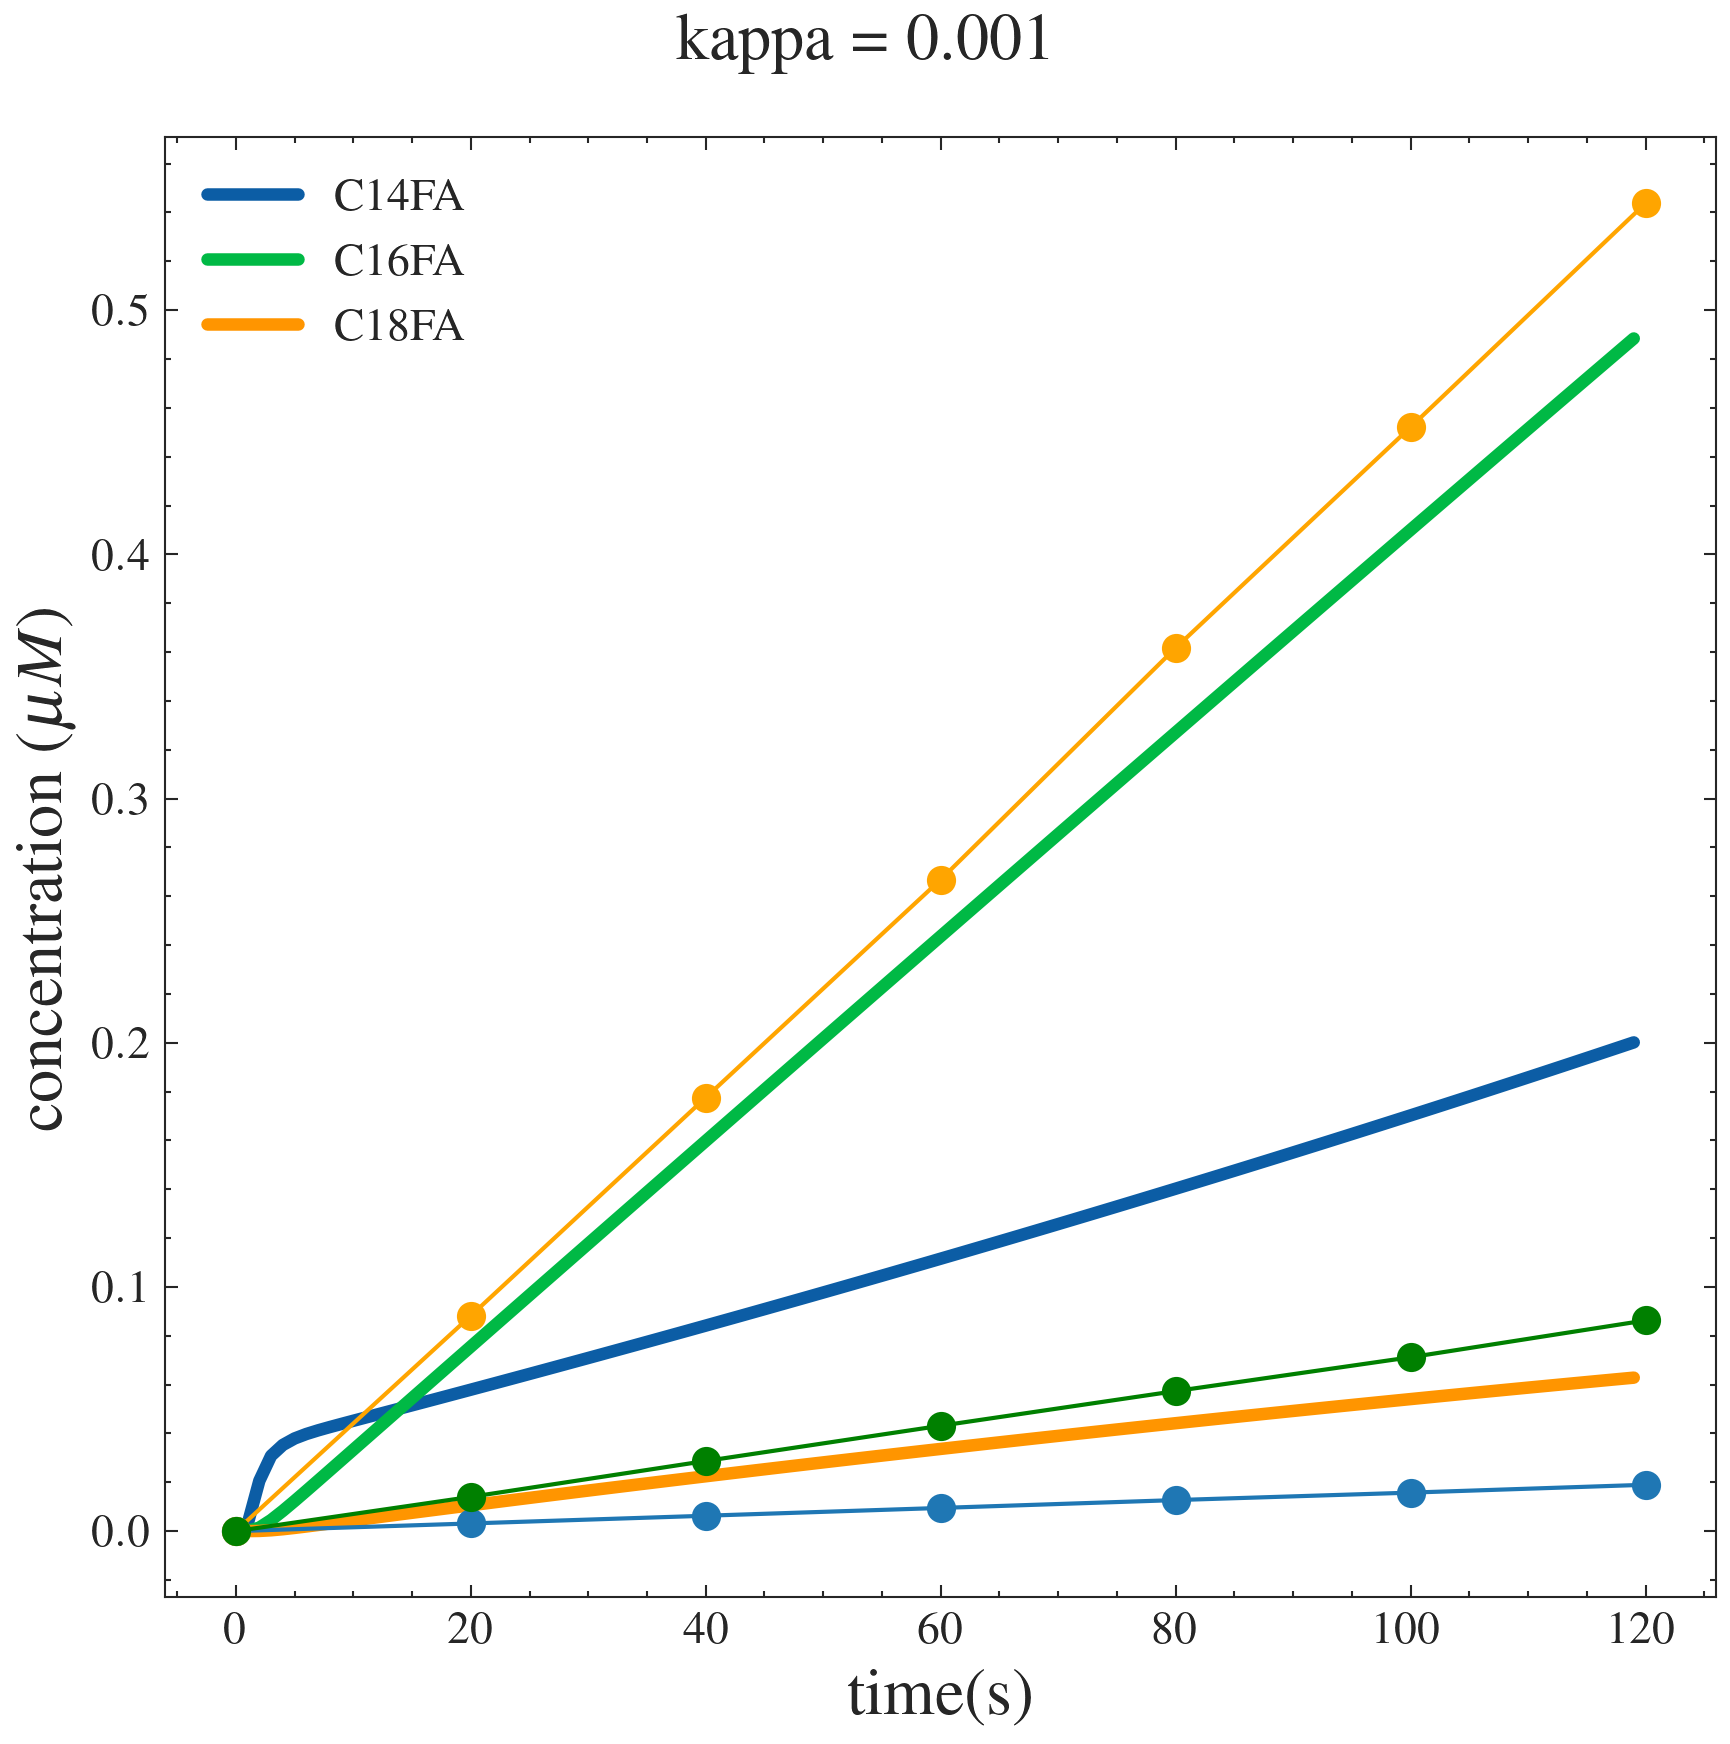

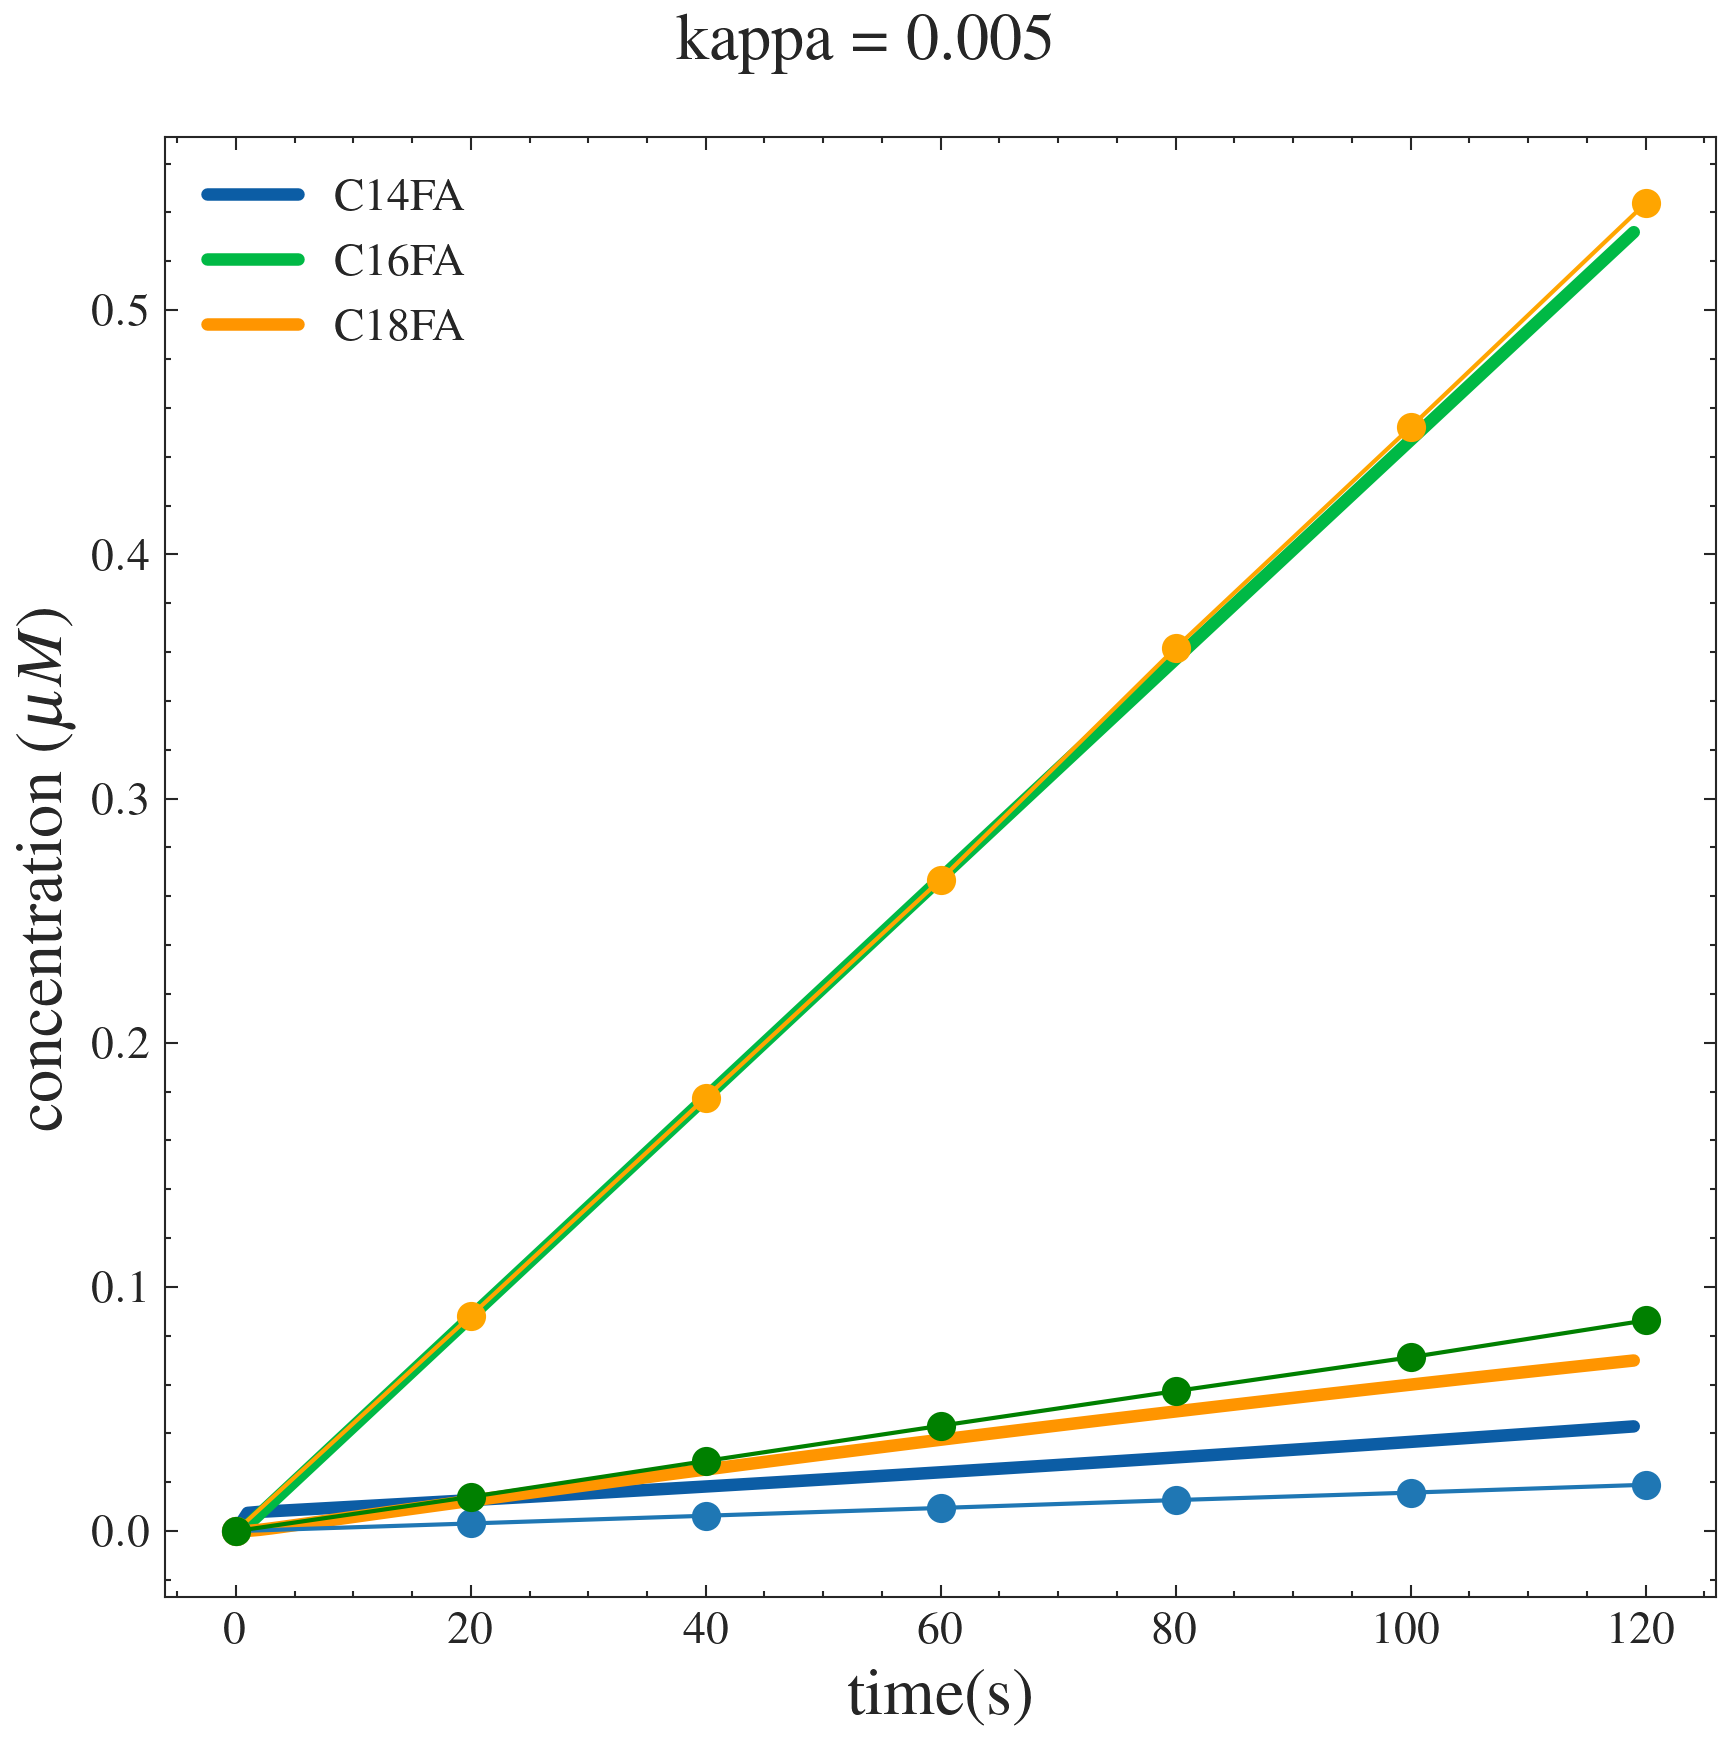

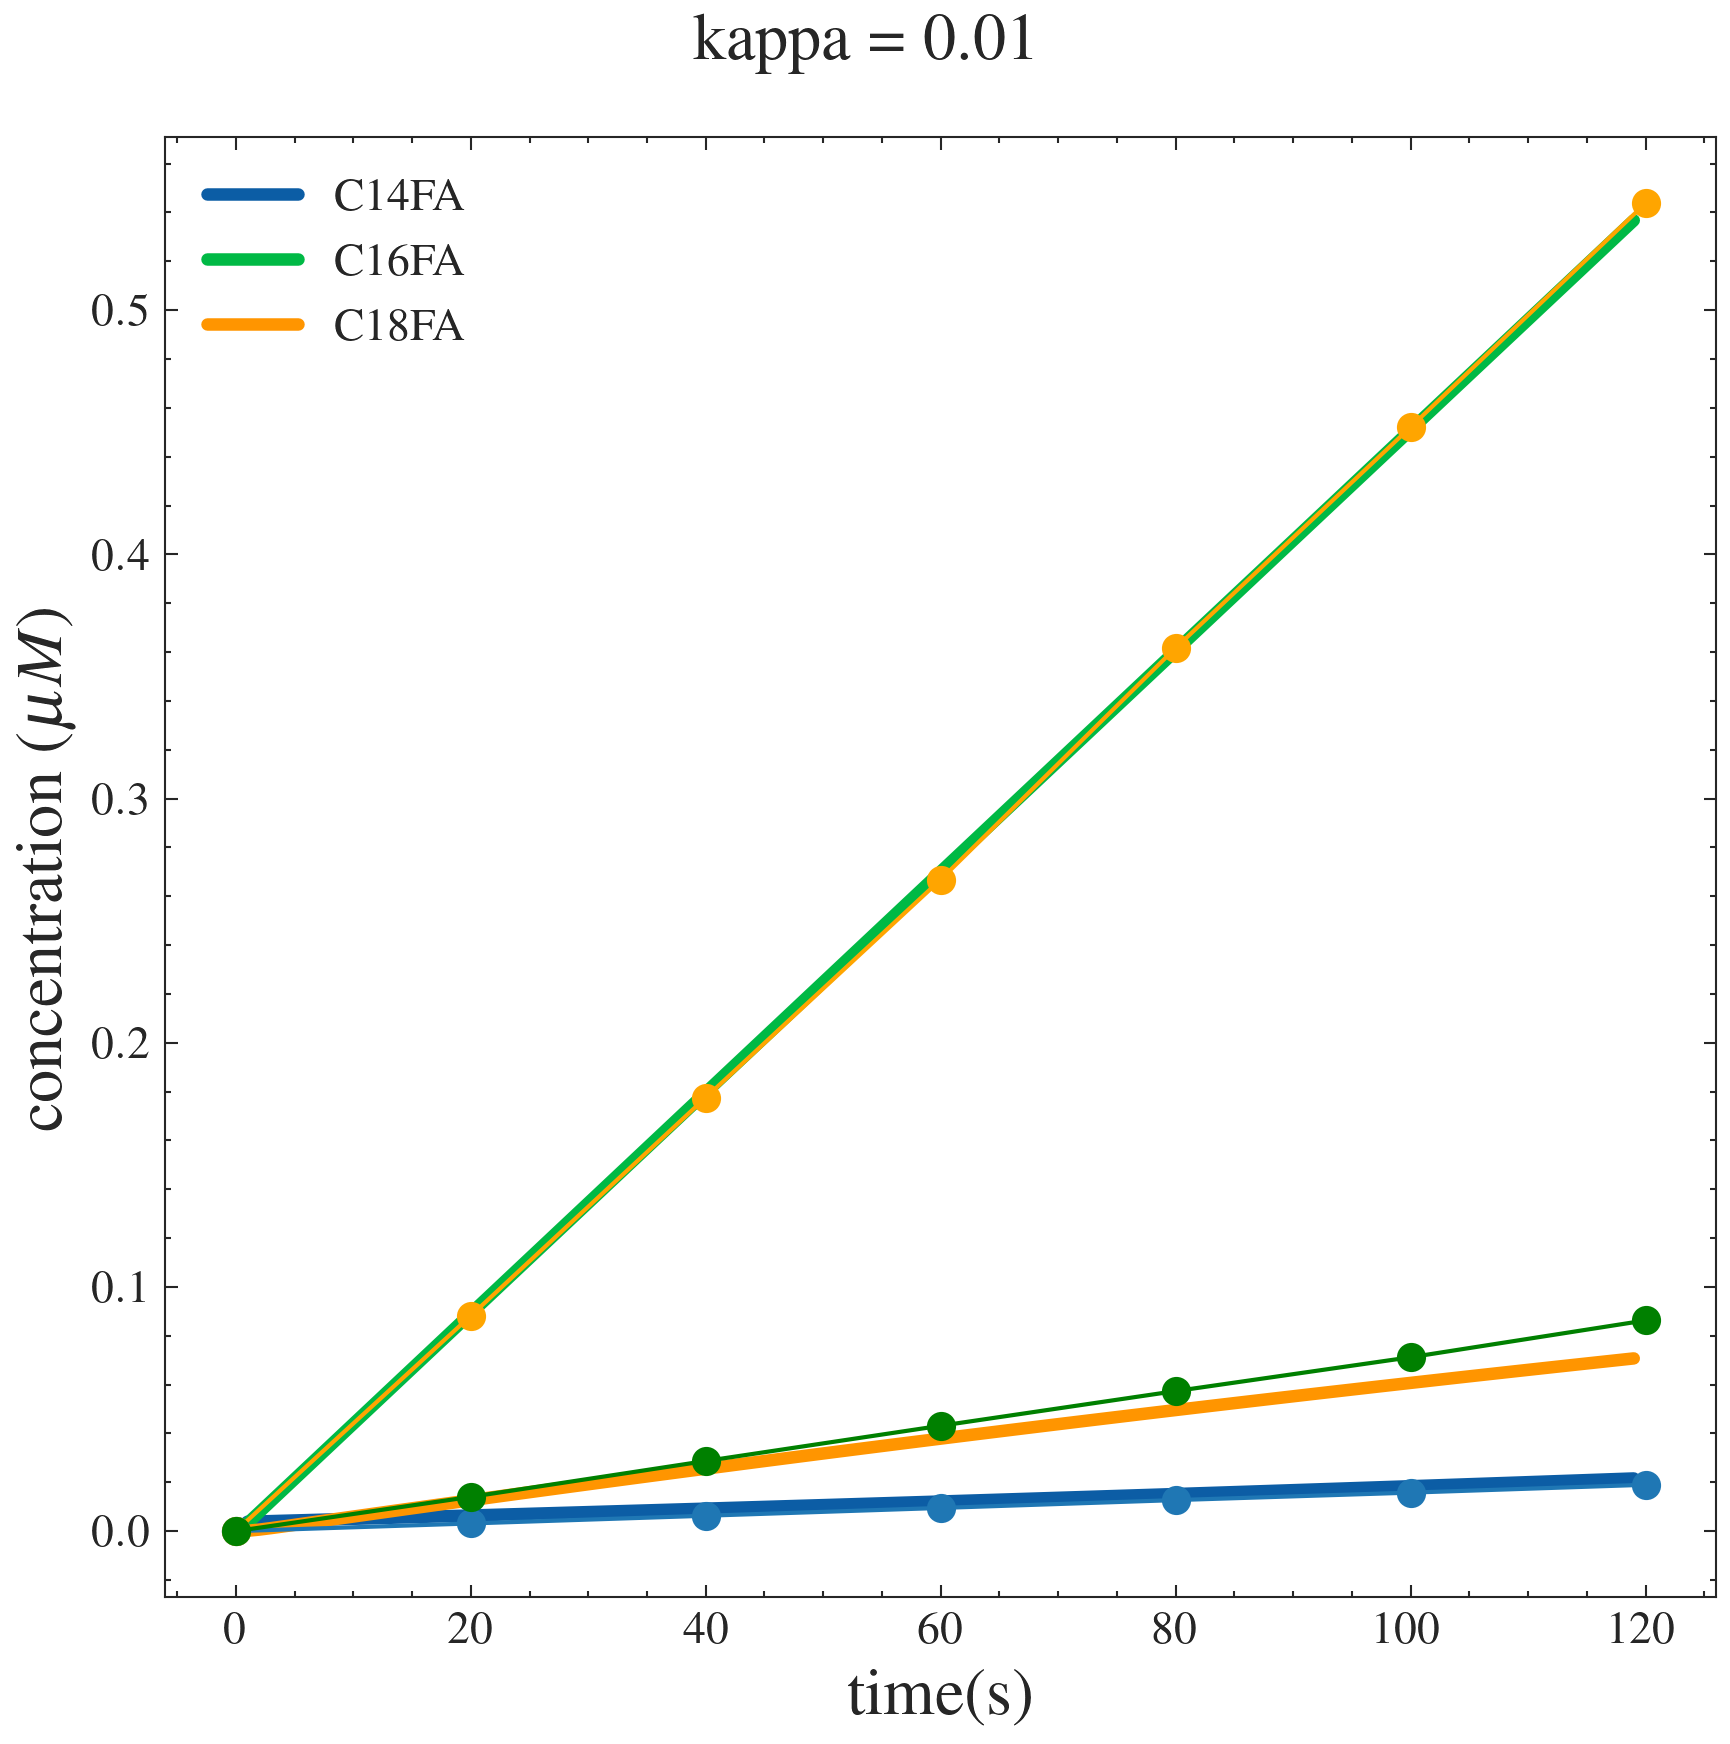

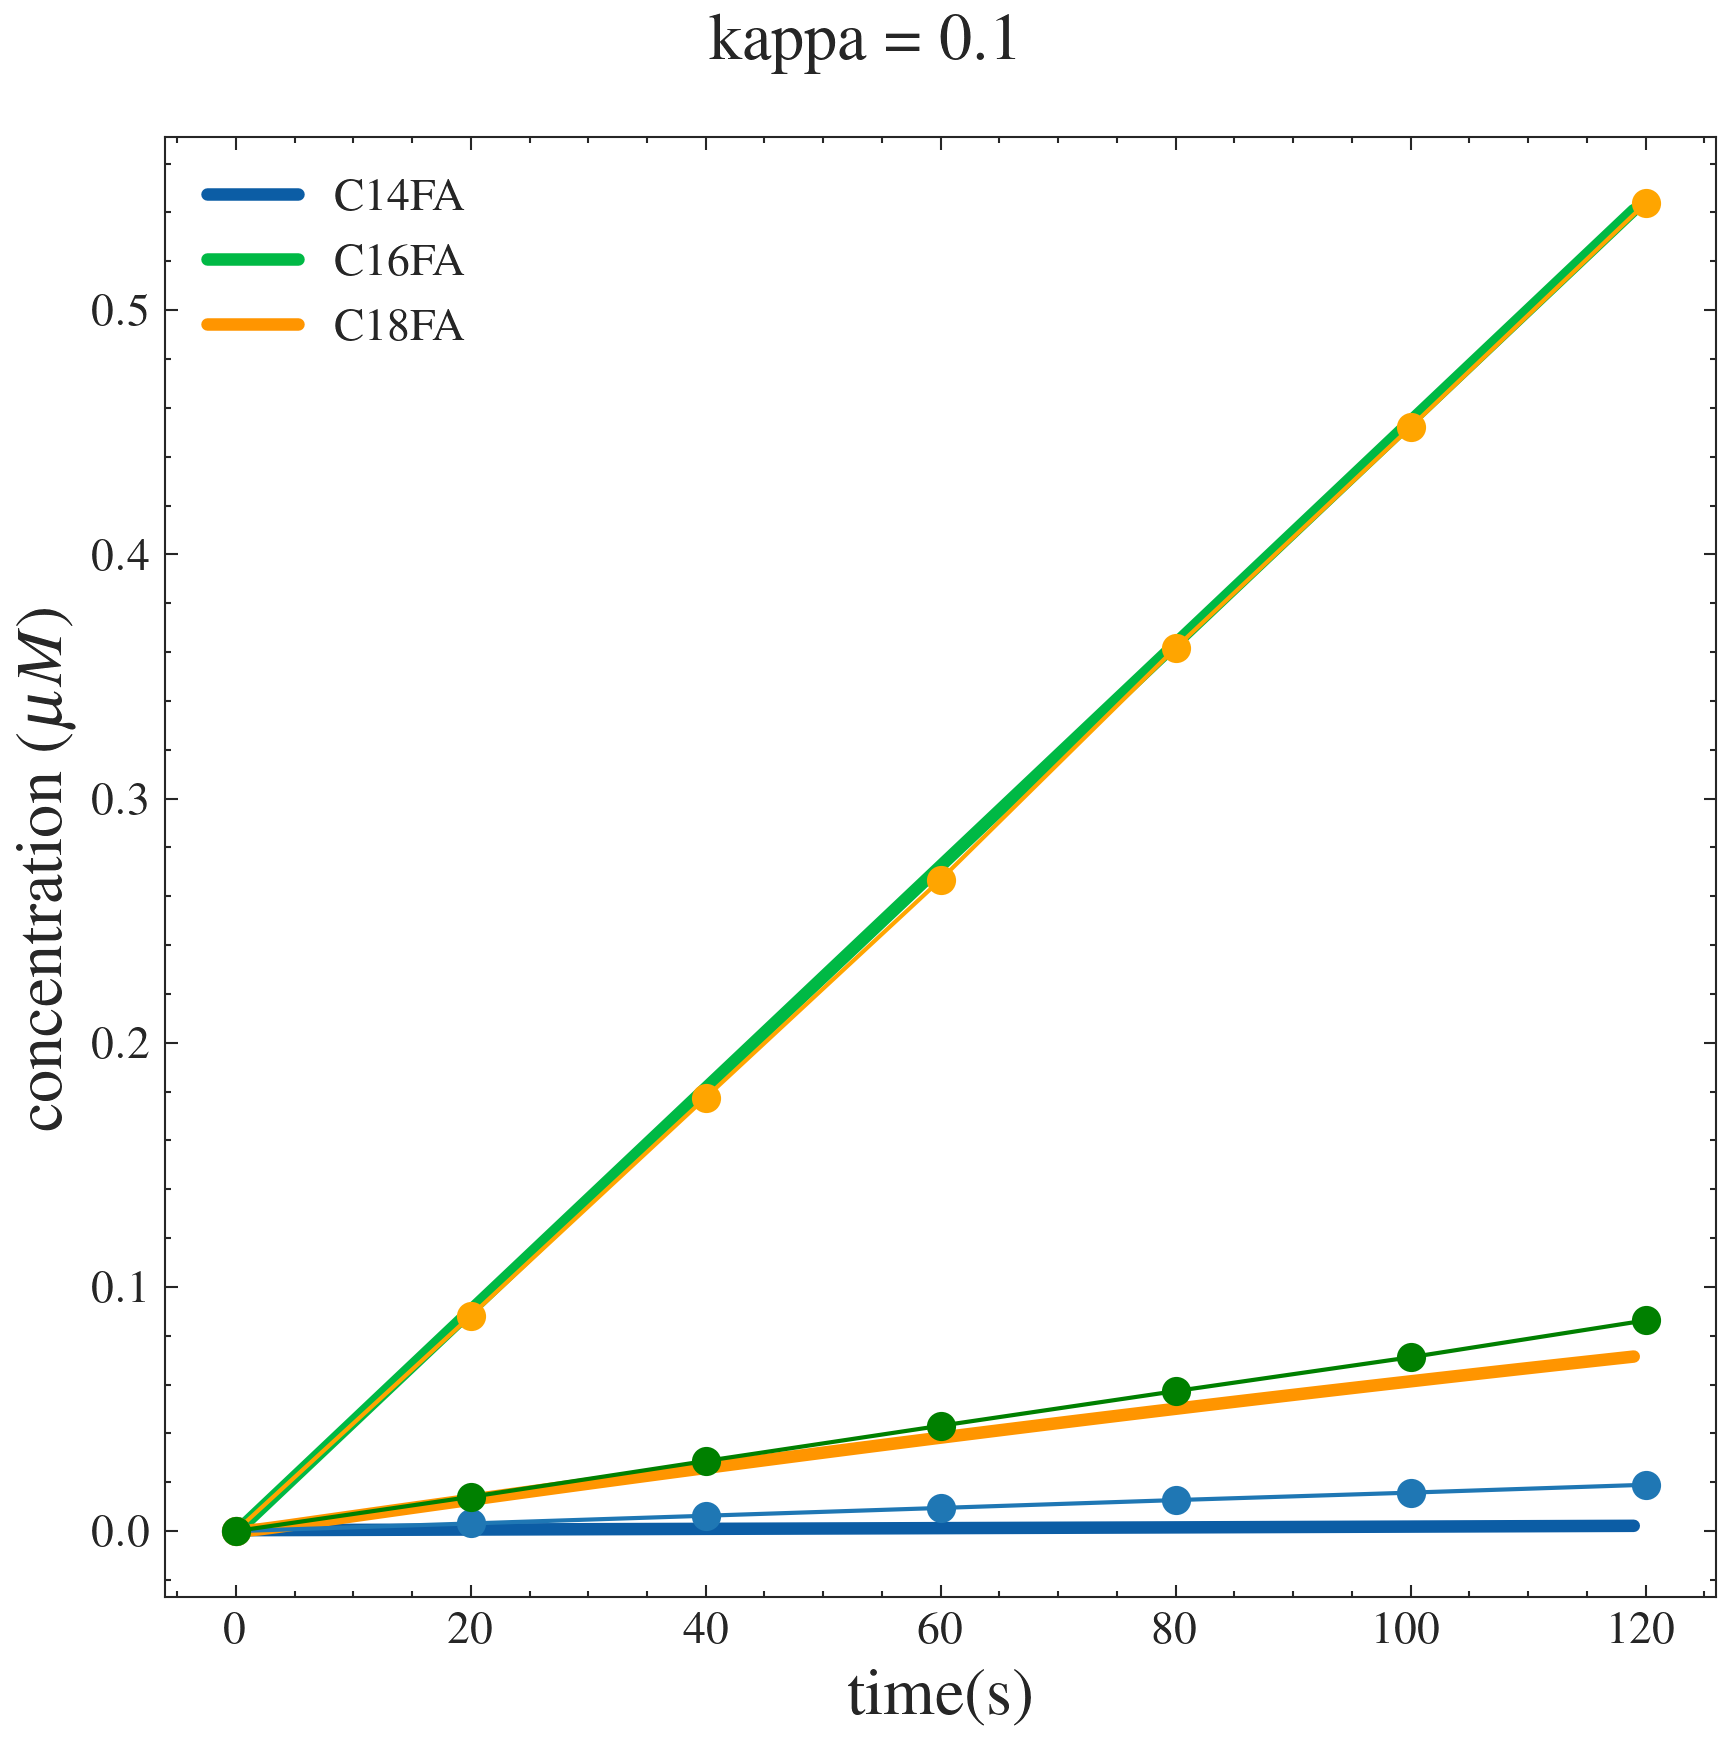

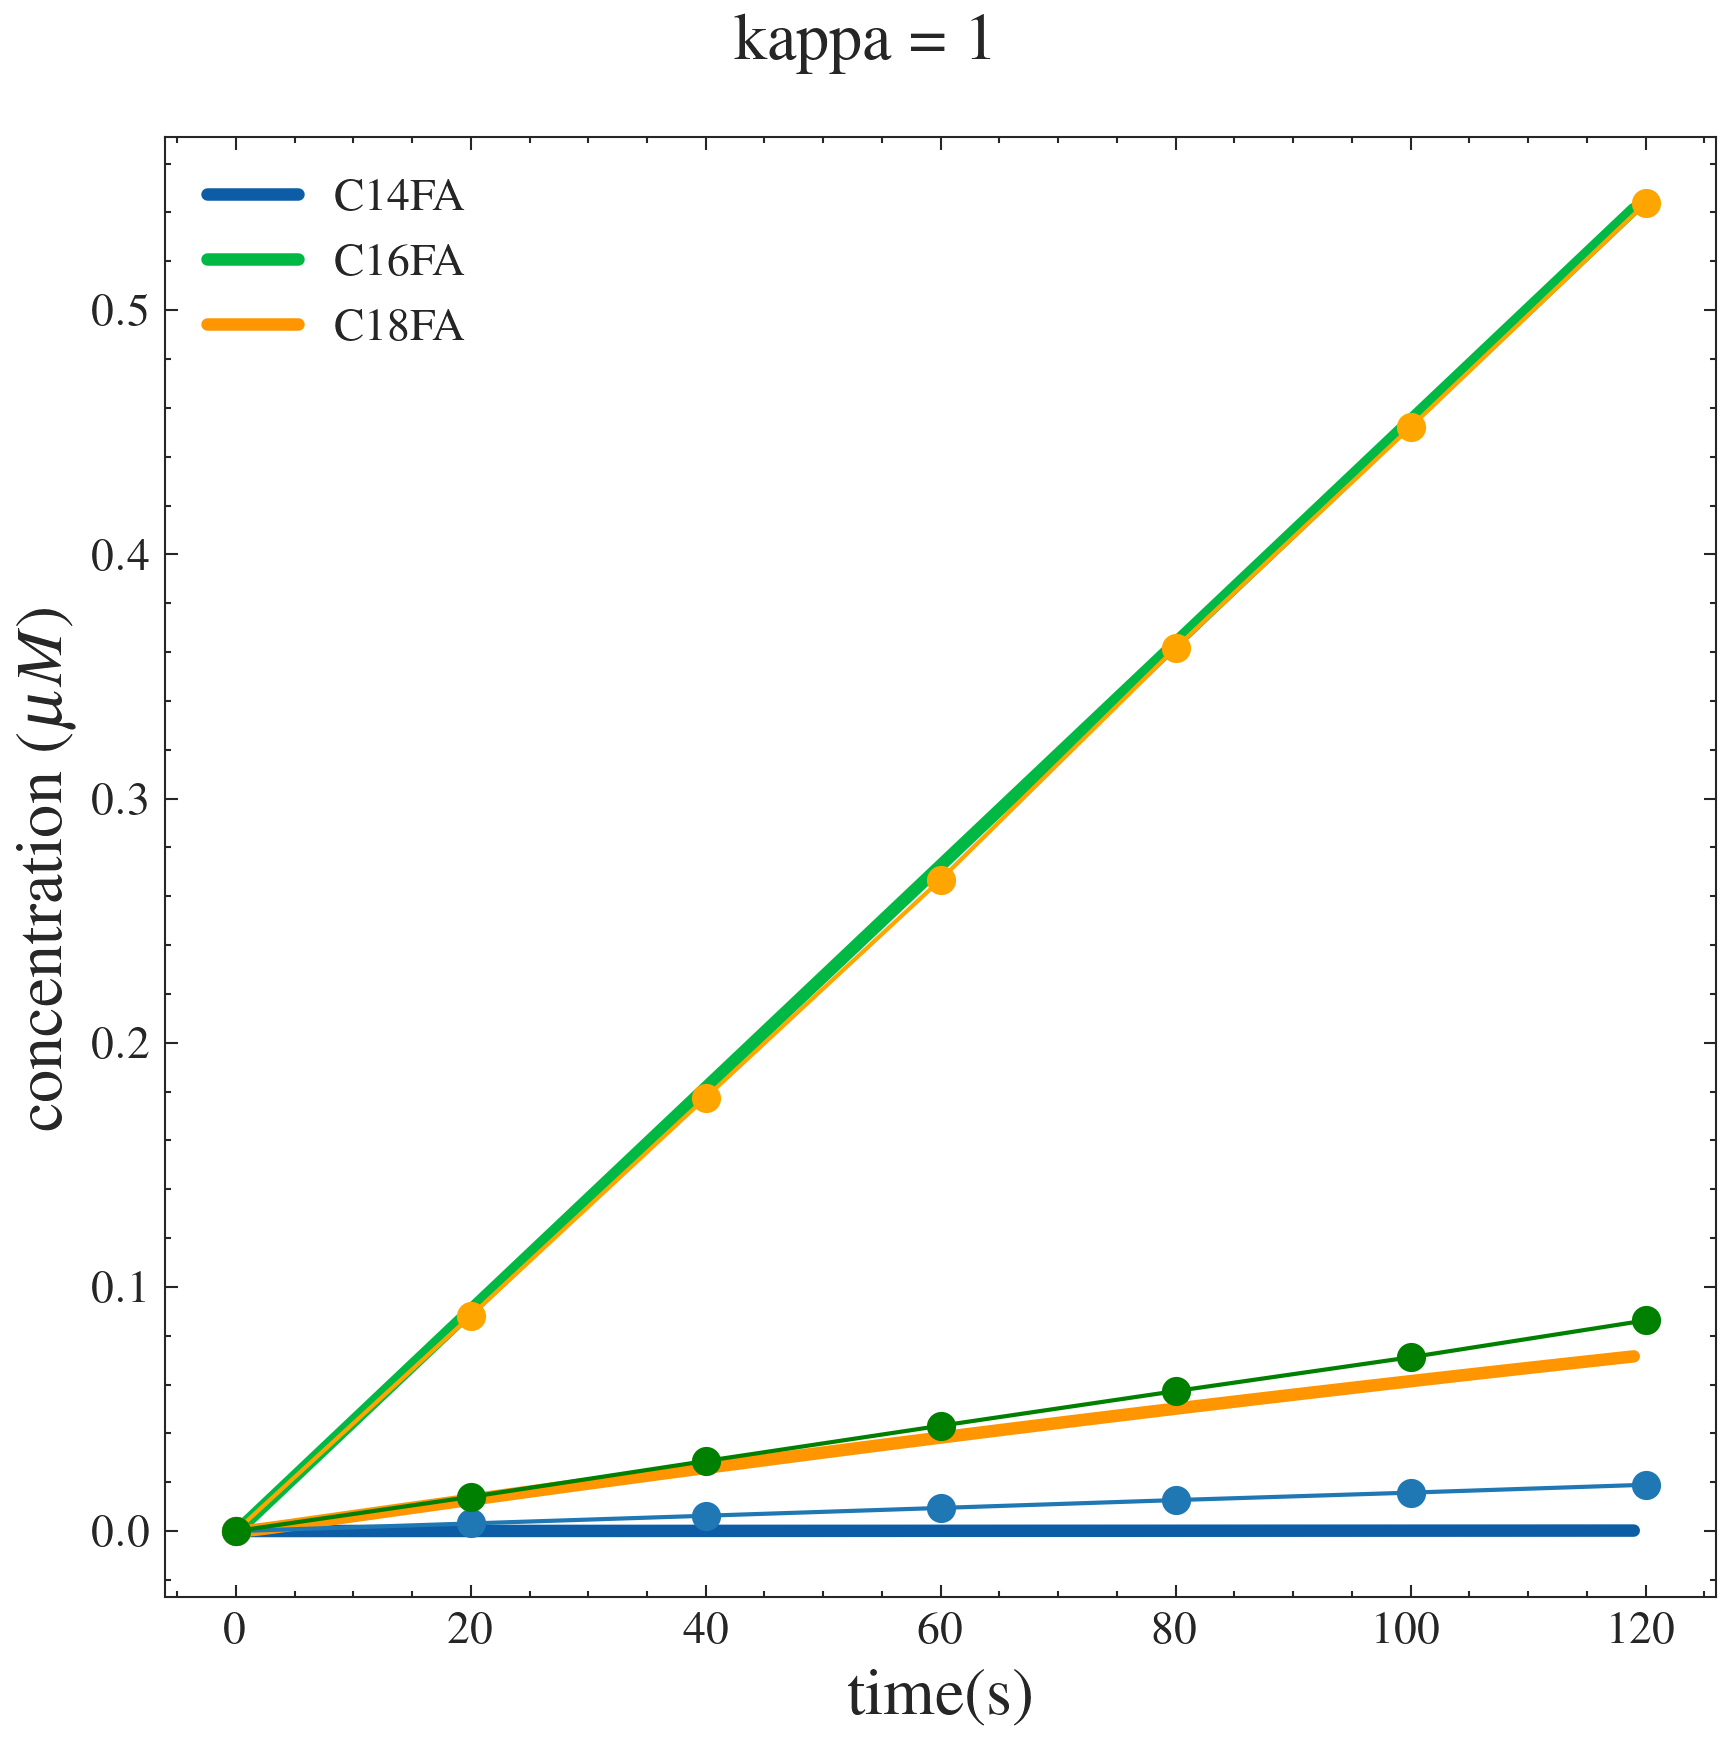

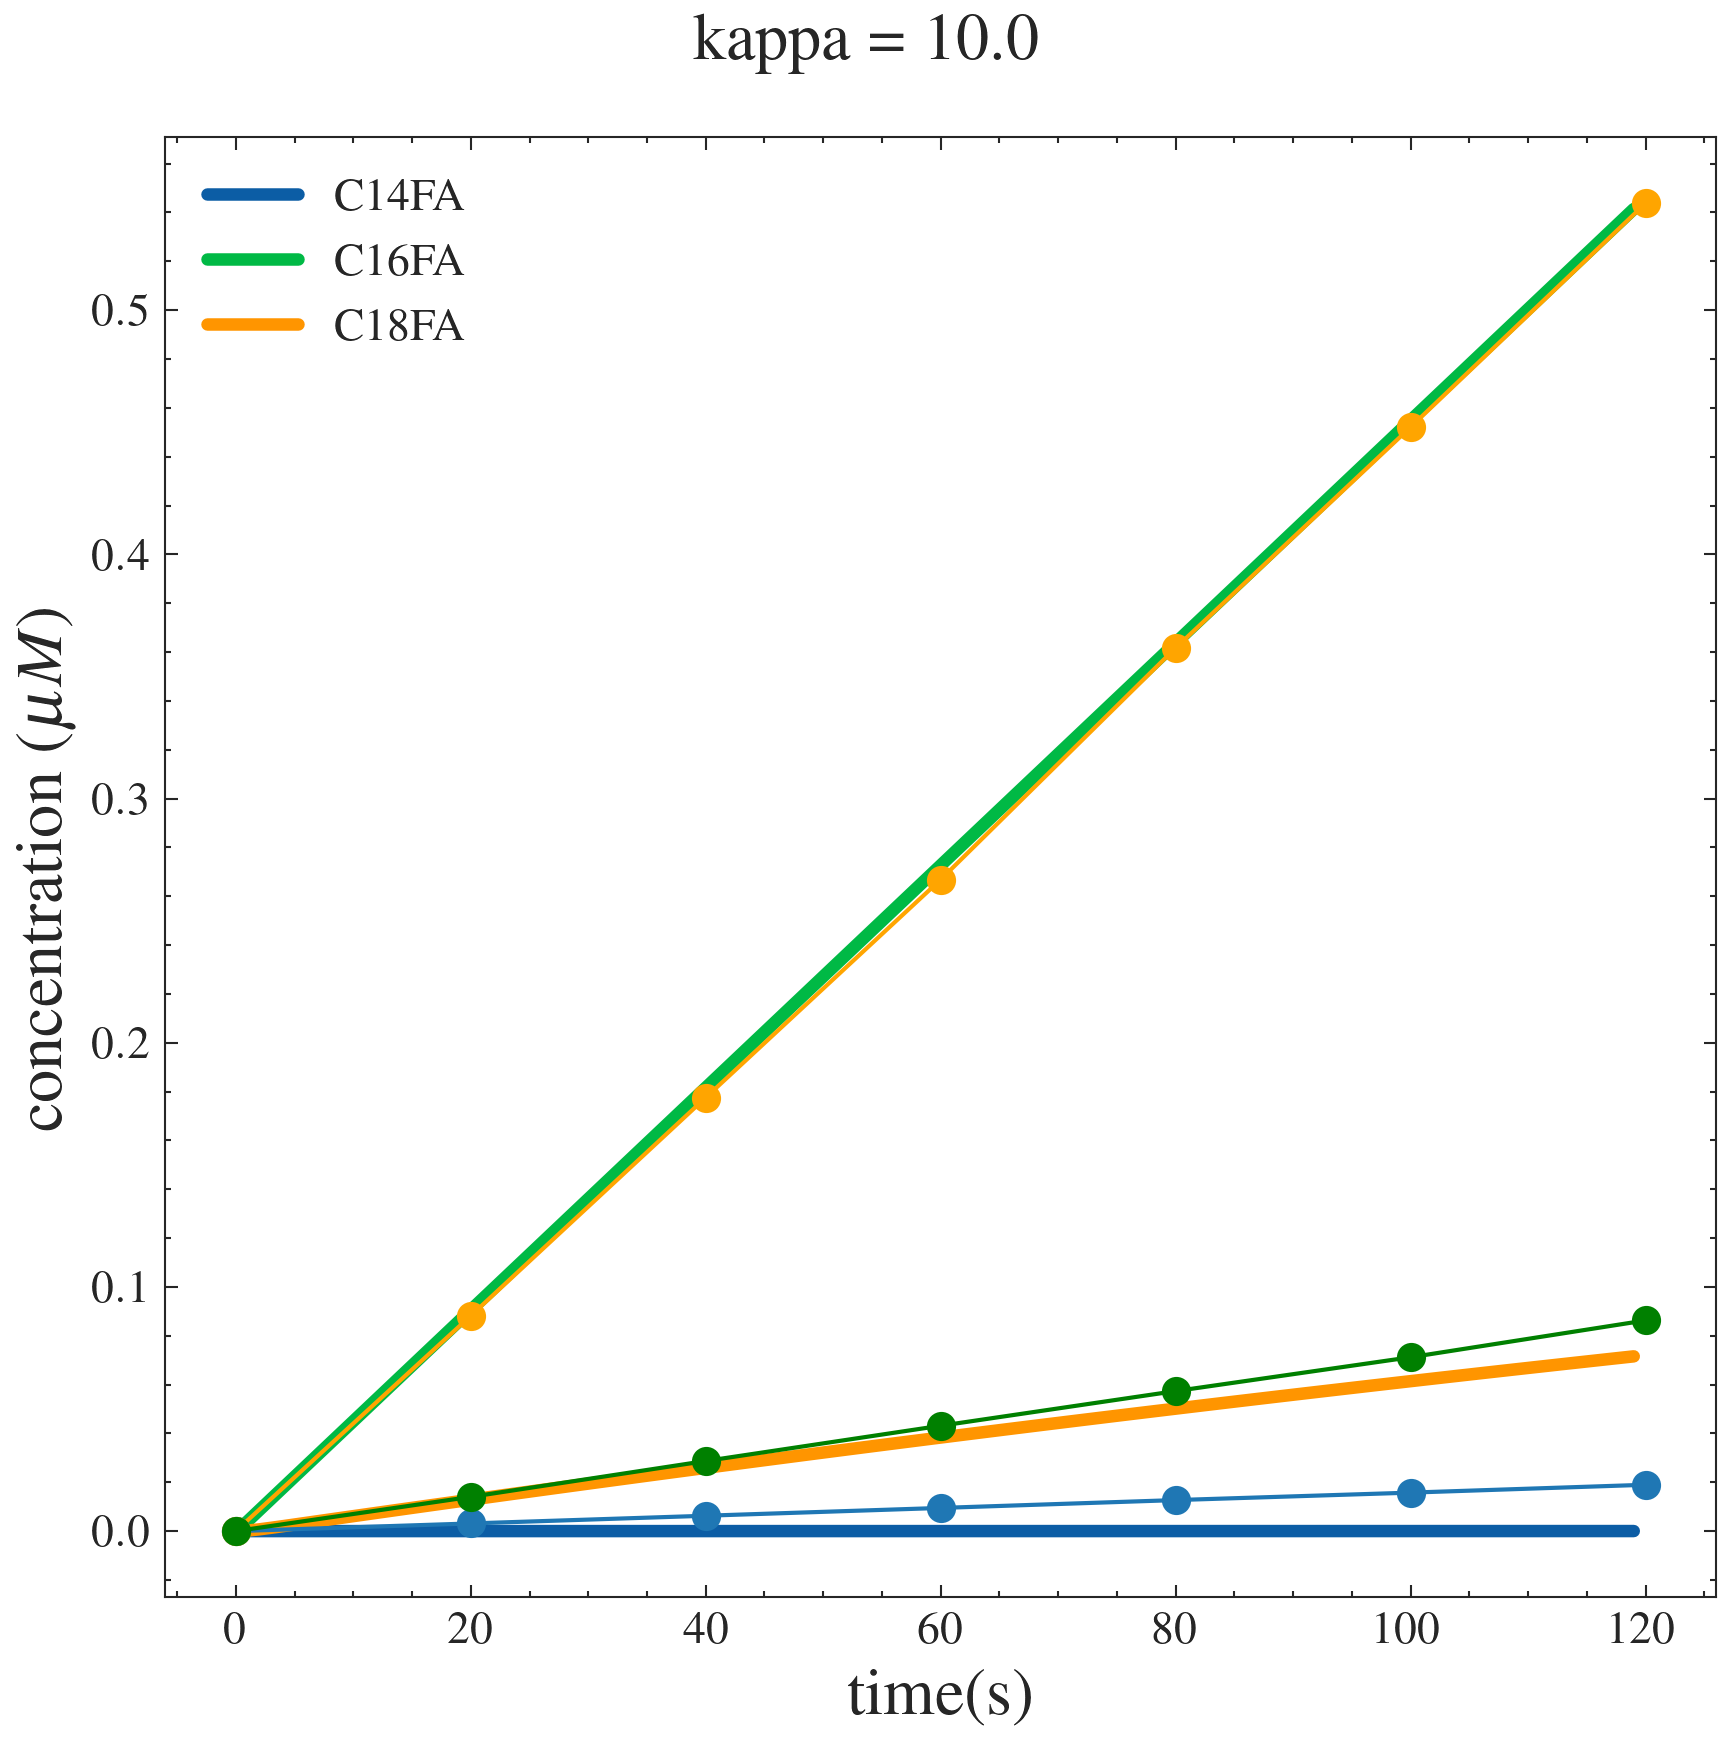

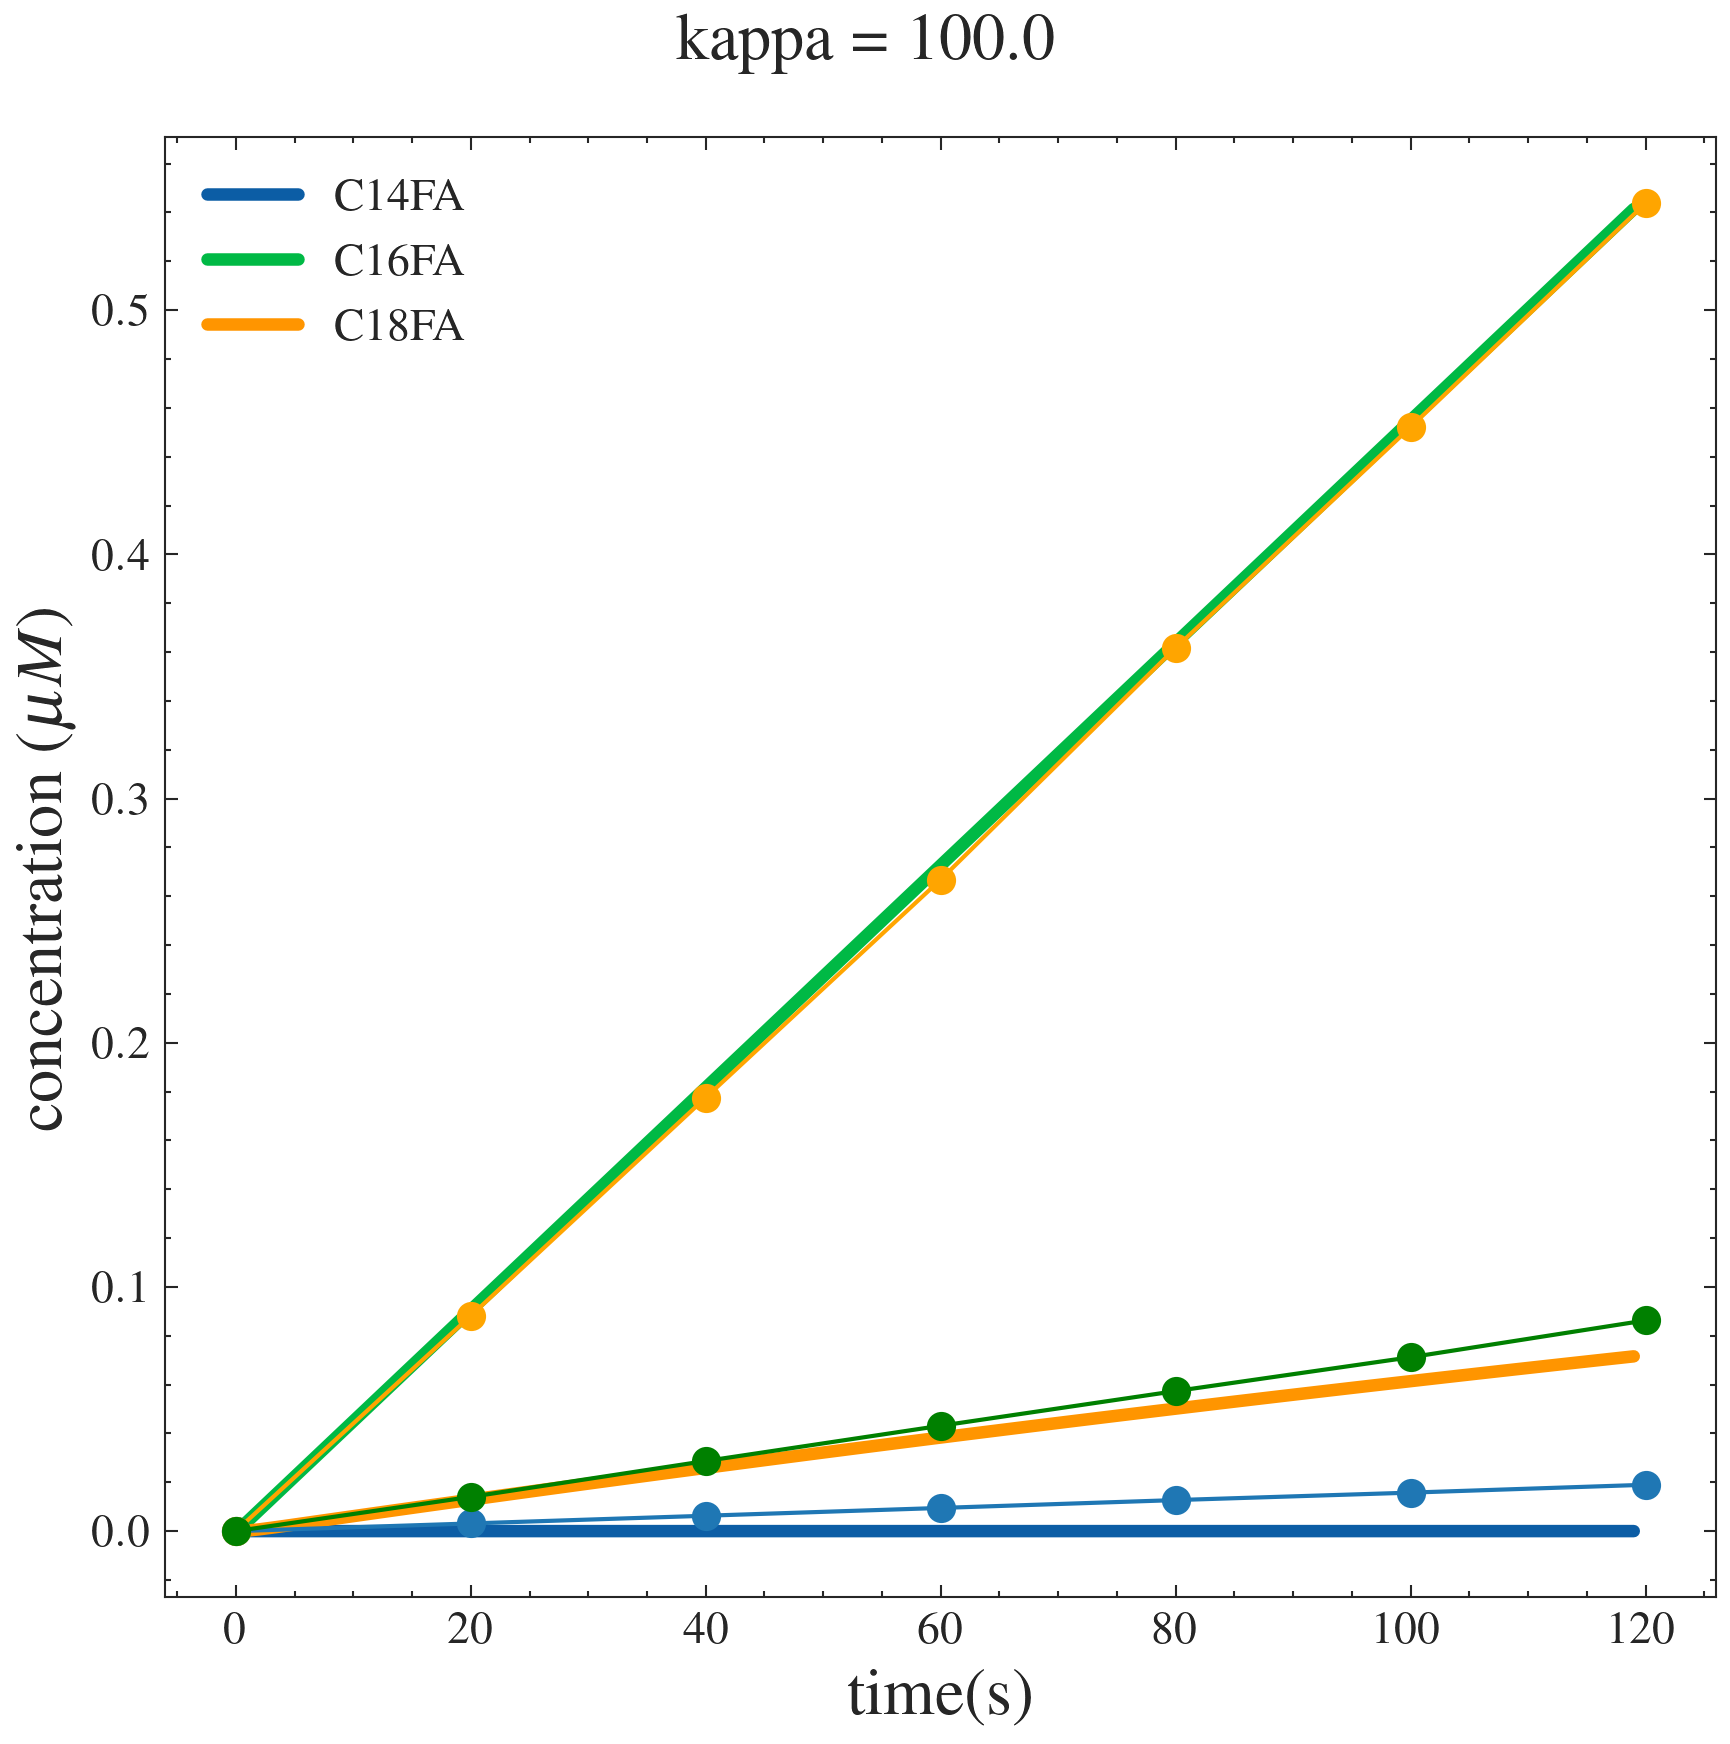

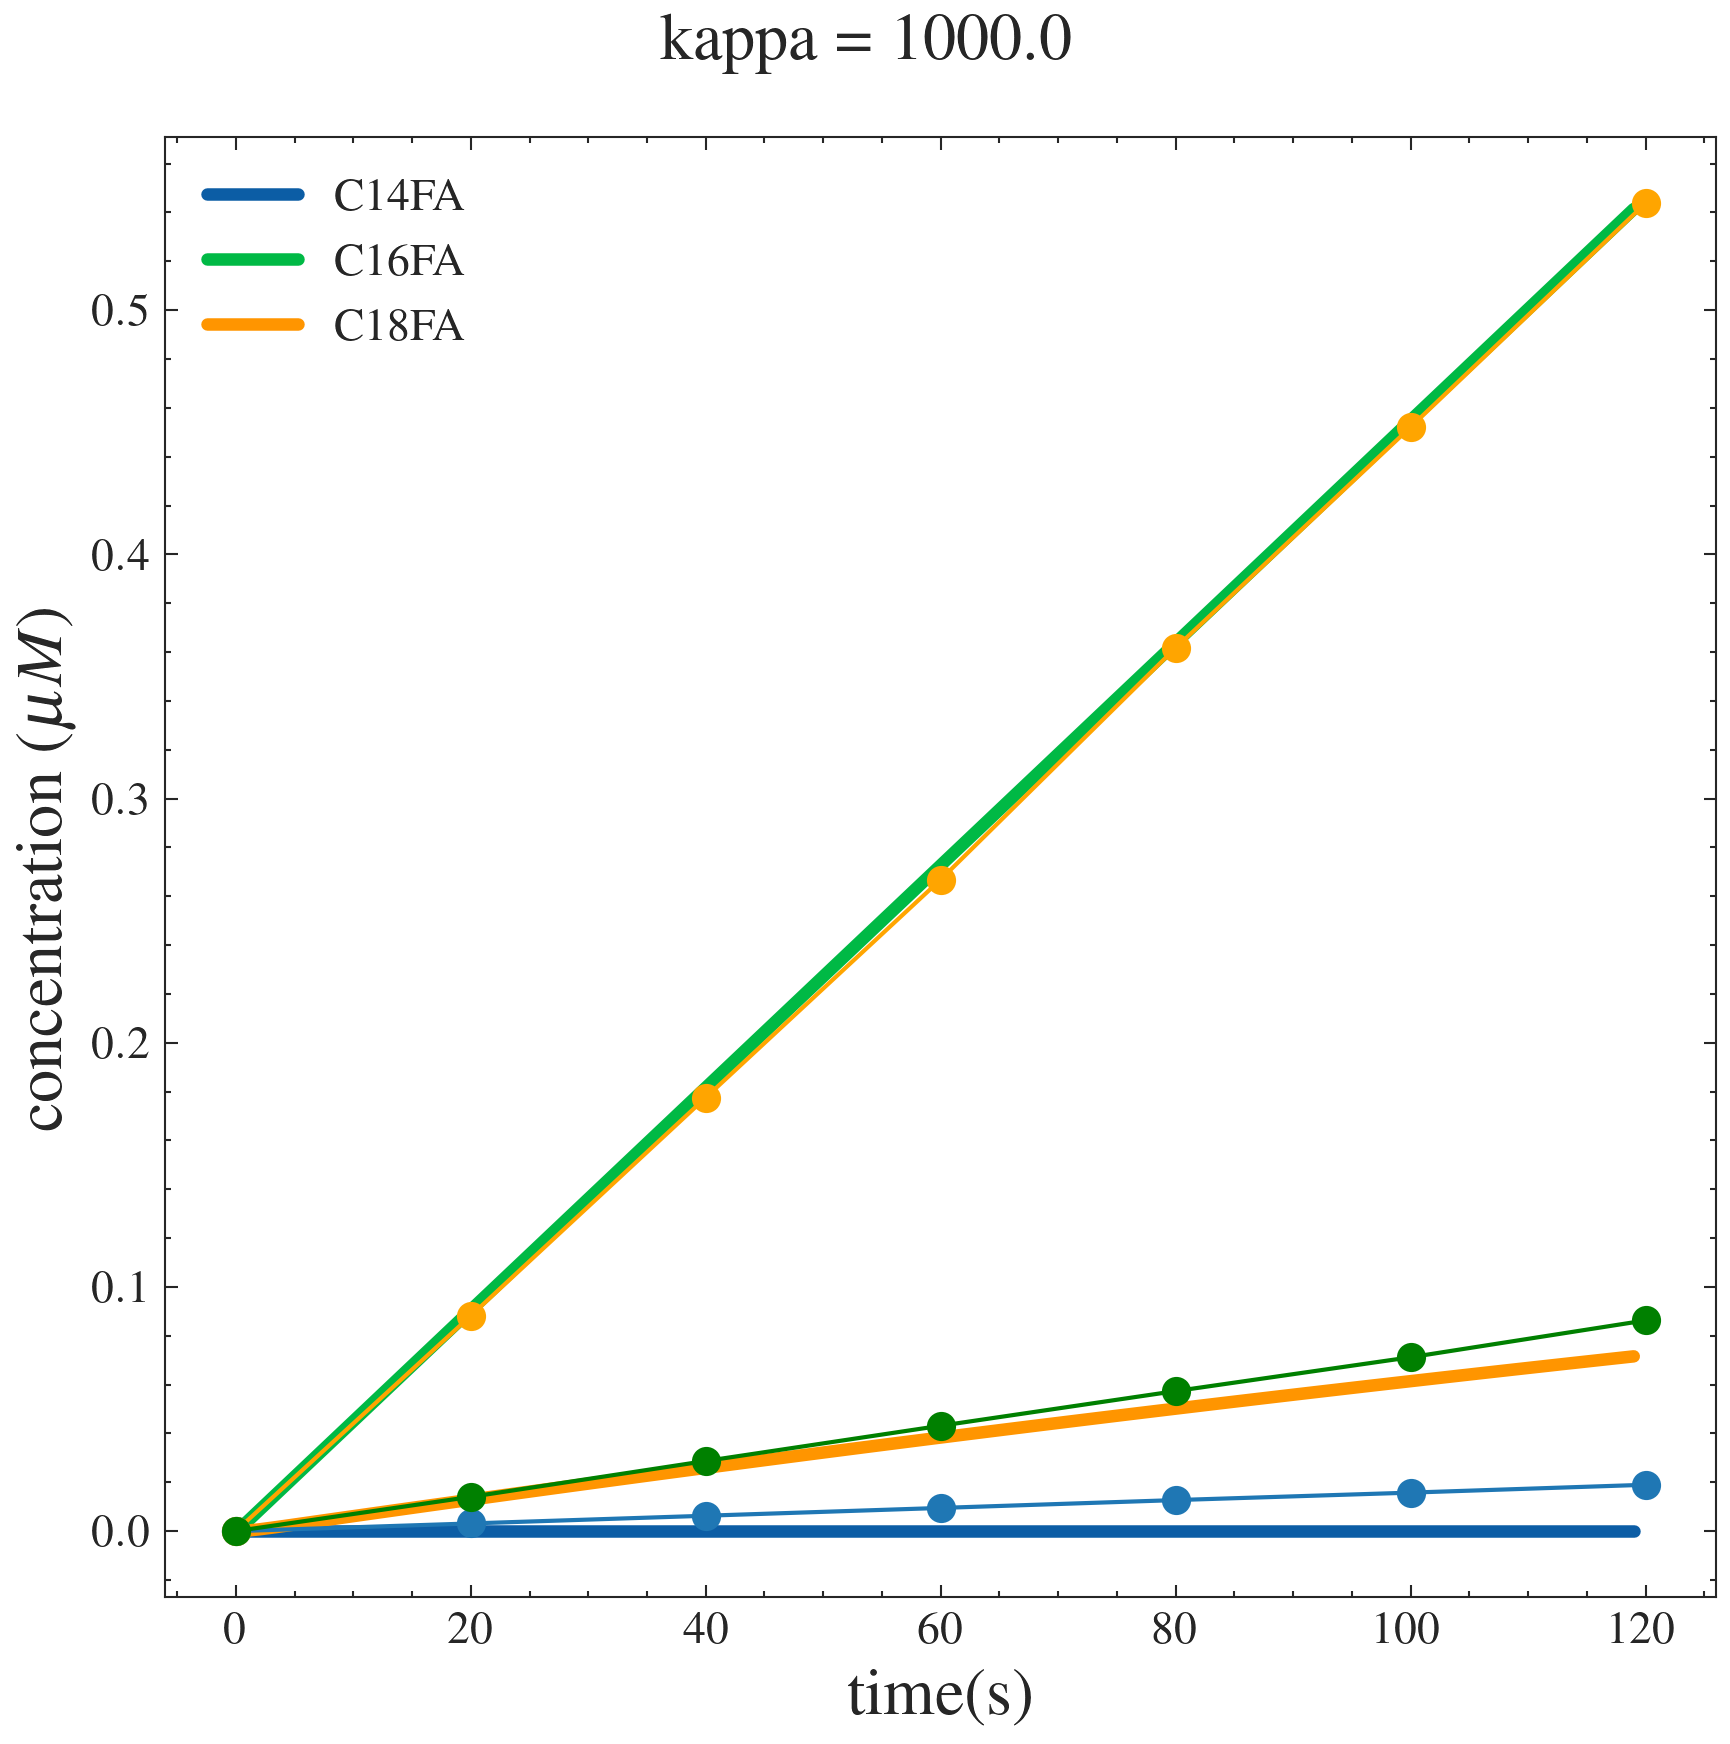

In [157]:
data_interest = [
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]

colors = ["#1f77b4", "orange", "green"]

vals = [1e-3, 5e-3, 1e-2, 1e-1, 1, 1e1, 1e2, 1e3]
par_copy2 = par.copy()
for val in vals:
    par_copy2 ["kappa"] = val
    fig, axs = multi_plot_time_course(
        groups=data_interest,
        func=simulate_time_course,
        model=system,
        y0=y0,
        max_time=max_time1,
        ncp_list=ncp_list1,
        par=par_copy2 ,
        compounds=compounds,
        ncols=1,
        resizer=6,
        sharey=False,
        title=f"kappa = {val}",
        xlabel="time(s)",
        ylabel="concentration ($\mu M$)",
    )
    # adding data to a particular graph
    for i in range(3):
        axs[0, 0].plot(time_initial_phase, data_initial_phase[:, i], "o-", color=colors[i])
        plt.savefig(RESULTS_DIR /f"kappa={val}.png")       
        

## Choice of the parameter $\beta$ and $\kappa$ 

For seeing the impact of the of $\beta$ and $\kappa$  to the initial phase kinetics,  we vary $\beta$   and $\kappa$ between  $10^{-2}$ and $10^3$ . We can see that the value of $\beta$  must be greater that 0.01 $\mu M^{-3}s^{-1}$ and  $\kappa$ greater that $5 \times 10^{-3}$.

- We therefore choose the value of $\beta$ and $\kappa$ to be respectively $1e-1$ and $1e-2$


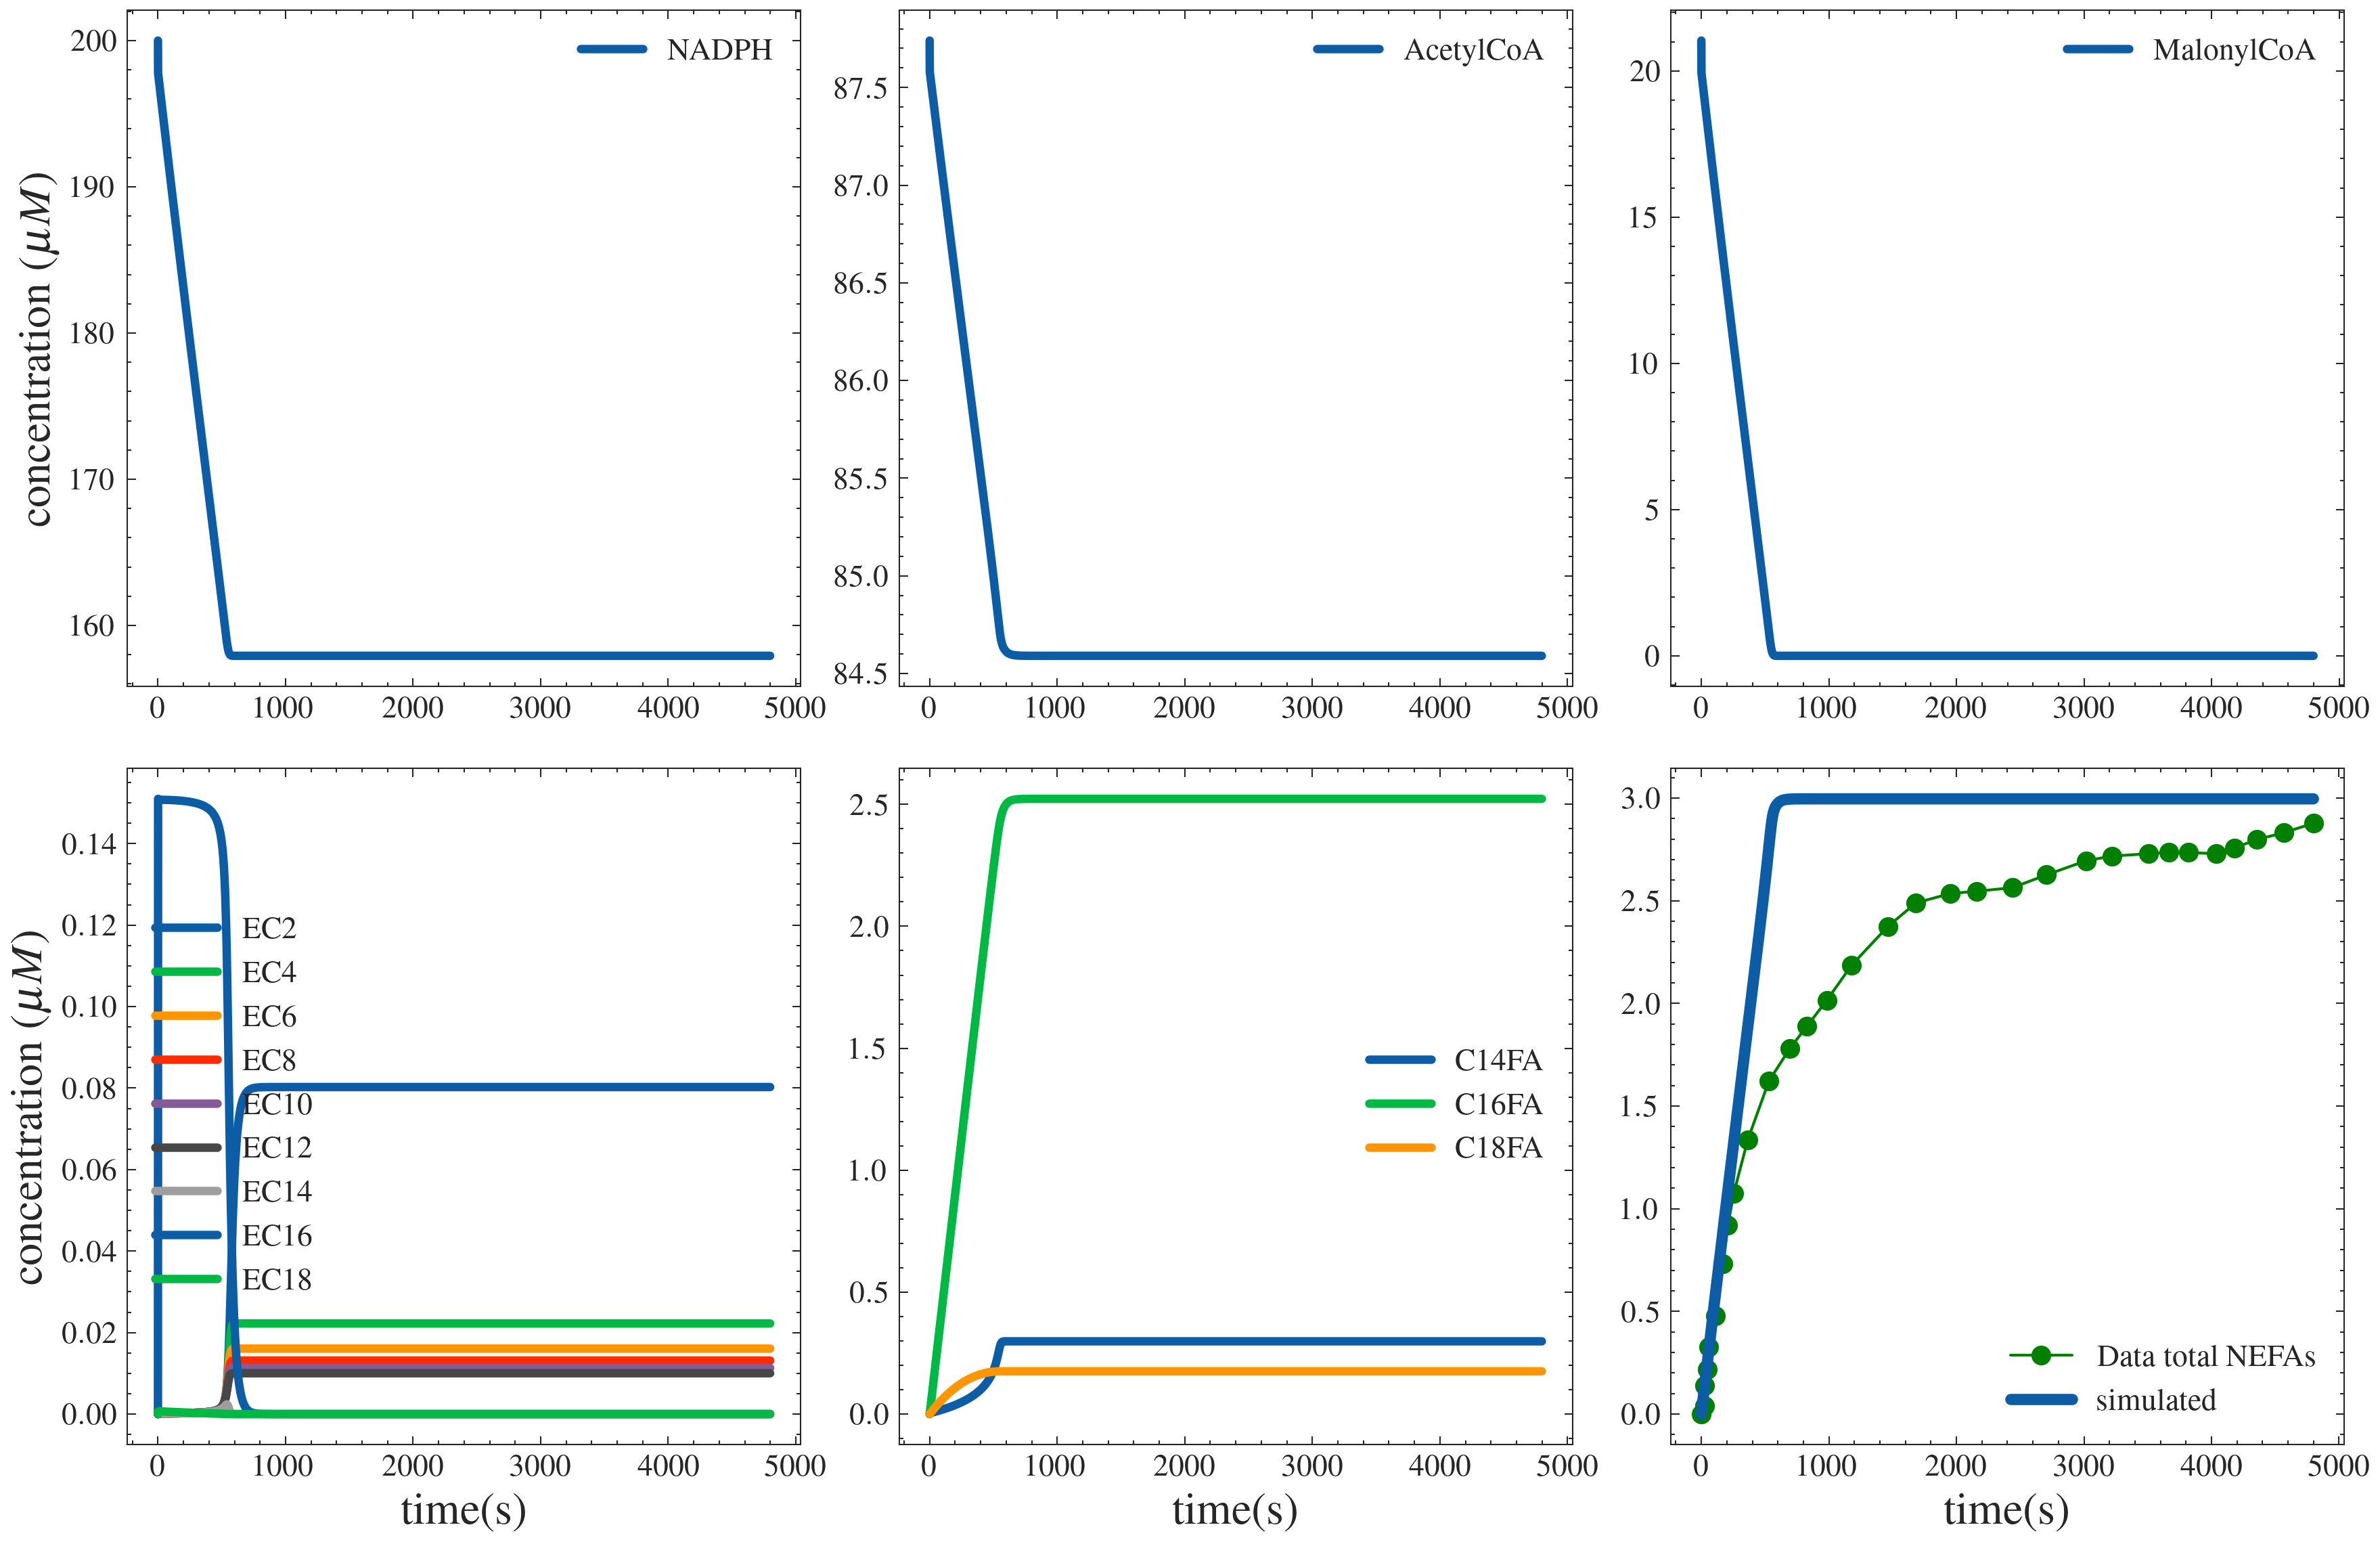

In [158]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title="",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system, par, y0, max_time = time_simulations, ncp_list = ncp_list2)

axs[1, 2].plot(time_simulations, total_nefas1,  "o-", color=colors[i])
axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
axs[1, 2].legend(
    [
    "Data total NEFAs",
    "simulated"
    ],

)

## Remarks


- From the above plots, we can see that the chosen  parameters for  initial phase does not capture the transient phase. Furthermore, The value of $k_{d6}$ $k_{d8}$ still have to be adjusted. 
- Additionally we can observed that right after the initial phase the production of C14 is exponential, which should not be the case.  
- Besides the above remarks, we can see that, here the steady state is reached when the malonyl-CoA is depleted. and this happening too quick. 




# Fitting  for the three different types of NEFAs
Giving that we calculated the value of  some parameters from experimental data, notably the value of $K_{d7}$, $\delta$ under rapid binding considerations(Indeed the substrates are in excess). We now fit others parameters to initial phase data. 

# Interpolation to have  more points 
We are not intending to create fake data or add information do experimental data, we only interpolate data points for the stabilty of the fitting.

#

In [159]:
time_interp = np.linspace(0, time_initial_phase[-1], 20) #20 data points between 0 and 120 secs.


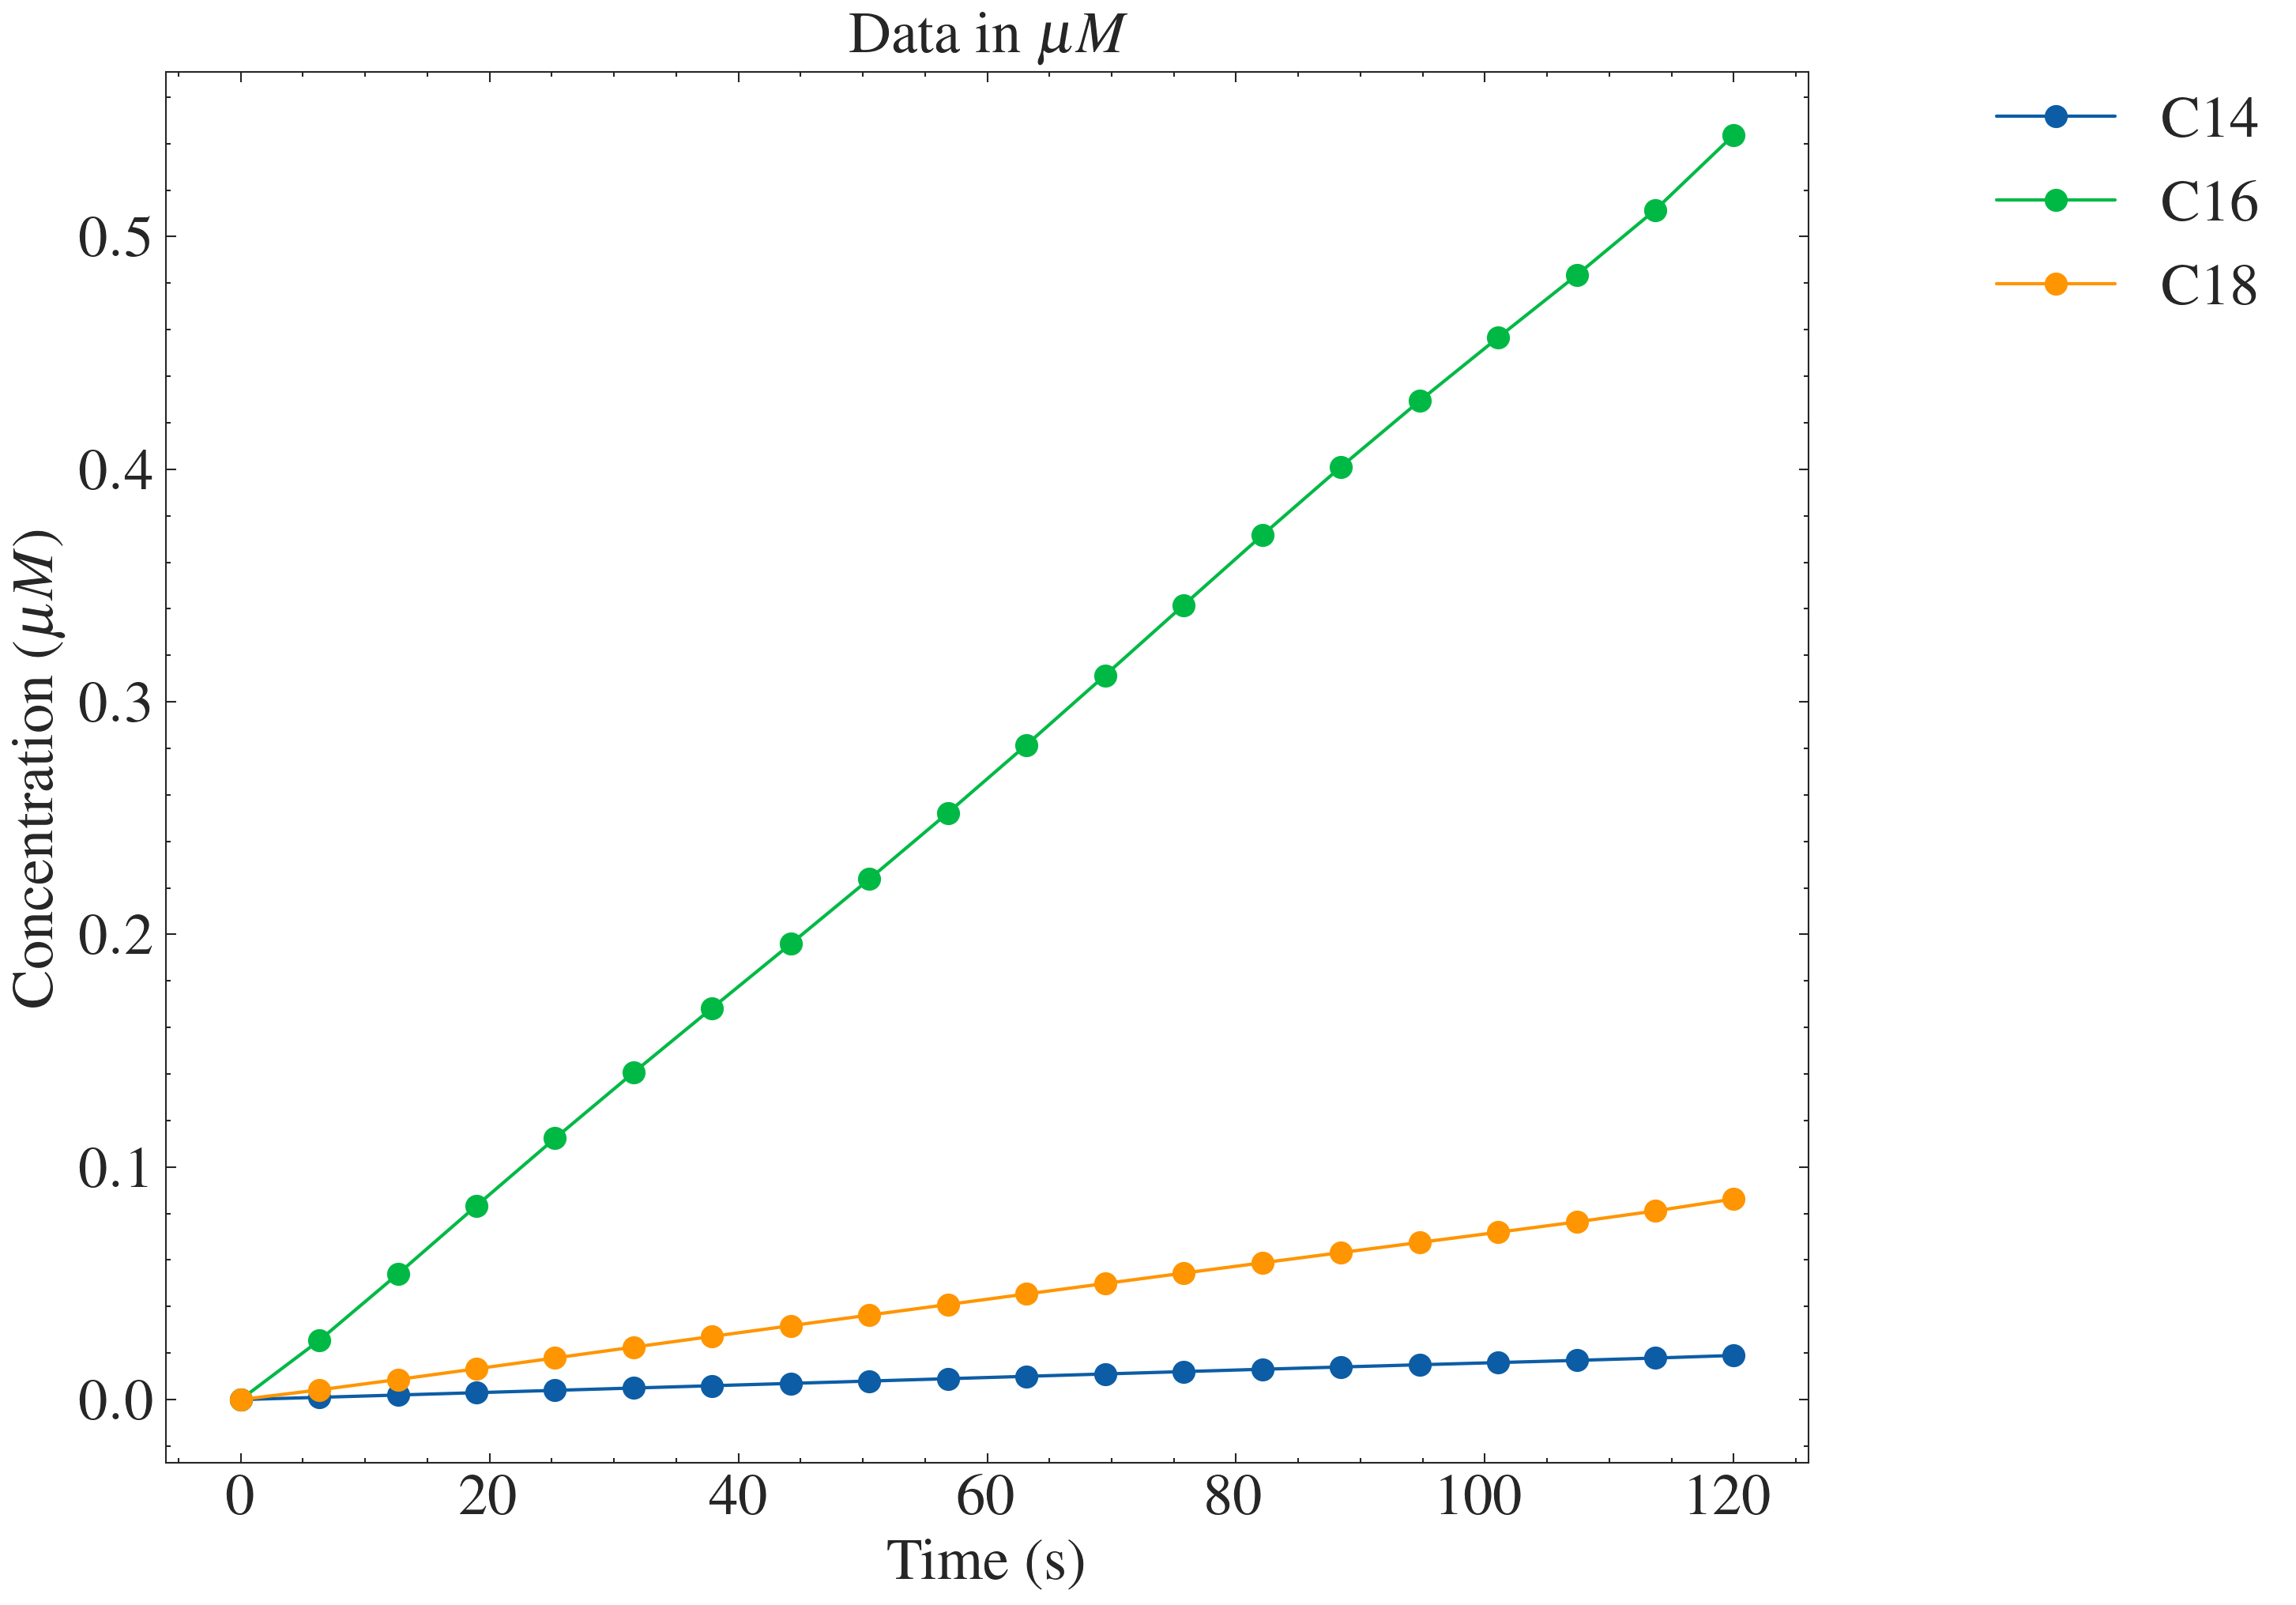

In [160]:
#use of lagrange interporlation to create more data point linearly

lagrange_interpolation_C14 = lagrange(time_initial_phase, data_initial_phase[:,0])
lagrange_interpolation_C16 = lagrange(time_initial_phase, data_initial_phase[:,1])
lagrange_interpolation_C18 = lagrange(time_initial_phase, data_initial_phase[:,2])

C14_data= lagrange_interpolation_C14(time_interp)
C16_data= lagrange_interpolation_C16(time_interp)
C18_data= lagrange_interpolation_C18(time_interp)

data_to_fit = np.array([ C14_data, C16_data, C18_data]).T


fig, ax = plt.subplots(figsize=(10, 7))
plt.plot(time_interp, data_to_fit,'o-', linewidth=1)

plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concentration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["C14","C16", "C18"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0, fontsize =18)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()

In [161]:
# residual function to be passed to lmfit library 
# The function *fatty_acid_of_interest* solves the system and only returns  C14, C16 and C18.

#This residual function can oly be used for fitting the inital phase

def residual(parameters, max_time, time, data):
    y0[1] = parameters["y0_mal"].value
    #print(y0)
    model = fatty_acid_of_interest(system, parameters, y0, max_time = max_time , ncp_list = time)
    res = (model - data).ravel()
    
    
    return res

 

In [162]:
par_to_fit = Parameters()
par_to_fit.add("beta", value=1e-01, min =0.01)
par_to_fit.add("kappa", value=1e-2, min =5e-3)
par_to_fit.add(
    "delta",
    value=1.17e-06,
    vary=False,
)
# par_to_fit.add("kd1", value=0, vary=False)
# par_to_fit.add("kd2", value=0, vary=False)
# par_to_fit.add("kd3", value=0, vary=False)
# par_to_fit.add("kd4", value=0, vary=False)
# par_to_fit.add("kd5", value=0.0, vary=False)
par_to_fit.add("kd6",value=1,vary =False,)
par_to_fit.add("kd7", value=0.03, vary = False)
par_to_fit.add("kd8", value=1, vary = False)
par_to_fit.add("y0_mal", value=21.04, vary=False)




In [163]:
result = minimize(residual, par_to_fit, args=(time_interp[-1], time_interp, data_to_fit), method="leastsquare")
final = data_to_fit + result.residual.reshape(data_to_fit.shape)
final.shape


(20, 3)

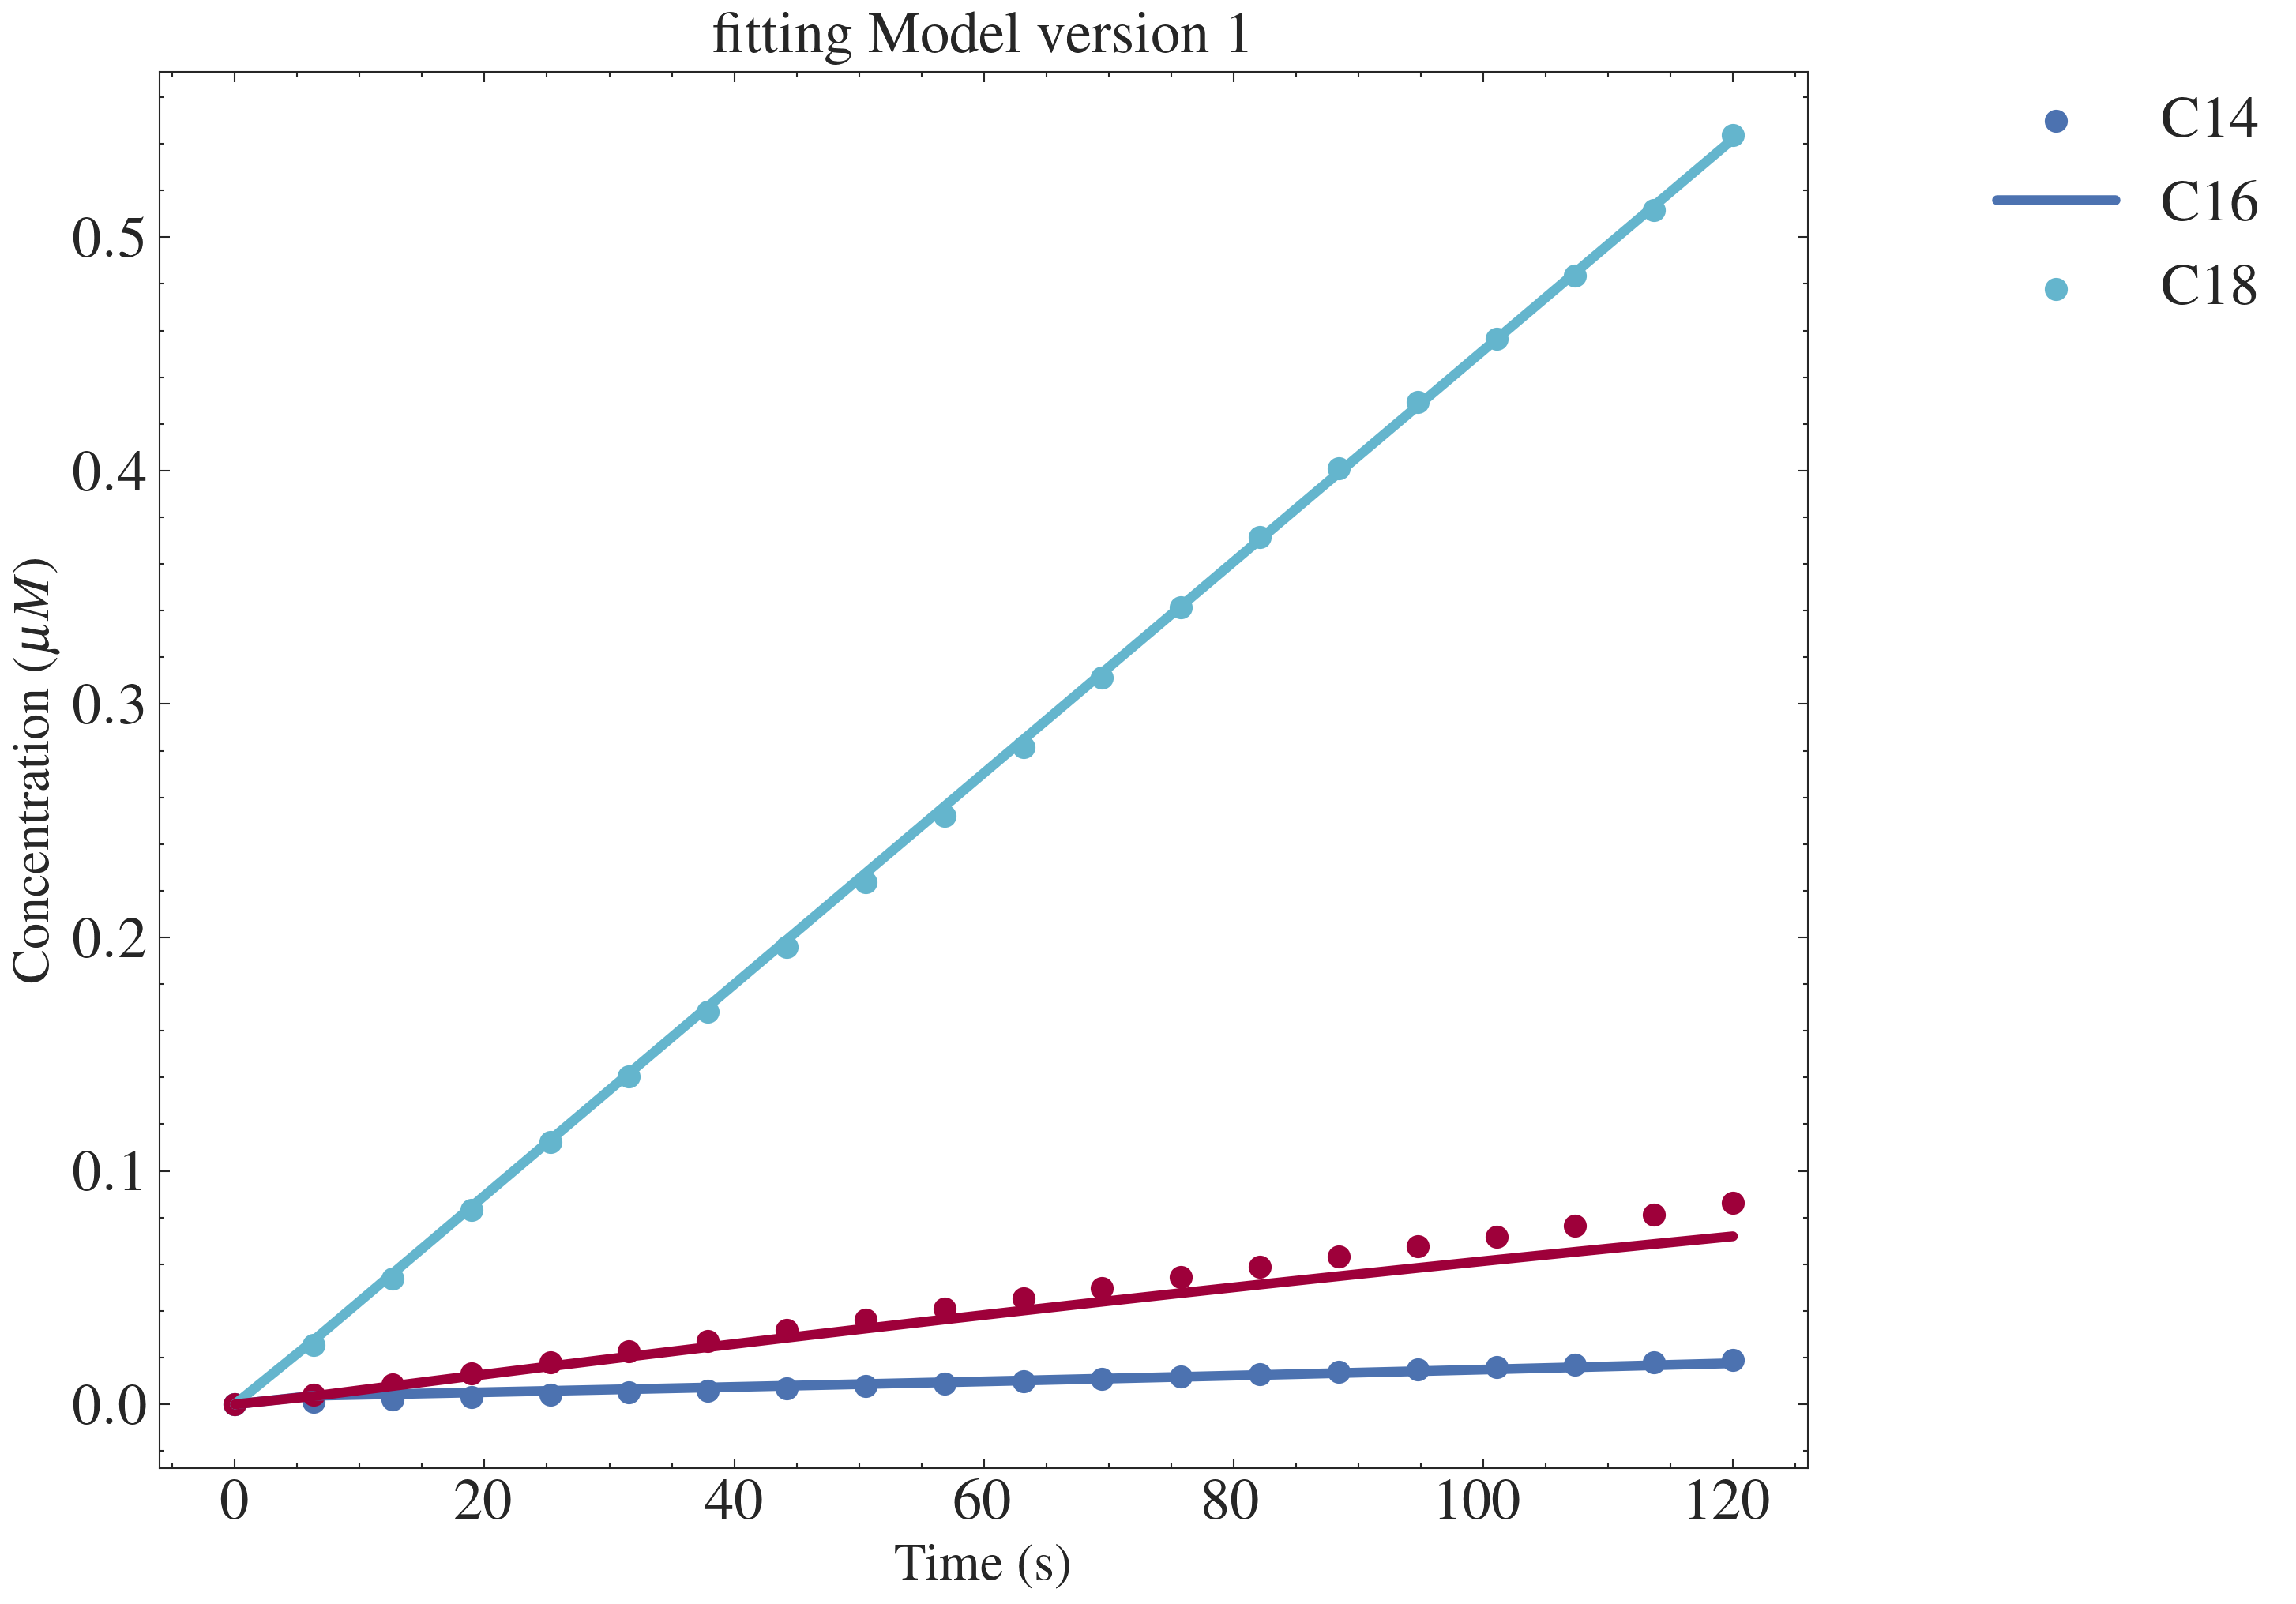

In [164]:
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_interp, data_to_fit[:, i], color=color[i][0], marker='o')
    ax.plot(time_interp, final[:, i], color=color[i][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["C14","C16", "C18"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0, fontsize =18)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"initial.png", bbox_inches="tight")
plt.show()

In [165]:
report_fit(result)

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 13
    # data points      = 60
    # variables        = 2
    chi-square         = 0.00107976
    reduced chi-square = 1.8617e-05
    Akaike info crit   = -651.521650
    Bayesian info crit = -647.332961
[[Variables]]
    beta:    0.09406829 +/- 0.05033678 (53.51%) (init = 0.1)
    kappa:   0.01237778 +/- 0.00109025 (8.81%) (init = 0.01)
    delta:   1.17e-06 (fixed)
    kd6:     1 (fixed)
    kd7:     0.03 (fixed)
    kd8:     1 (fixed)
    y0_mal:  21.04 (fixed)
[[Correlations]] (unreported correlations are < 0.100)
    C(beta, kappa) = -0.173


The step of fitting the $\beta$ and $\kappa$ confirm that we choosed the value in the "right" intervals. 

In [166]:
par_copy = dict(result.params.valuesdict())
par_copy

{'beta': 0.09406828863211825,
 'kappa': 0.012377781645655062,
 'delta': 1.17e-06,
 'kd6': 1,
 'kd7': 0.03,
 'kd8': 1,
 'y0_mal': 21.04}

## Remark 
The result of the fitting confirms the value of $k_{7}$ and that we can keep the precedent value of $\kappa$ . Furthermore it shows that the the value of $k_{d6}$ and $k_{d8}$  can be fixed in the large range. 

kd6:     171.519211 +/- 44331.2201 (25846.21%) (init = 1)

kd7:     0.01476275 +/- 8.0771e-05 (0.55%) (init = 0.014)

kd8:     1491.05791 +/- 802377.302 (53812.62%) (init = 1)

Therefore the new parameters values that are alrealdy validated are 

$\beta = 0.1$,  $\kappa = 1e-2$, $\delta =2.9e-07 $, 
 




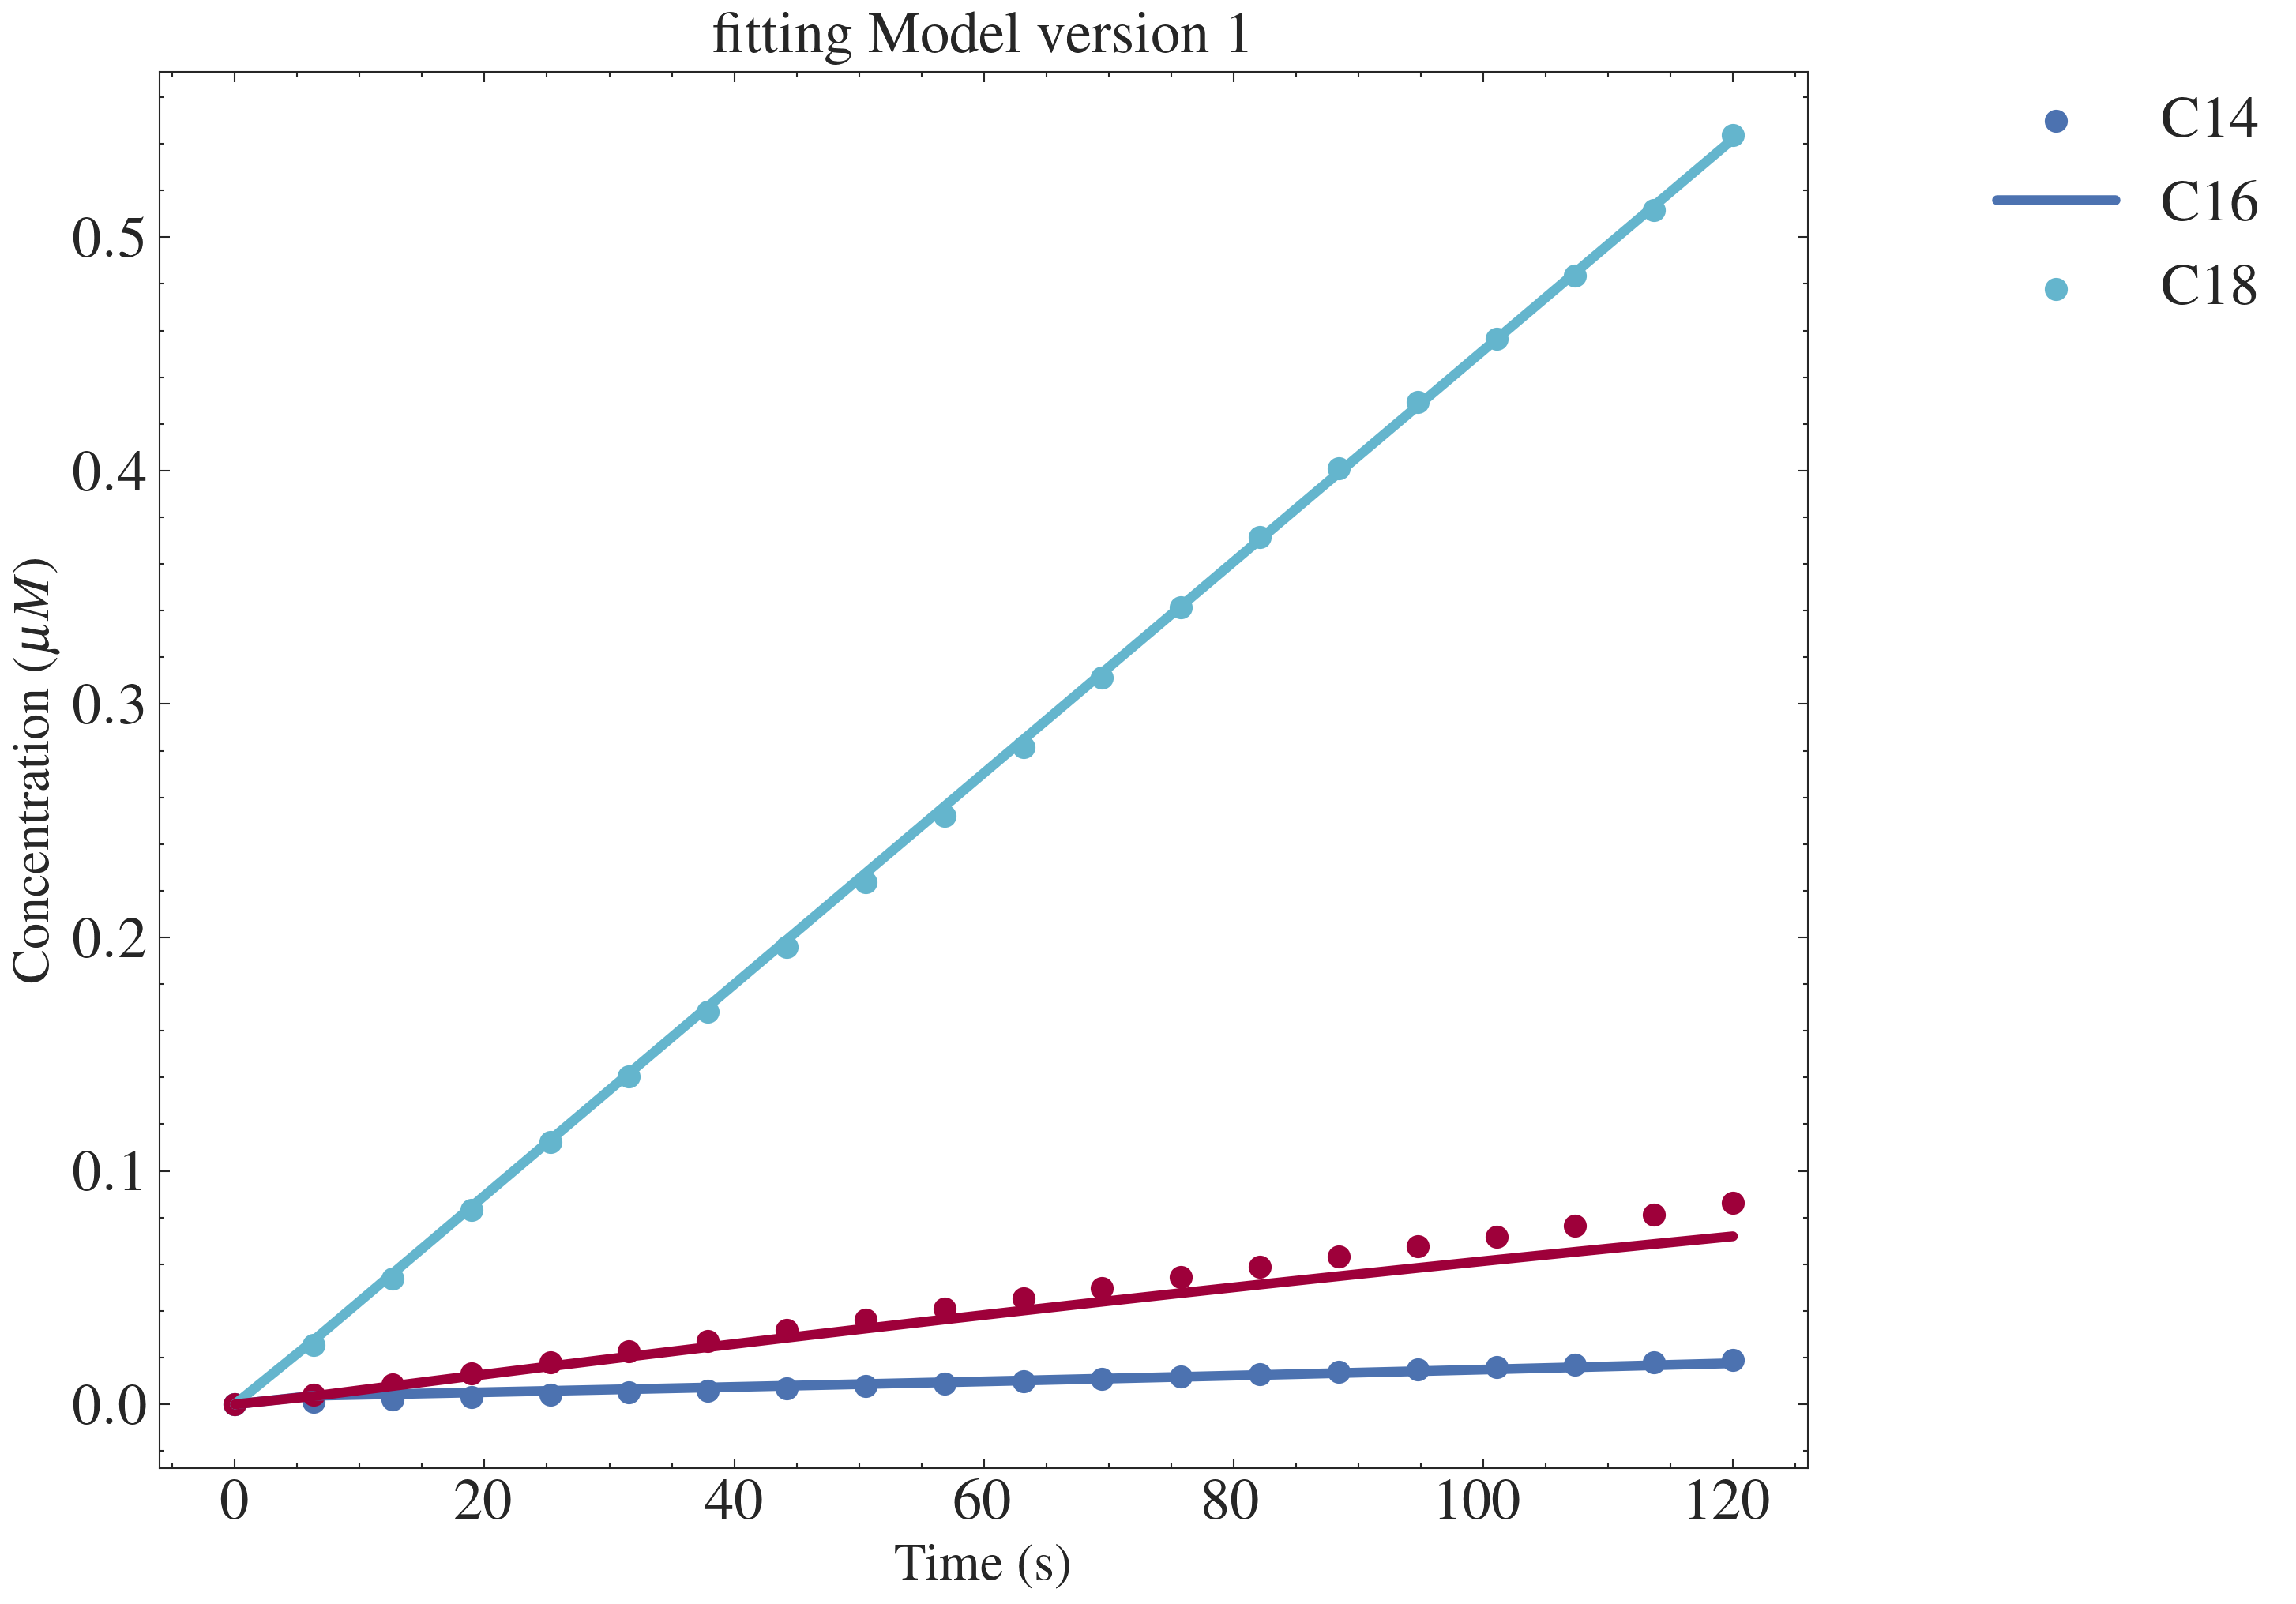

In [167]:
#plotting the results of the simulation 


fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_interp, data_to_fit[:, i], color=color[i][0], marker='o')
    ax.plot(time_interp, final[:, i], color=color[i][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["C14","C16", "C18"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0, fontsize =18)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()




###  Simulate for a long run the type of fatty acids produce with the Parameters obtained from fitting of the intial phase 

This is to see how the parameters from the initail phase impact the long run simulation 

In [168]:
par_fit_intial_phase =par = {
    "beta": 1e-01,
    "kappa": 1e-2,
    "delta": 2.9e-07,  #
    # "kd1": 0,
    # "kd2": 0,
    # "kd3": 0,
    # "kd4": 0,
    # "kd5": 0,
    "kd6": 1,
    "kd7": 0.014,  #
    "kd8": 1,
  
}

sim_time = np.linspace(0, 4800)
sim_max_time = sim_time[-1]

In [169]:
nefas_fitting = fatty_acid_of_interest(
    system, par_fit_intial_phase, y0, max_time=sim_max_time, ncp_list=sim_time
)

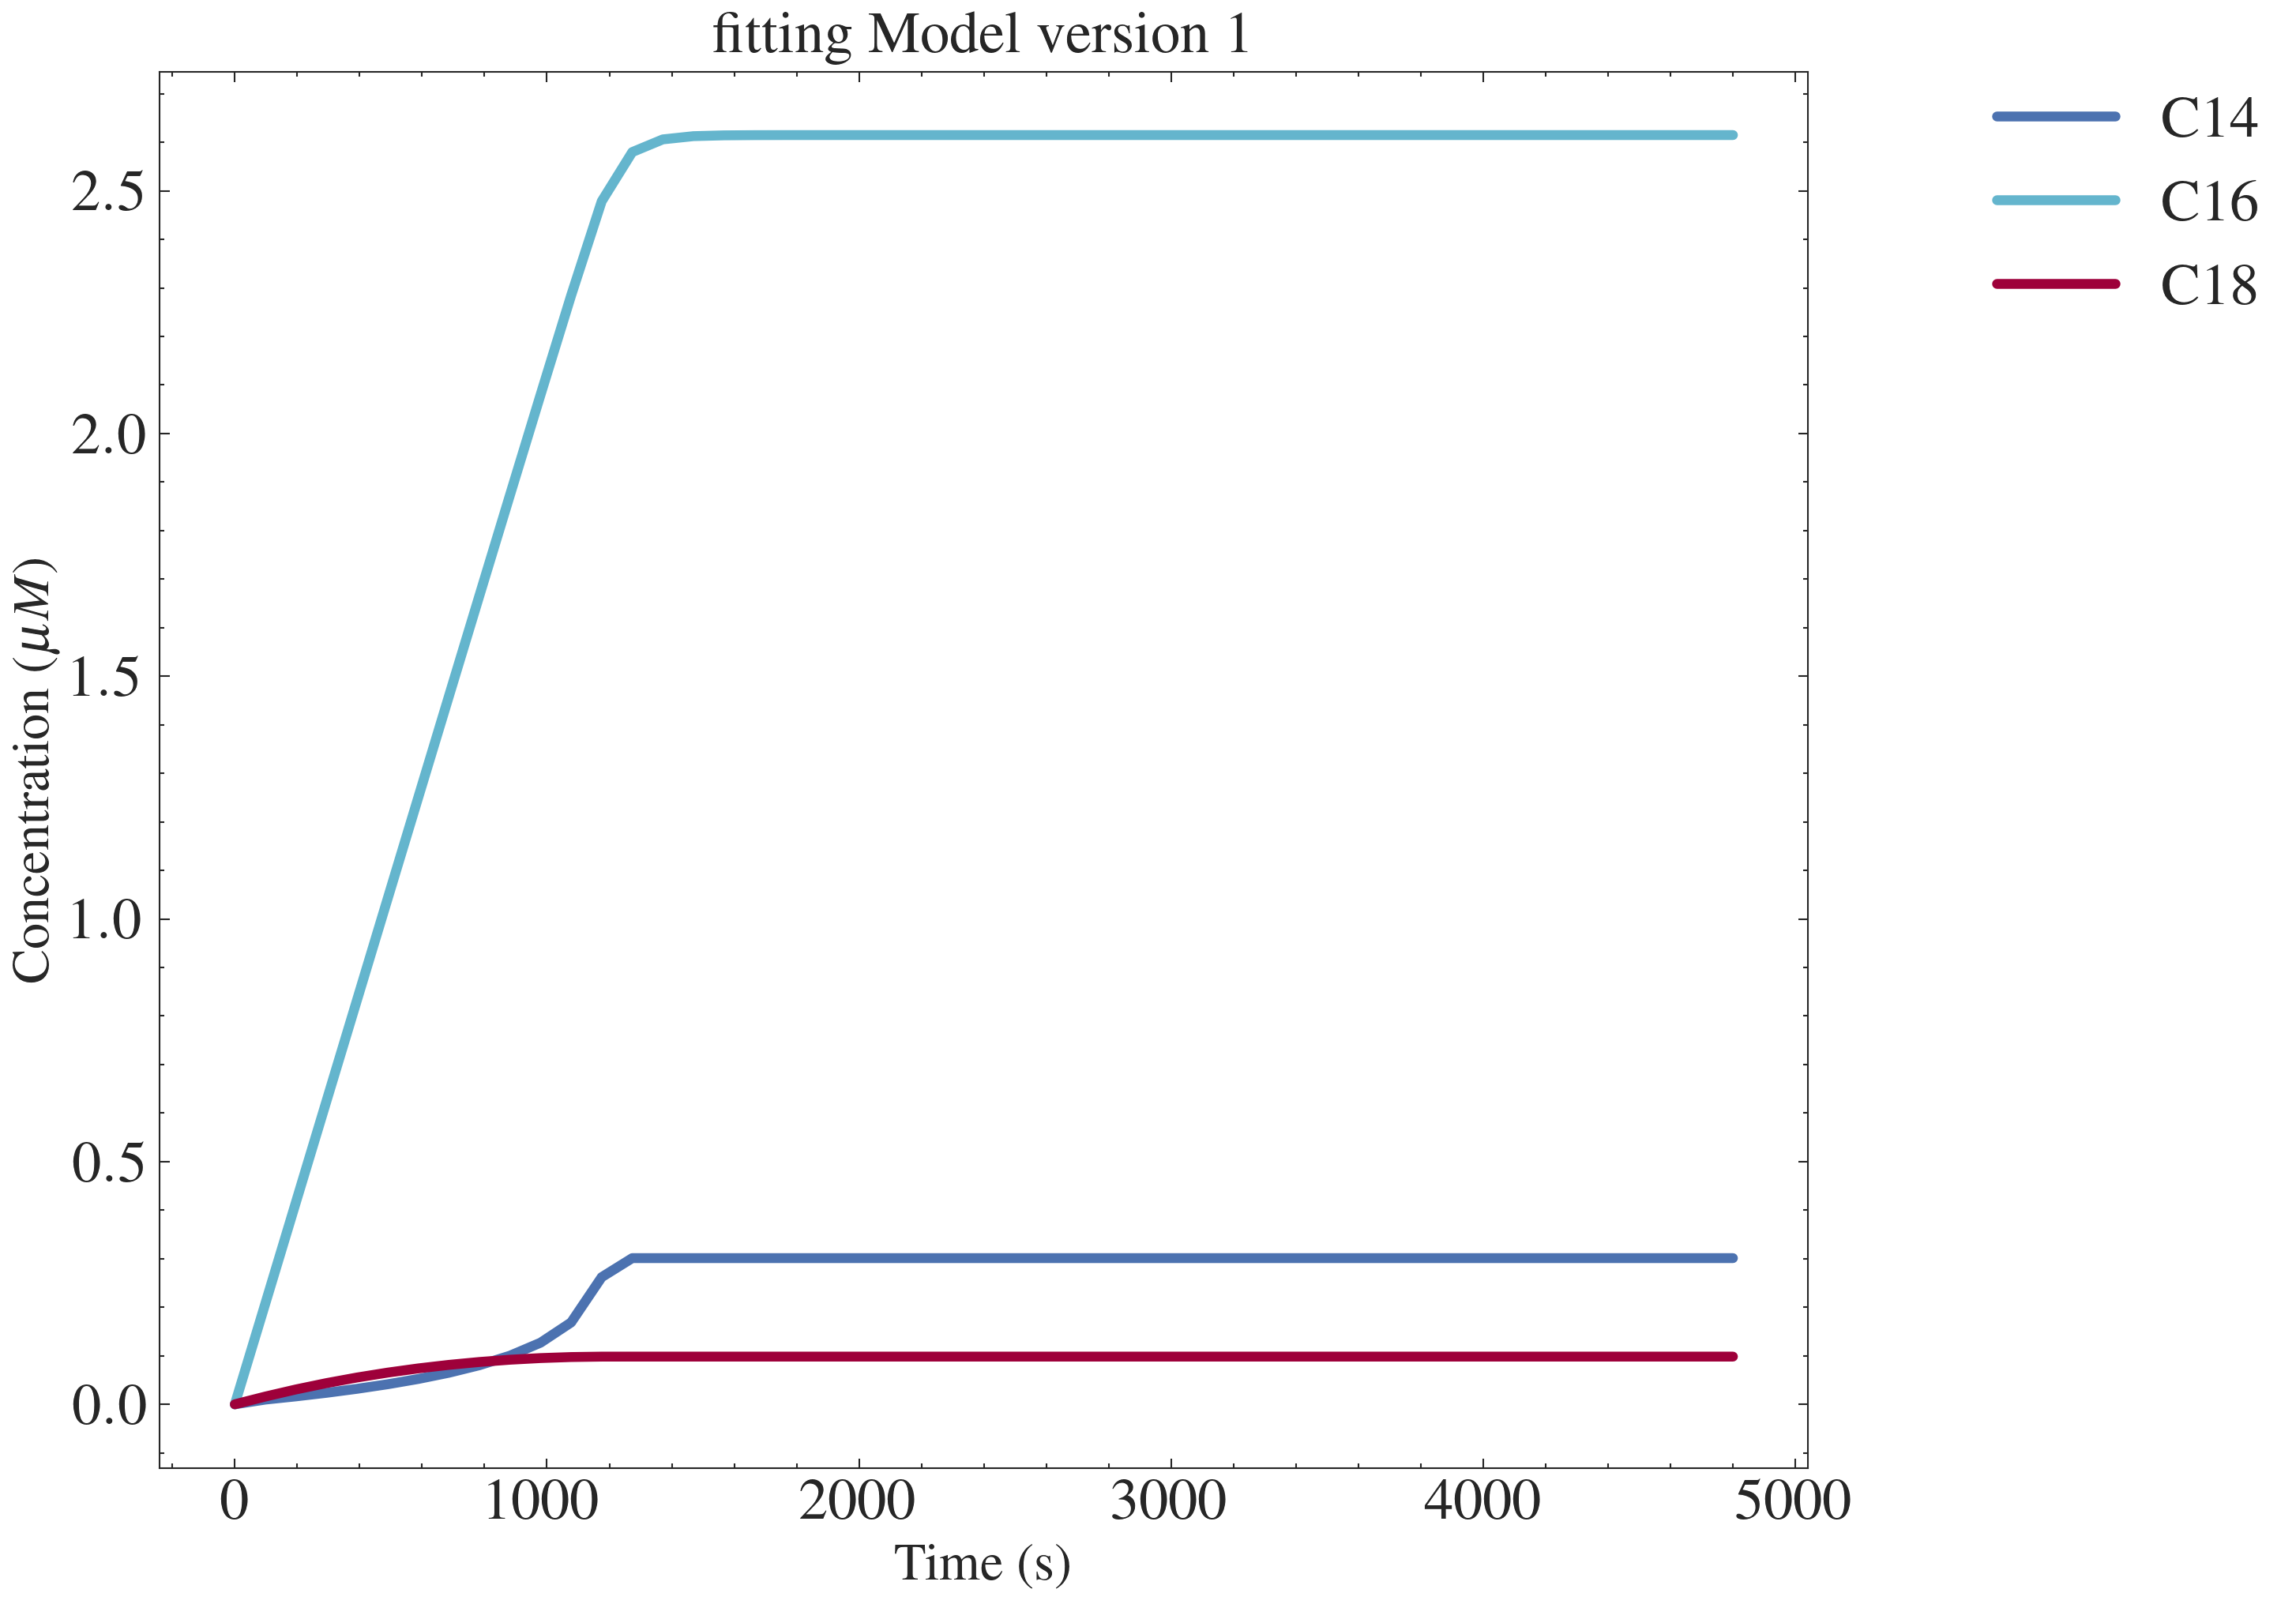

In [170]:
fig, ax = plt.subplots(figsize=(10, 7))
for i in range(3):
    ax.plot(sim_time, nefas_fitting[:,i], color=color[i][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["C14","C16", "C18"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0, fontsize =18)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()



The parameters value of the initial phase fails to reproduce the full time course. Furthermore we can see an expected qualitative behavior on the time course of  C14:0 and the total production of C14:0 is greater that the one of C18:0. 

In conclusion the initial phase parameters fail to capture the transient phase and the steady state dynamics 


###  simulate  total NEFAs with parameters from initial phase and compare to total NEFAs data

In [171]:
par_fit_intial_phase  = {
    "beta": 1e-01,
    "kappa": 1e-2,
    "delta": 2.9e-07,  #
    # "kd1": 0,
    # "kd2": 0,
    # "kd3": 0,
    # "kd4": 0,
    # "kd5": 0,
    "kd6": 1,
    "kd7": 0.03,  #
    "kd8": 1,
  
}



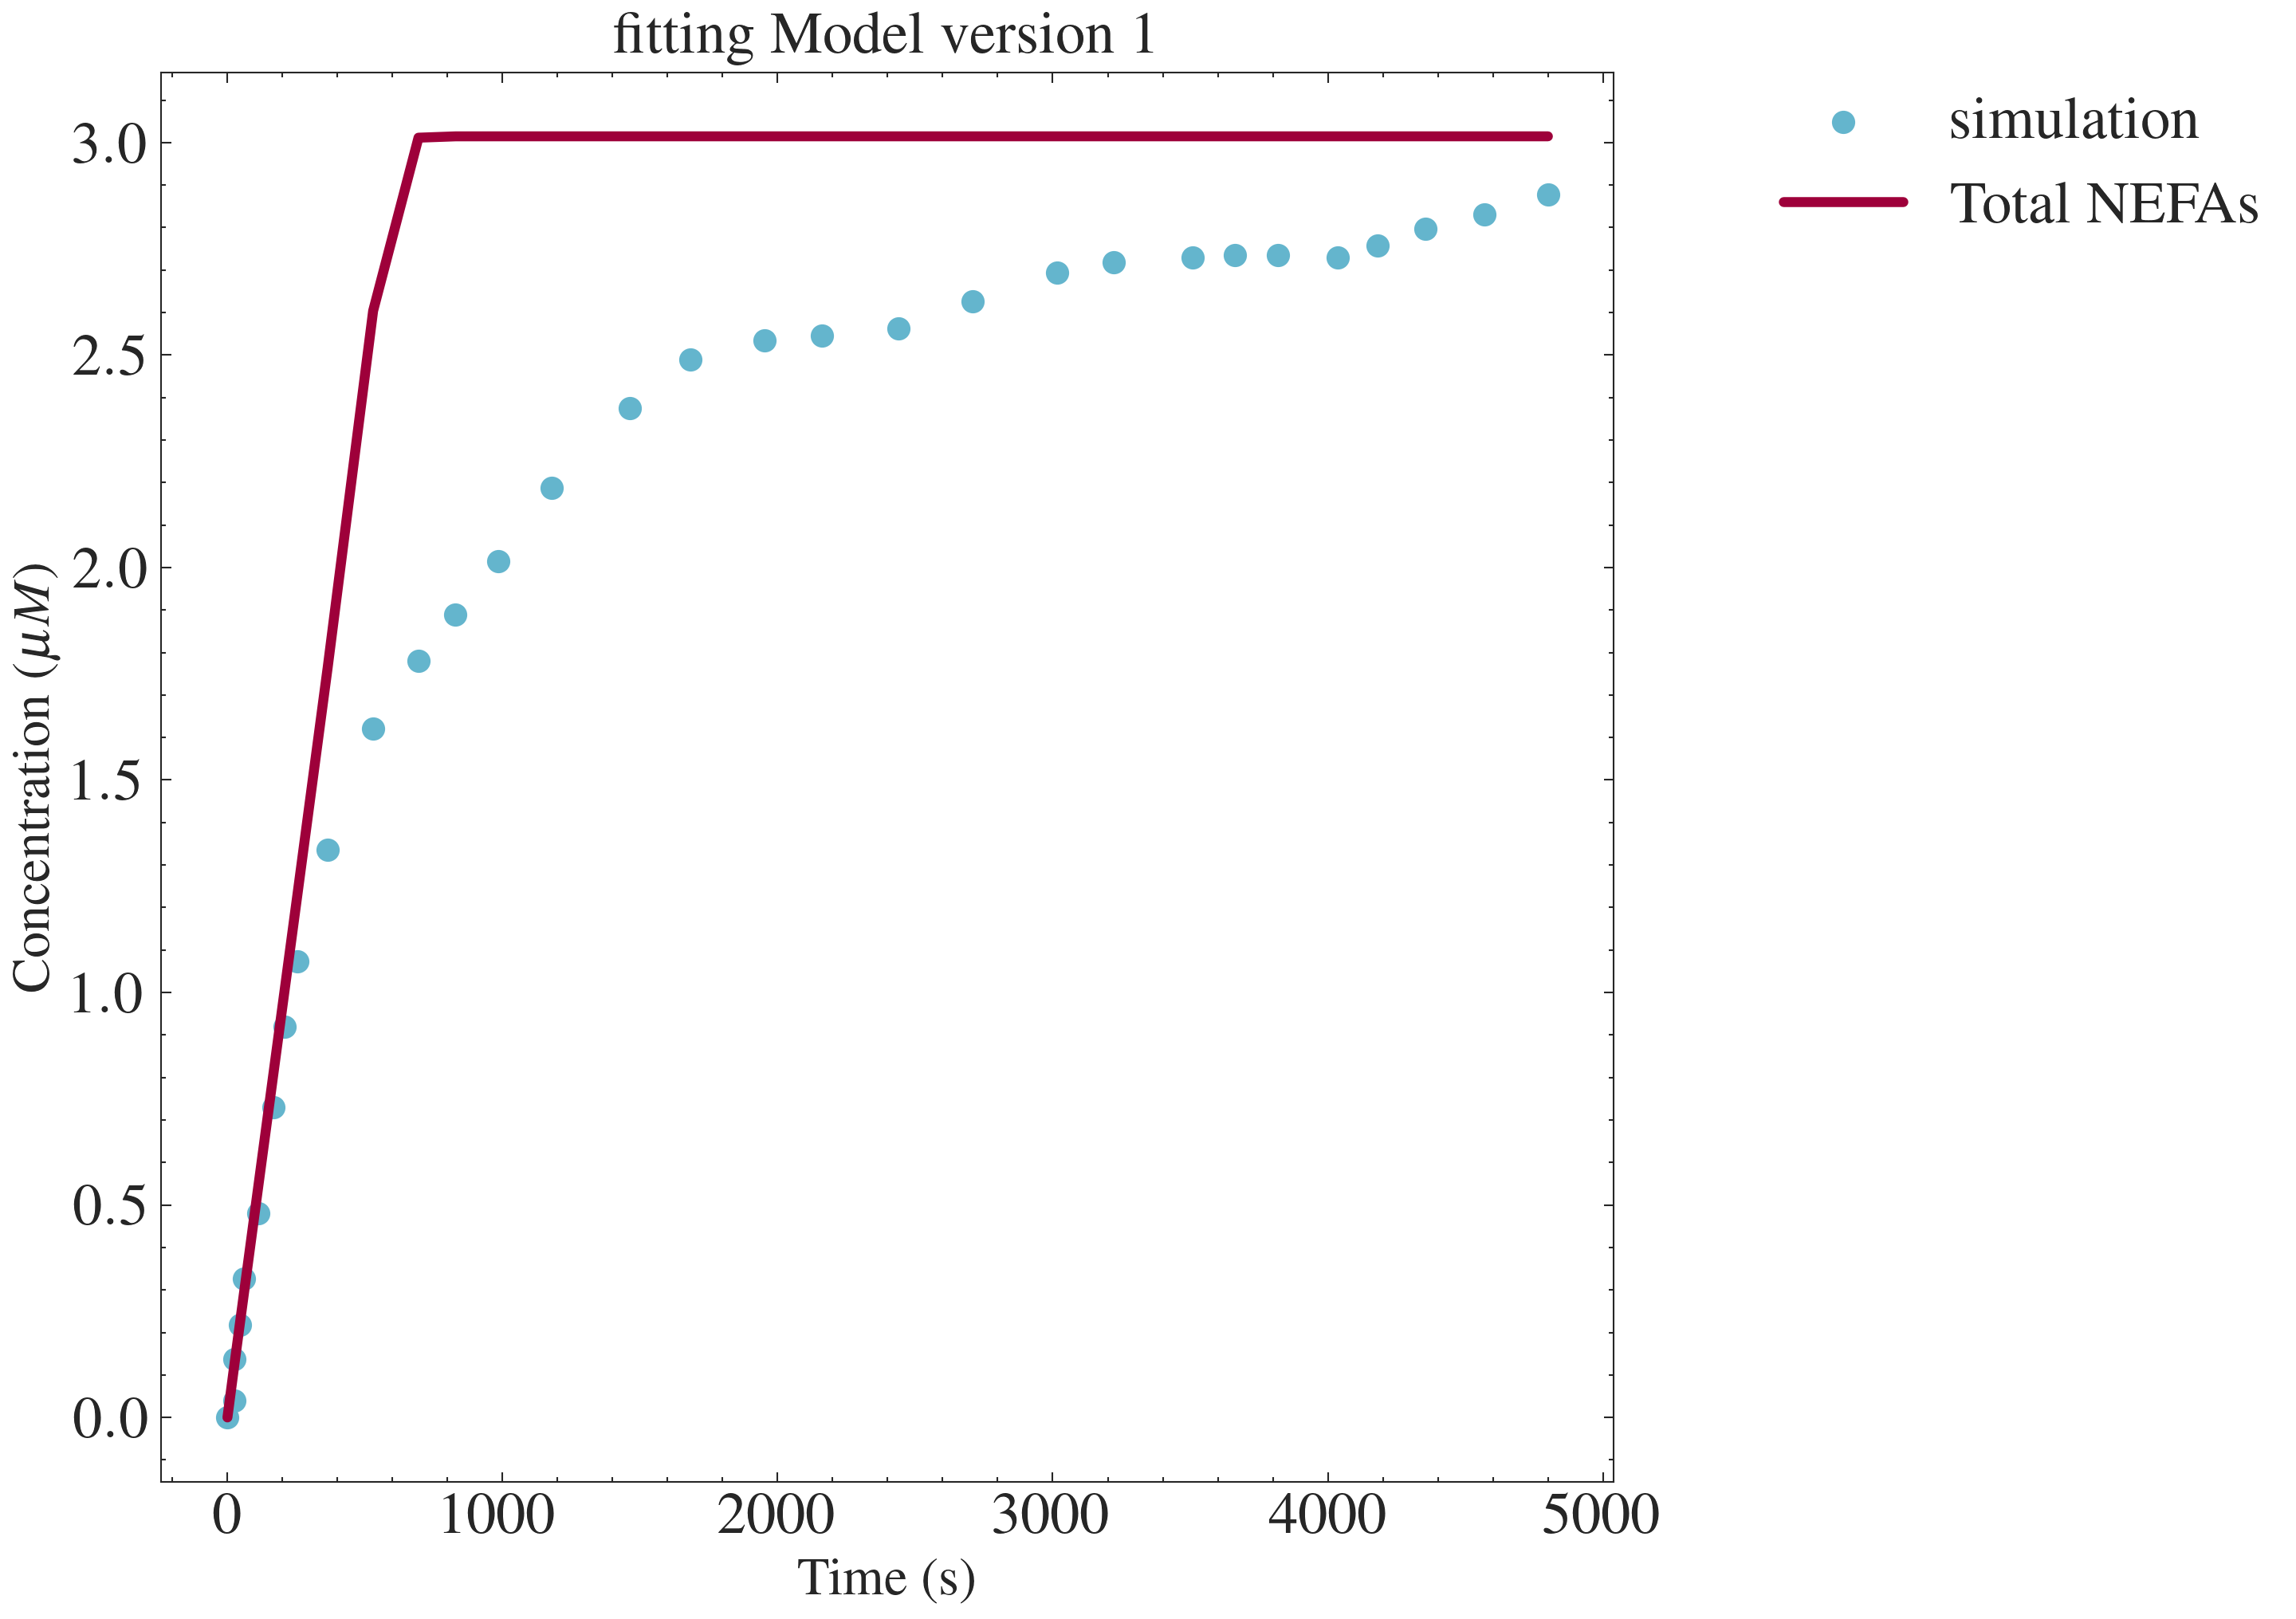

In [172]:
tot2 = total_fatty_acid(system, par_fit_intial_phase, y0, max_time = time_simulations[-1] , ncp_list = time_simulations)
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter(time_simulations,total_nefas1, color=color[1][0], marker='o')
ax.plot(time_simulations, tot2, color=color[2][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["simulation","Total NEFAs"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0, fontsize =18)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()

The initial phase parameter is unable to reproduce the total concentration of NEFAs.

## Fitting the total fatty acids for the long run time 

In [173]:
def residual_NEFA(parameters, max_time, time, data):
    y0[1] = parameters["y0_mal"].value
    #print(y0)
    model = total_fatty_acid(system, parameters, y0, max_time = max_time , ncp_list = time)
    res = (model - data).ravel()
    
    return res

### We consider the lower bound for the value of $\beta$ and $\kappa$

In [174]:

par_total_trial1 = Parameters()
par_total_trial1.add("beta", value=1e-01, min = 1e-2)
par_total_trial1.add("kappa", value=1e-2, min =1e-3)
par_total_trial1.add("delta", value=1.17e-06,  vary=False)
# par_total_trial1.add("kd1", value=0, vary=False)
# par_total_trial1.add("kd2", value=0, vary=False)
# par_total_trial1.add("kd3", value=0, vary=False)
# par_total_trial1.add("kd4", value=0,vary=False)
# par_total_trial1.add("kd5", value= 0,vary=False)
par_total_trial1.add("kd6", value= 1,  min=0)
par_total_trial1.add("kd7", value= 0.3, vary= False)
par_total_trial1.add("kd8", value=1,   min=0)
par_total_trial1.add("y0_mal", value=21.04, vary=False)


In [175]:
result_trial1 = minimize(residual_NEFA,par_total_trial1, args=(time_simulations[-1] , time_simulations ,total_nefas1), method="leastsq")
final1 = total_nefas1+ result_trial1.residual.reshape(total_nefas1.shape)


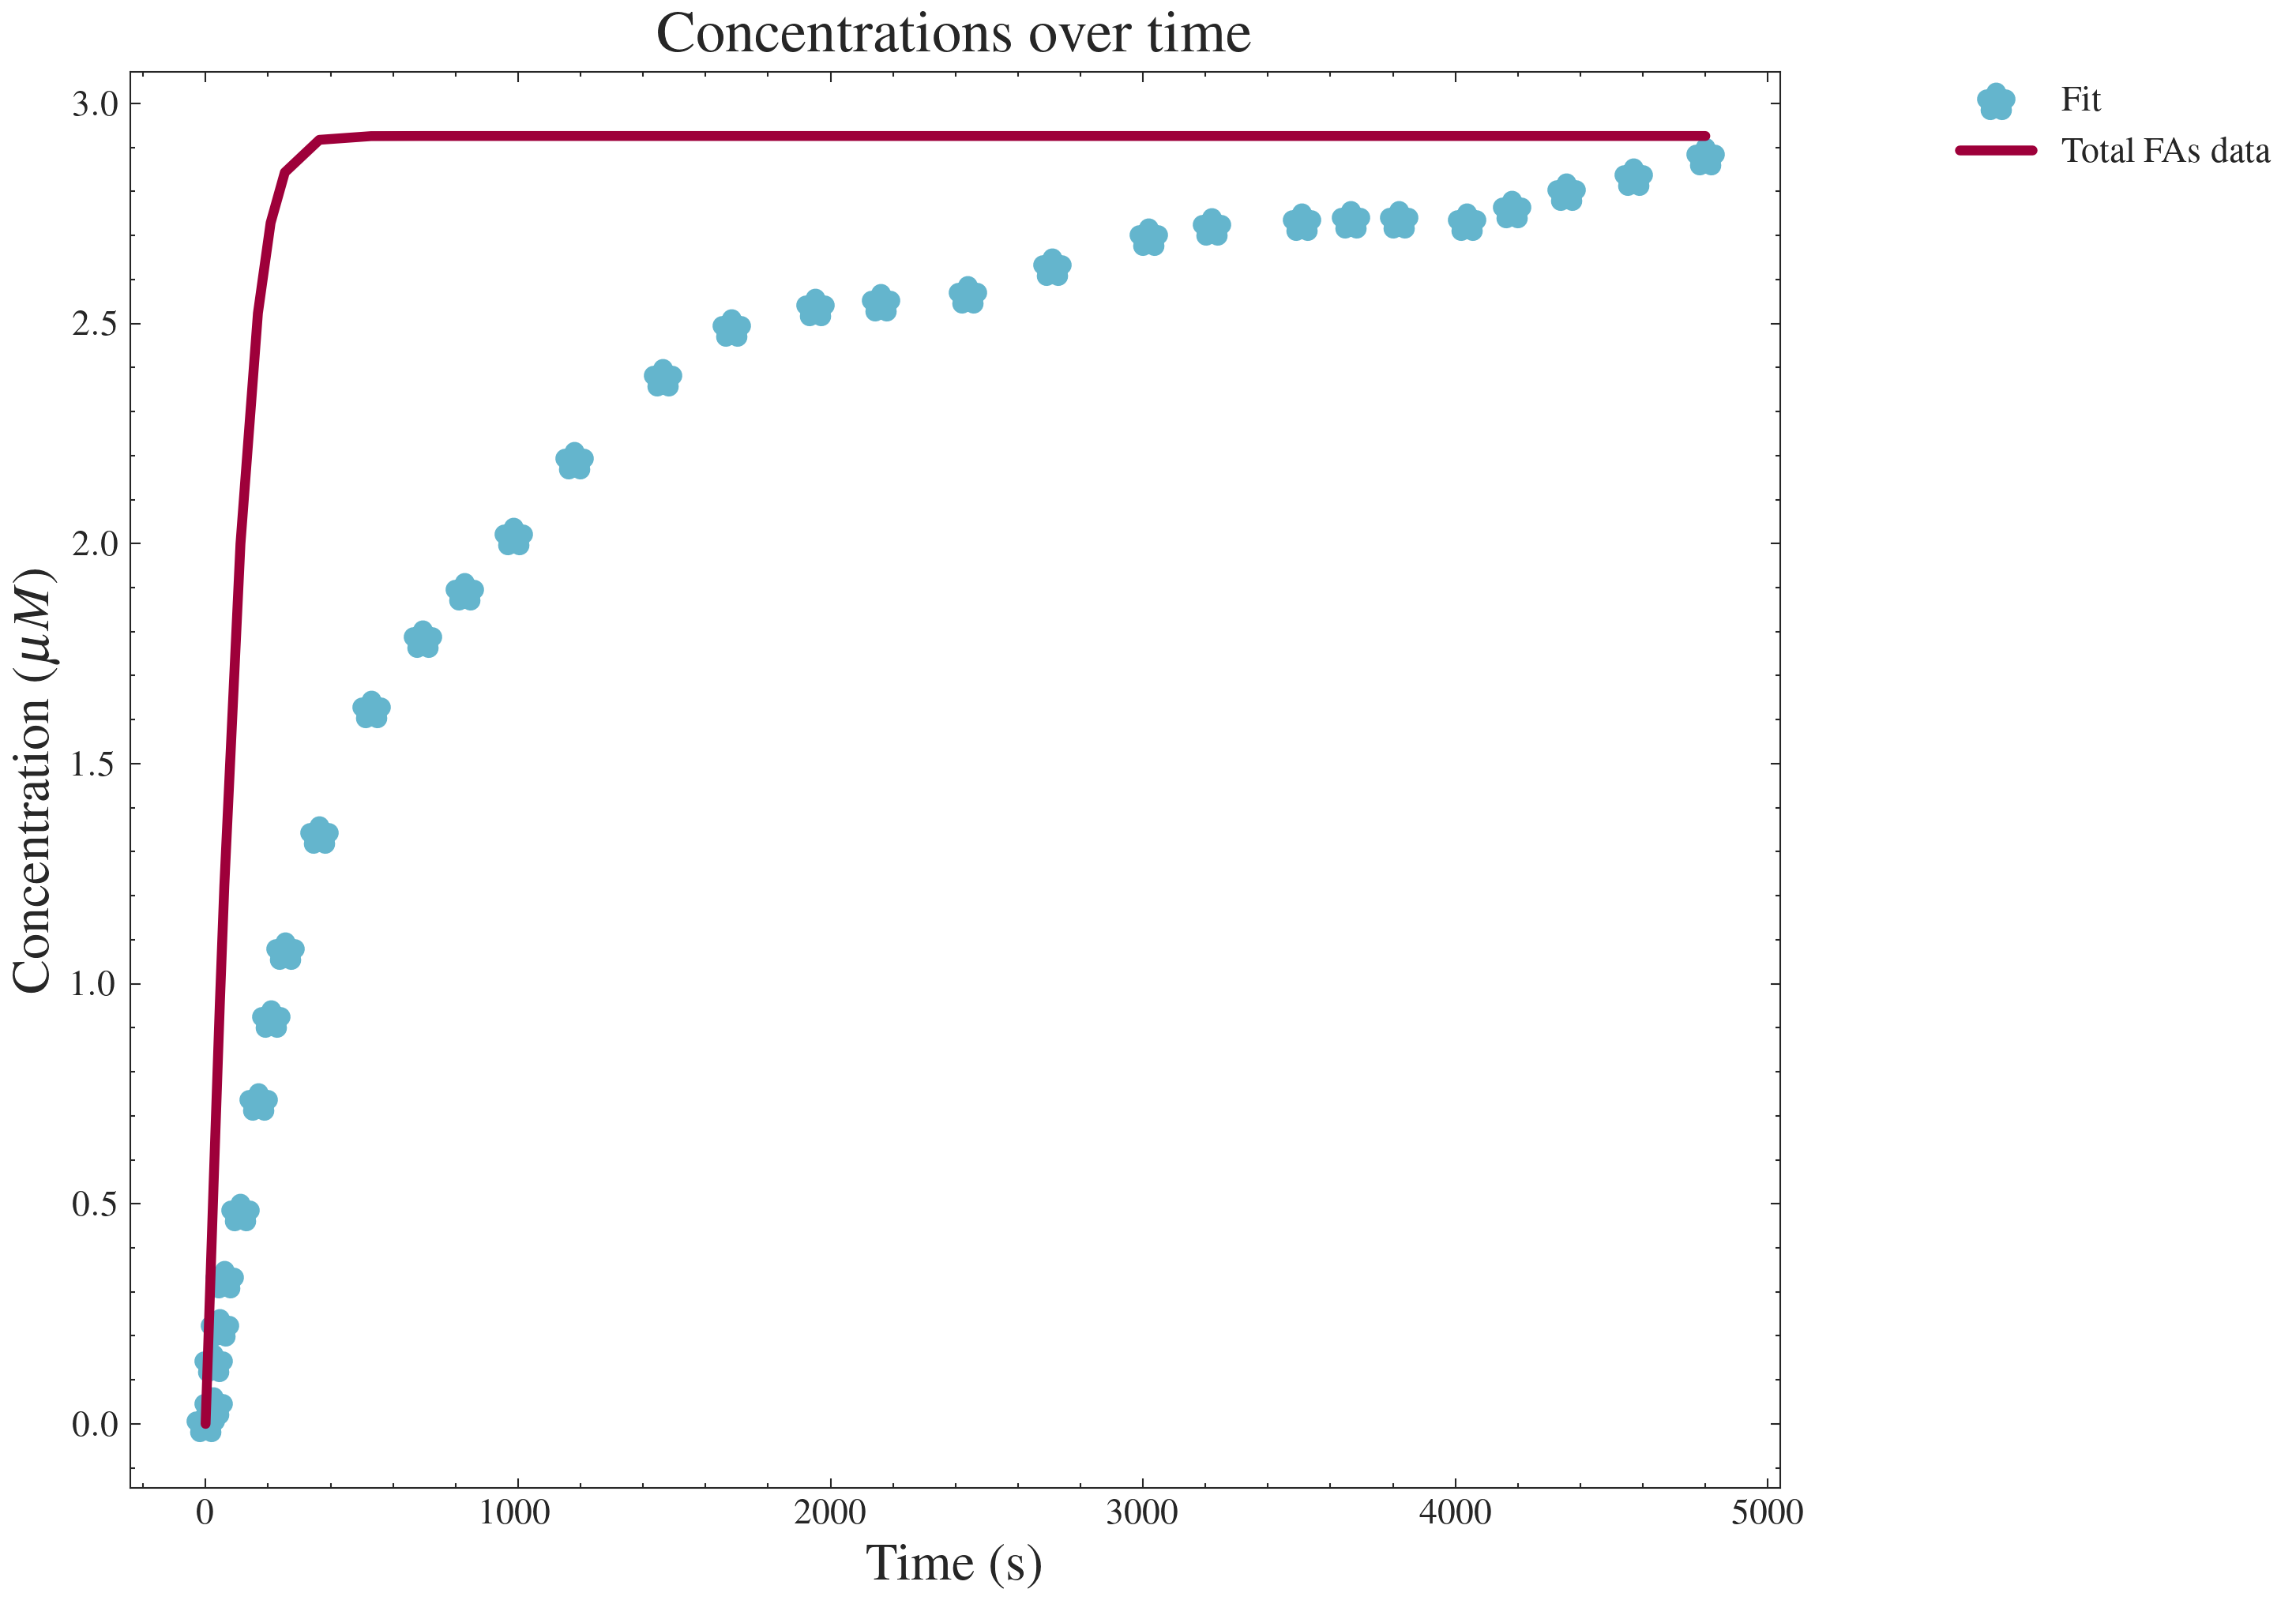

In [176]:
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter(time_simulations , total_nefas1, color=color[1][0], marker='*', linewidths=6)
ax.plot(time_simulations , final1, color=color[2][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M $) ", fontsize=16)
plt.title("Concentrations over time ", fontsize=18)
#plt.yscale("log")
ax.legend(["Fit","Total FAs data"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()

In [177]:
report_fit(result_trial1)


[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 218
    # data points      = 31
    # variables        = 4
    chi-square         = 22.9632667
    reduced chi-square = 0.85049136
    Akaike info crit   = -1.30283233
    Bayesian info crit = 4.43311649
##  Warning: uncertainties could not be estimated:
    beta:    at boundary
    kappa:   at boundary
    kd6:     at boundary
    kd8:     at boundary
[[Variables]]
    beta:    0.01000000 (init = 0.1)
    kappa:   0.00100000 (init = 0.01)
    delta:   1.17e-06 (fixed)
    kd6:     2.6825e-09 (init = 1)
    kd7:     0.3 (fixed)
    kd8:     1.7638e-09 (init = 1)
    y0_mal:  21.04 (fixed)


## Conclusion 

We need a different strategy to fit the transient and the steady state data. We suggest to explore three strategy 

- The solubility 
- The sinking enzyme(no longer the conservation relation for the enzymes ) 
- Or the reversing binding for malanyl-coA


## Release the lower bound of the parameters $\beta$ and $\kappa$

- We now set free the parameter $\beta$  and $\kappa$ and we fit to the long run data. 
- We are able to fit the long run data, but the initial phase is not longer reproduced as the value of $\kappa$ ($5\times 10^{-5}$) to small. 



In [178]:
par_total_trial2 = Parameters()
par_total_trial2.add("beta", value=1e-01, min = 0)
par_total_trial2.add("kappa", value=1e-2, min =0)
par_total_trial2.add("delta", value=1.17e-06,  vary=False)
# par_total_trial2.add("kd1", value=0, vary=False)
# par_total_trial2.add("kd2", value=0, vary=False)
# par_total_trial2.add("kd3", value=0, vary=False)
# par_total_trial2.add("kd4", value=0,vary=False)
# par_total_trial2.add("kd5", value= 0,vary=False)
par_total_trial2.add("kd6", value= 1,  min=0)
par_total_trial2.add("kd7", value= 0.3, vary= False)
par_total_trial2.add("kd8", value=1,   min=0)
par_total_trial2.add("y0_mal", value=21.04, vary=False)

In [179]:
result_trial2 = minimize(residual_NEFA,par_total_trial2, args=(time_simulations[-1] , time_simulations ,total_nefas1), method="leastsq")
final2 = total_nefas1+ result_trial2.residual.reshape(total_nefas1.shape)

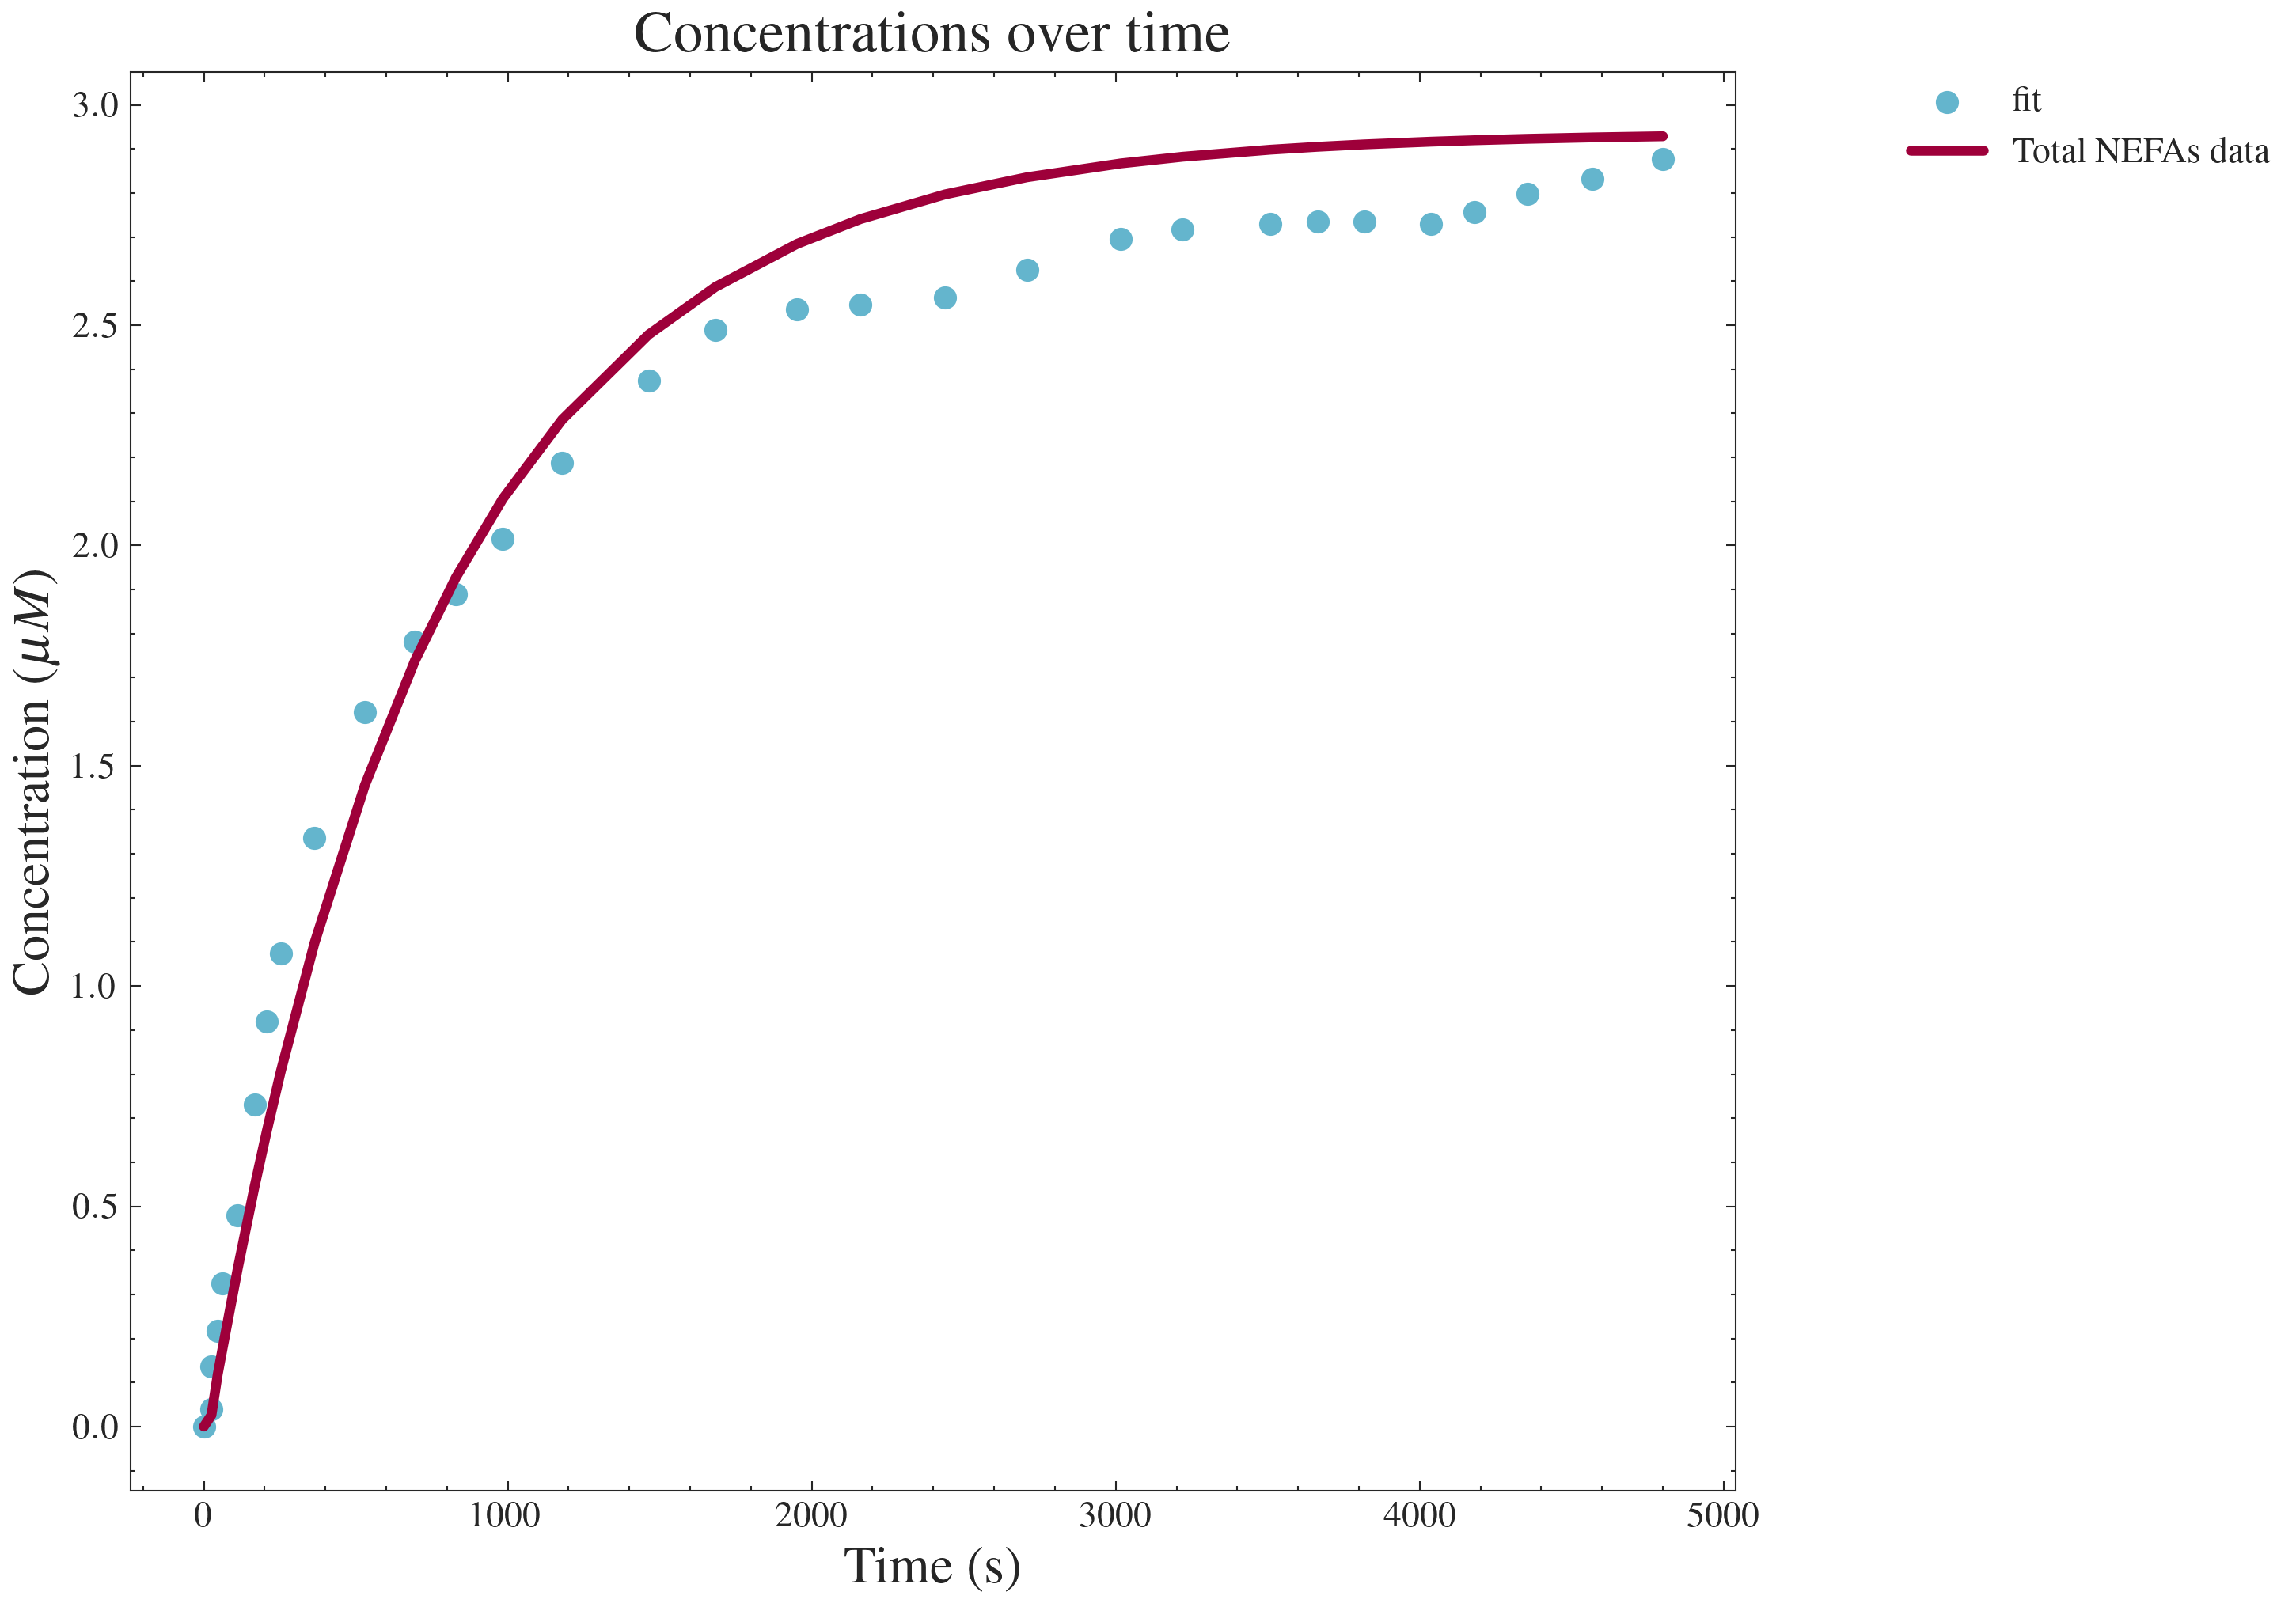

In [180]:
fig, ax = plt.subplots(figsize=(10, 7))


ax.scatter(time_simulations , total_nefas1, color=color[1][0], marker='o')
ax.plot(time_simulations , final2, color=color[2][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M $) ", fontsize=16)
plt.title("Concentrations over time ", fontsize=18)
#plt.yscale("log")
ax.legend(["fit","Total NEFAs data"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()

In [181]:
par_total_fit_2 = dict(result_trial2.params.valuesdict())

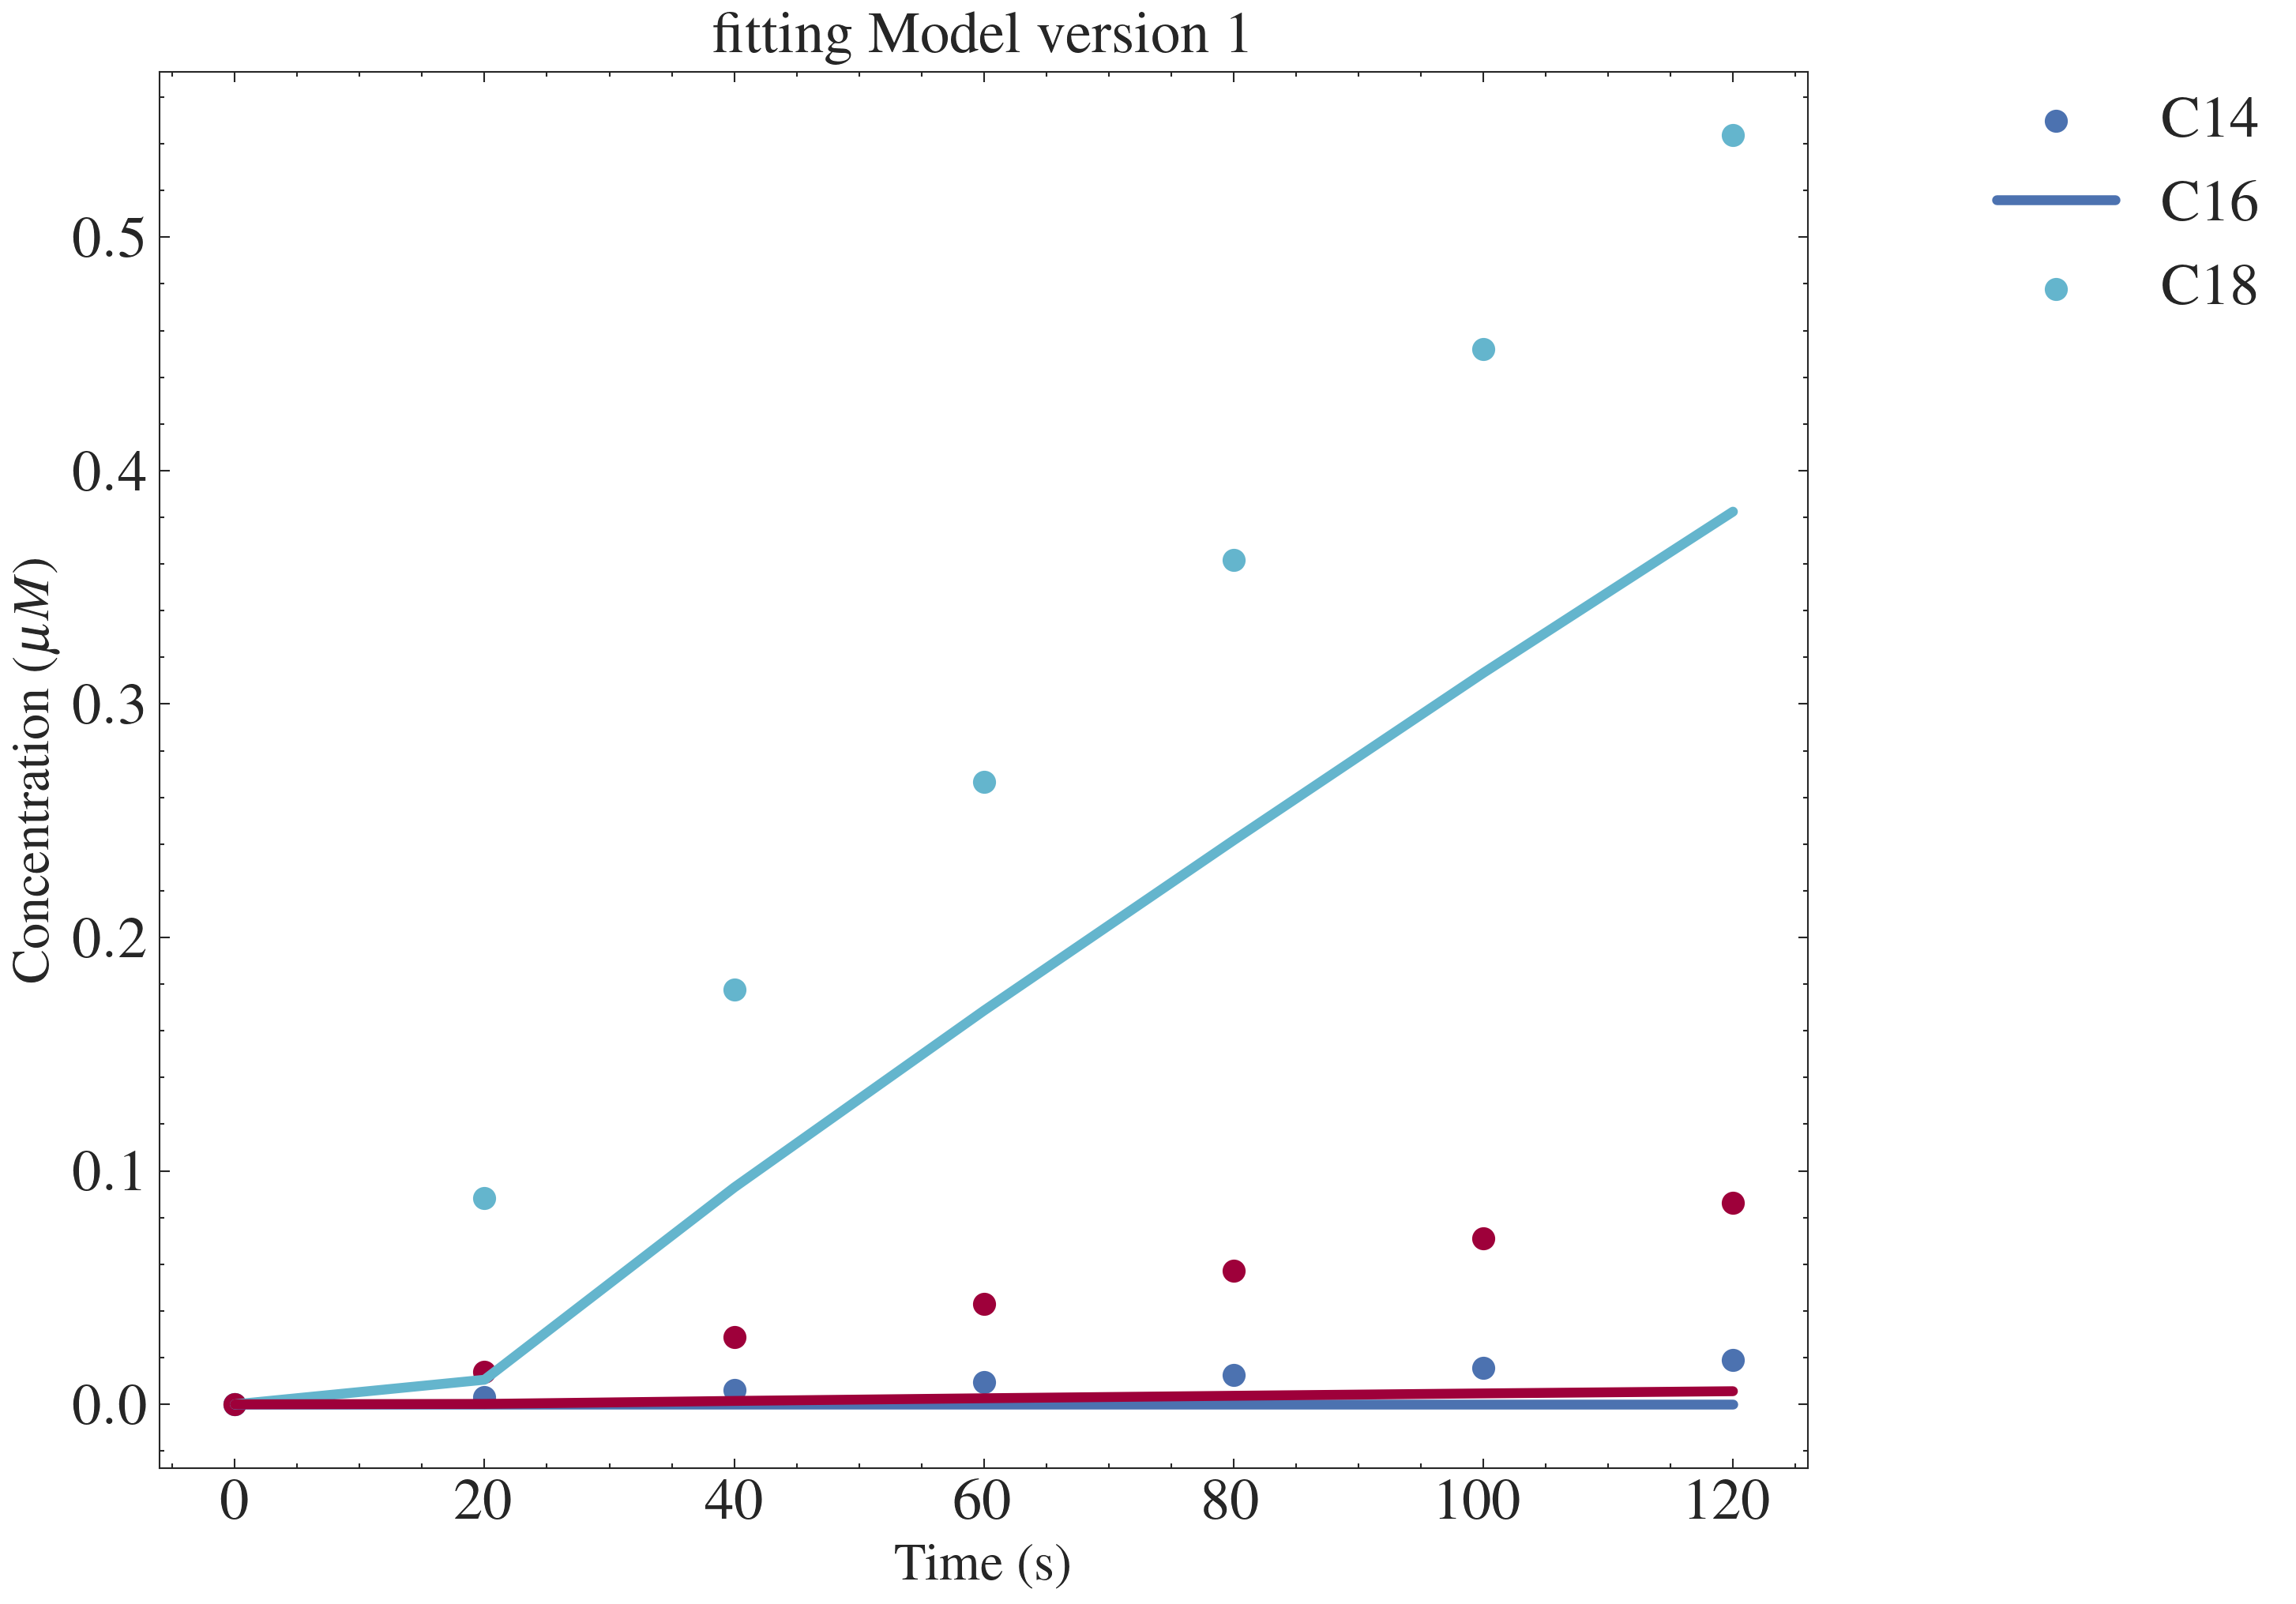

In [182]:
tot2 = fatty_acid_of_interest(system, par_total_fit_2, y0, max_time =time_initial_phase[-1] , ncp_list = time_initial_phase)
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_initial_phase,data_initial_phase[:, i], color=color[i][0], marker='o')
    ax.plot(time_initial_phase, tot2[:, i], color=color[i][0], linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["C14","C16", "C18"],
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0, fontsize =18)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()

In [183]:
report_fit(result_trial2)

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 483
    # data points      = 31
    # variables        = 4
    chi-square         = 0.74334080
    reduced chi-square = 0.02753114
    Akaike info crit   = -107.648224
    Bayesian info crit = -101.912275
##  Warning: uncertainties could not be estimated:
    kd6:     at boundary
[[Variables]]
    beta:    4.59072917 (init = 0.1)
    kappa:   4.9456e-05 (init = 0.01)
    delta:   1.17e-06 (fixed)
    kd6:     2.3935e-09 (init = 1)
    kd7:     0.3 (fixed)
    kd8:     148.742390 (init = 1)
    y0_mal:  21.04 (fixed)


# Dual fitting 

-We now fit the initial phase data and the long run simultaneously by freeing  $\beta$, $\kappa$, $k_{d6}$, and $k_{d8}$.

In [184]:
def residual_two(parameters, max_time1, time1, data1, max_time2, time2, data2):
    y0[1] = parameters["y0_mal"].value
    #print(y0)
    model1 = fatty_acid_of_interest(system, parameters, y0, max_time = max_time1 , ncp_list = time1)
    model2= total_fatty_acid(system, parameters, y0, max_time = max_time2 , ncp_list = time2)
    res1 =(model1 - data1).ravel()
    res2 = (model2 - data2).ravel()
    
    return np.concatenate((res1, res2)) 


In [185]:
par_dual = Parameters()
par_dual.add("beta", value=0.1, min =0)
par_dual.add("kappa", value=1e-2,  min= 0)
par_dual.add("delta", value= 1.17e-06,   vary=False)
# par_dual.add("kd1", value=0, vary=False)
# par_dual.add("kd2", value=0, vary=False)
# par_dual.add("kd3", value=0, vary=False)
# par_dual.add("kd4", value=0,vary=False)
# par_dual.add("kd5", value= 0.0,vary=False)
par_dual.add("kd6", value= 1,  min=0)
par_dual.add("kd7", value= 0.03, vary =False)
par_dual.add("kd8", value=1,   min=0)
par_dual.add("y0_mal", value=21.04, vary =False)


In [186]:
result_two = minimize(residual_two, par_dual, args=(time_interp[-1], time_interp, data_to_fit, time_simulations[-1], time_simulations ,total_nefas1), method="leastsquare")
# final_two = data2 + result.residual.reshape(data2.shape)
# final_two.shape



In [187]:
par_fitting_two = dict(result_two.params.valuesdict())
par_fitting_two

{'beta': 57.22506994351793,
 'kappa': 3.8997718761166498,
 'delta': 1.17e-06,
 'kd6': 6.563828895519148,
 'kd7': 0.03,
 'kd8': 74.70241782095566,
 'y0_mal': 21.04}

In [188]:
report_fit(result_two)

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 36
    # data points      = 91
    # variables        = 4
    chi-square         = 7.32443691
    reduced chi-square = 0.08418893
    Akaike info crit   = -221.287534
    Bayesian info crit = -211.244096
[[Variables]]
    beta:    57.2250699 +/- 5663.44883 (9896.80%) (init = 0.1)
    kappa:   3.89977188 +/- 322.415795 (8267.56%) (init = 0.01)
    delta:   1.17e-06 (fixed)
    kd6:     6.56382890 +/- 375.057937 (5714.01%) (init = 1)
    kd7:     0.03 (fixed)
    kd8:     74.7024178 +/- 4161.06341 (5570.19%) (init = 1)
    y0_mal:  21.04 (fixed)
[[Correlations]] (unreported correlations are < 0.100)
    C(beta, kappa) = 0.758
    C(beta, kd6)   = 0.457
    C(kappa, kd8)  = 0.439
    C(kd6, kd8)    = 0.340
    C(kappa, kd6)  = 0.322
    C(beta, kd8)   = 0.319


In [189]:
fatty_acids= fatty_acid_of_interest(system, par= par_fitting_two, y0 =y0, max_time = time_initial_phase[-1], ncp_list=time_initial_phase)

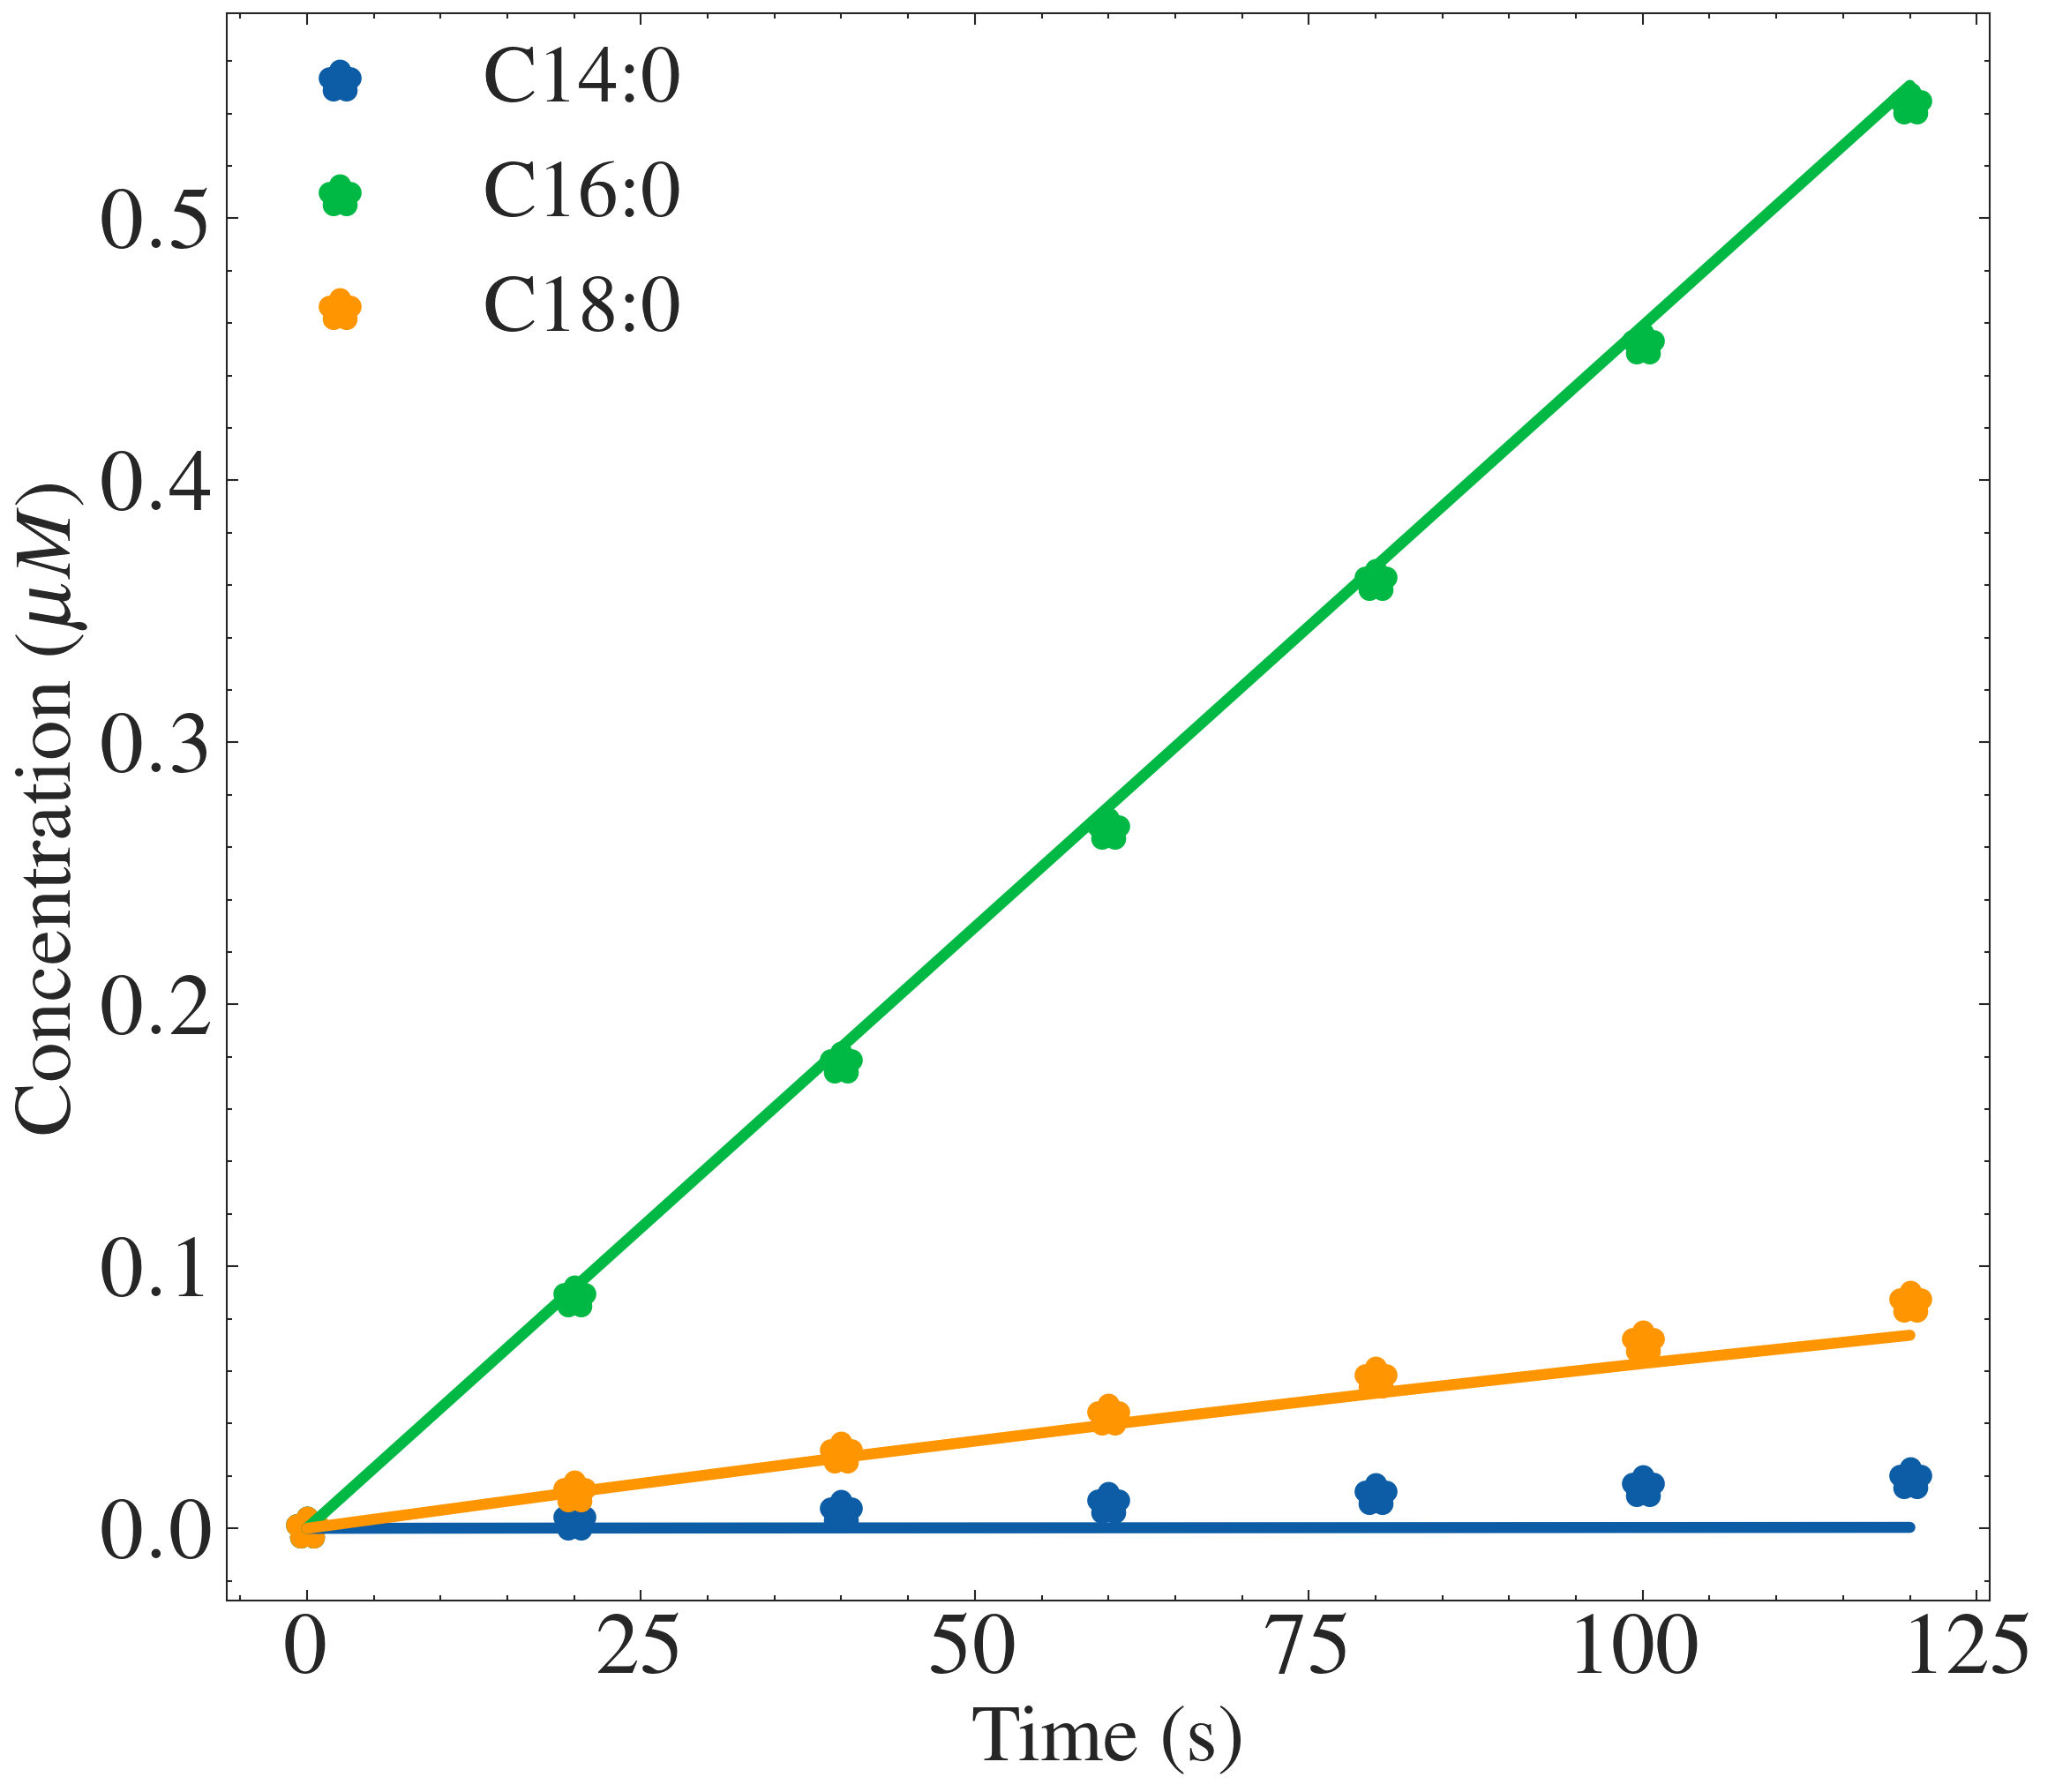

In [190]:
fig, ax = plt.subplots(figsize=(8, 7))

for i in range(3):
    ax.scatter(time_initial_phase, data_initial_phase[:, i] , marker='*', linewidths =6)
ax.plot(time_initial_phase, fatty_acids, linewidth =3)

#plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=22)
plt.ylabel("Concentration ($\mu M$) ", fontsize=22)
#plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size = 18)
plt.yticks(size = 18)
#plt.yscale("log")
ax.legend(["C14:0","C16:0", "C18:0"],
          loc="best",
          borderaxespad=0, fontsize =22)
ax.tick_params(axis="both", labelsize=24)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"init2.eps", bbox_inches="tight")
plt.show()




In [191]:
simulated_nefas = total_fatty_acid(
    system,
    par=par_fitting_two,
    y0=y0,
    max_time=time_simulations[-1],
    ncp_list=time_simulations,
)

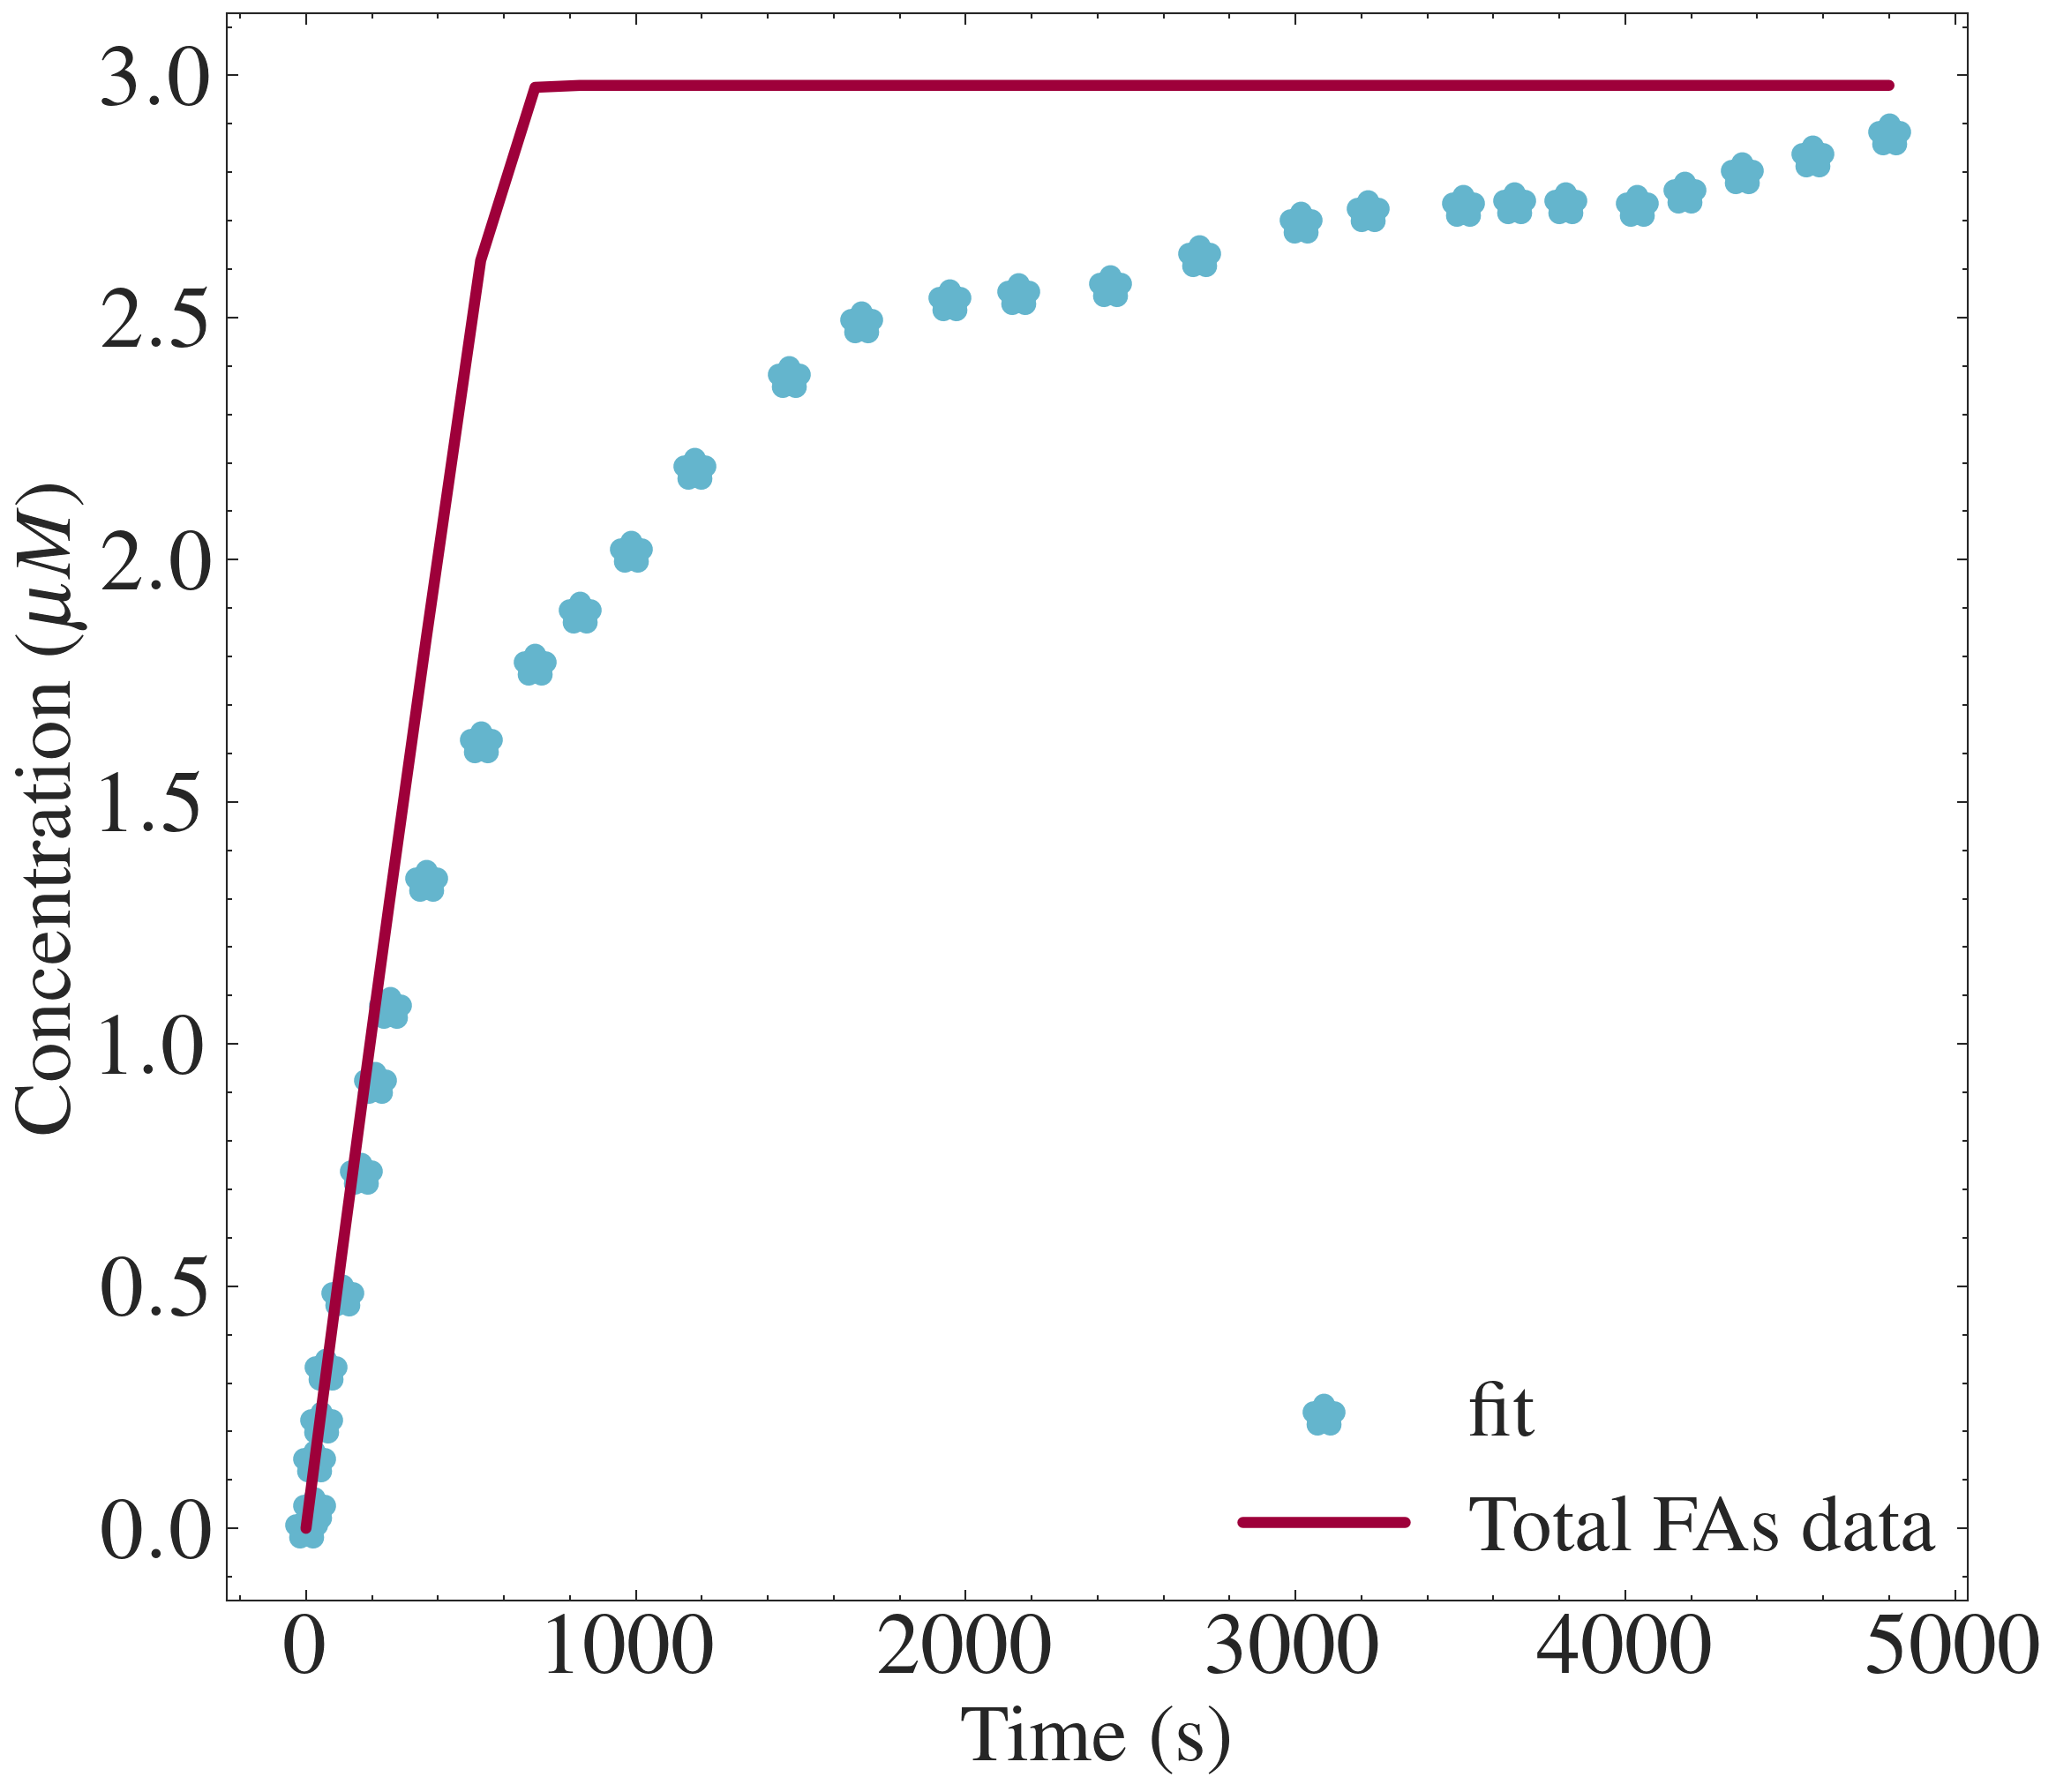

In [192]:
fig, ax = plt.subplots(figsize=(8, 7))


ax.scatter(time_simulations, total_nefas1, color=color[1][0], marker="*", linewidths =6)
ax.plot(time_simulations, simulated_nefas, color=color[2][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=22)
plt.ylabel("Concentration ($\mu M $) ", fontsize=22)
#plt.title("Concentrations over time ", fontsize=18)
# plt.yscale("log")
ax.legend(
    ["fit", "Total FAs data"],
    loc="best",
    borderaxespad=0,
    fontsize =22
)
ax.tick_params(axis="both", labelsize=24)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"eps.svg", bbox_inches="tight")
plt.show()

### check the parameters on initial phase data 

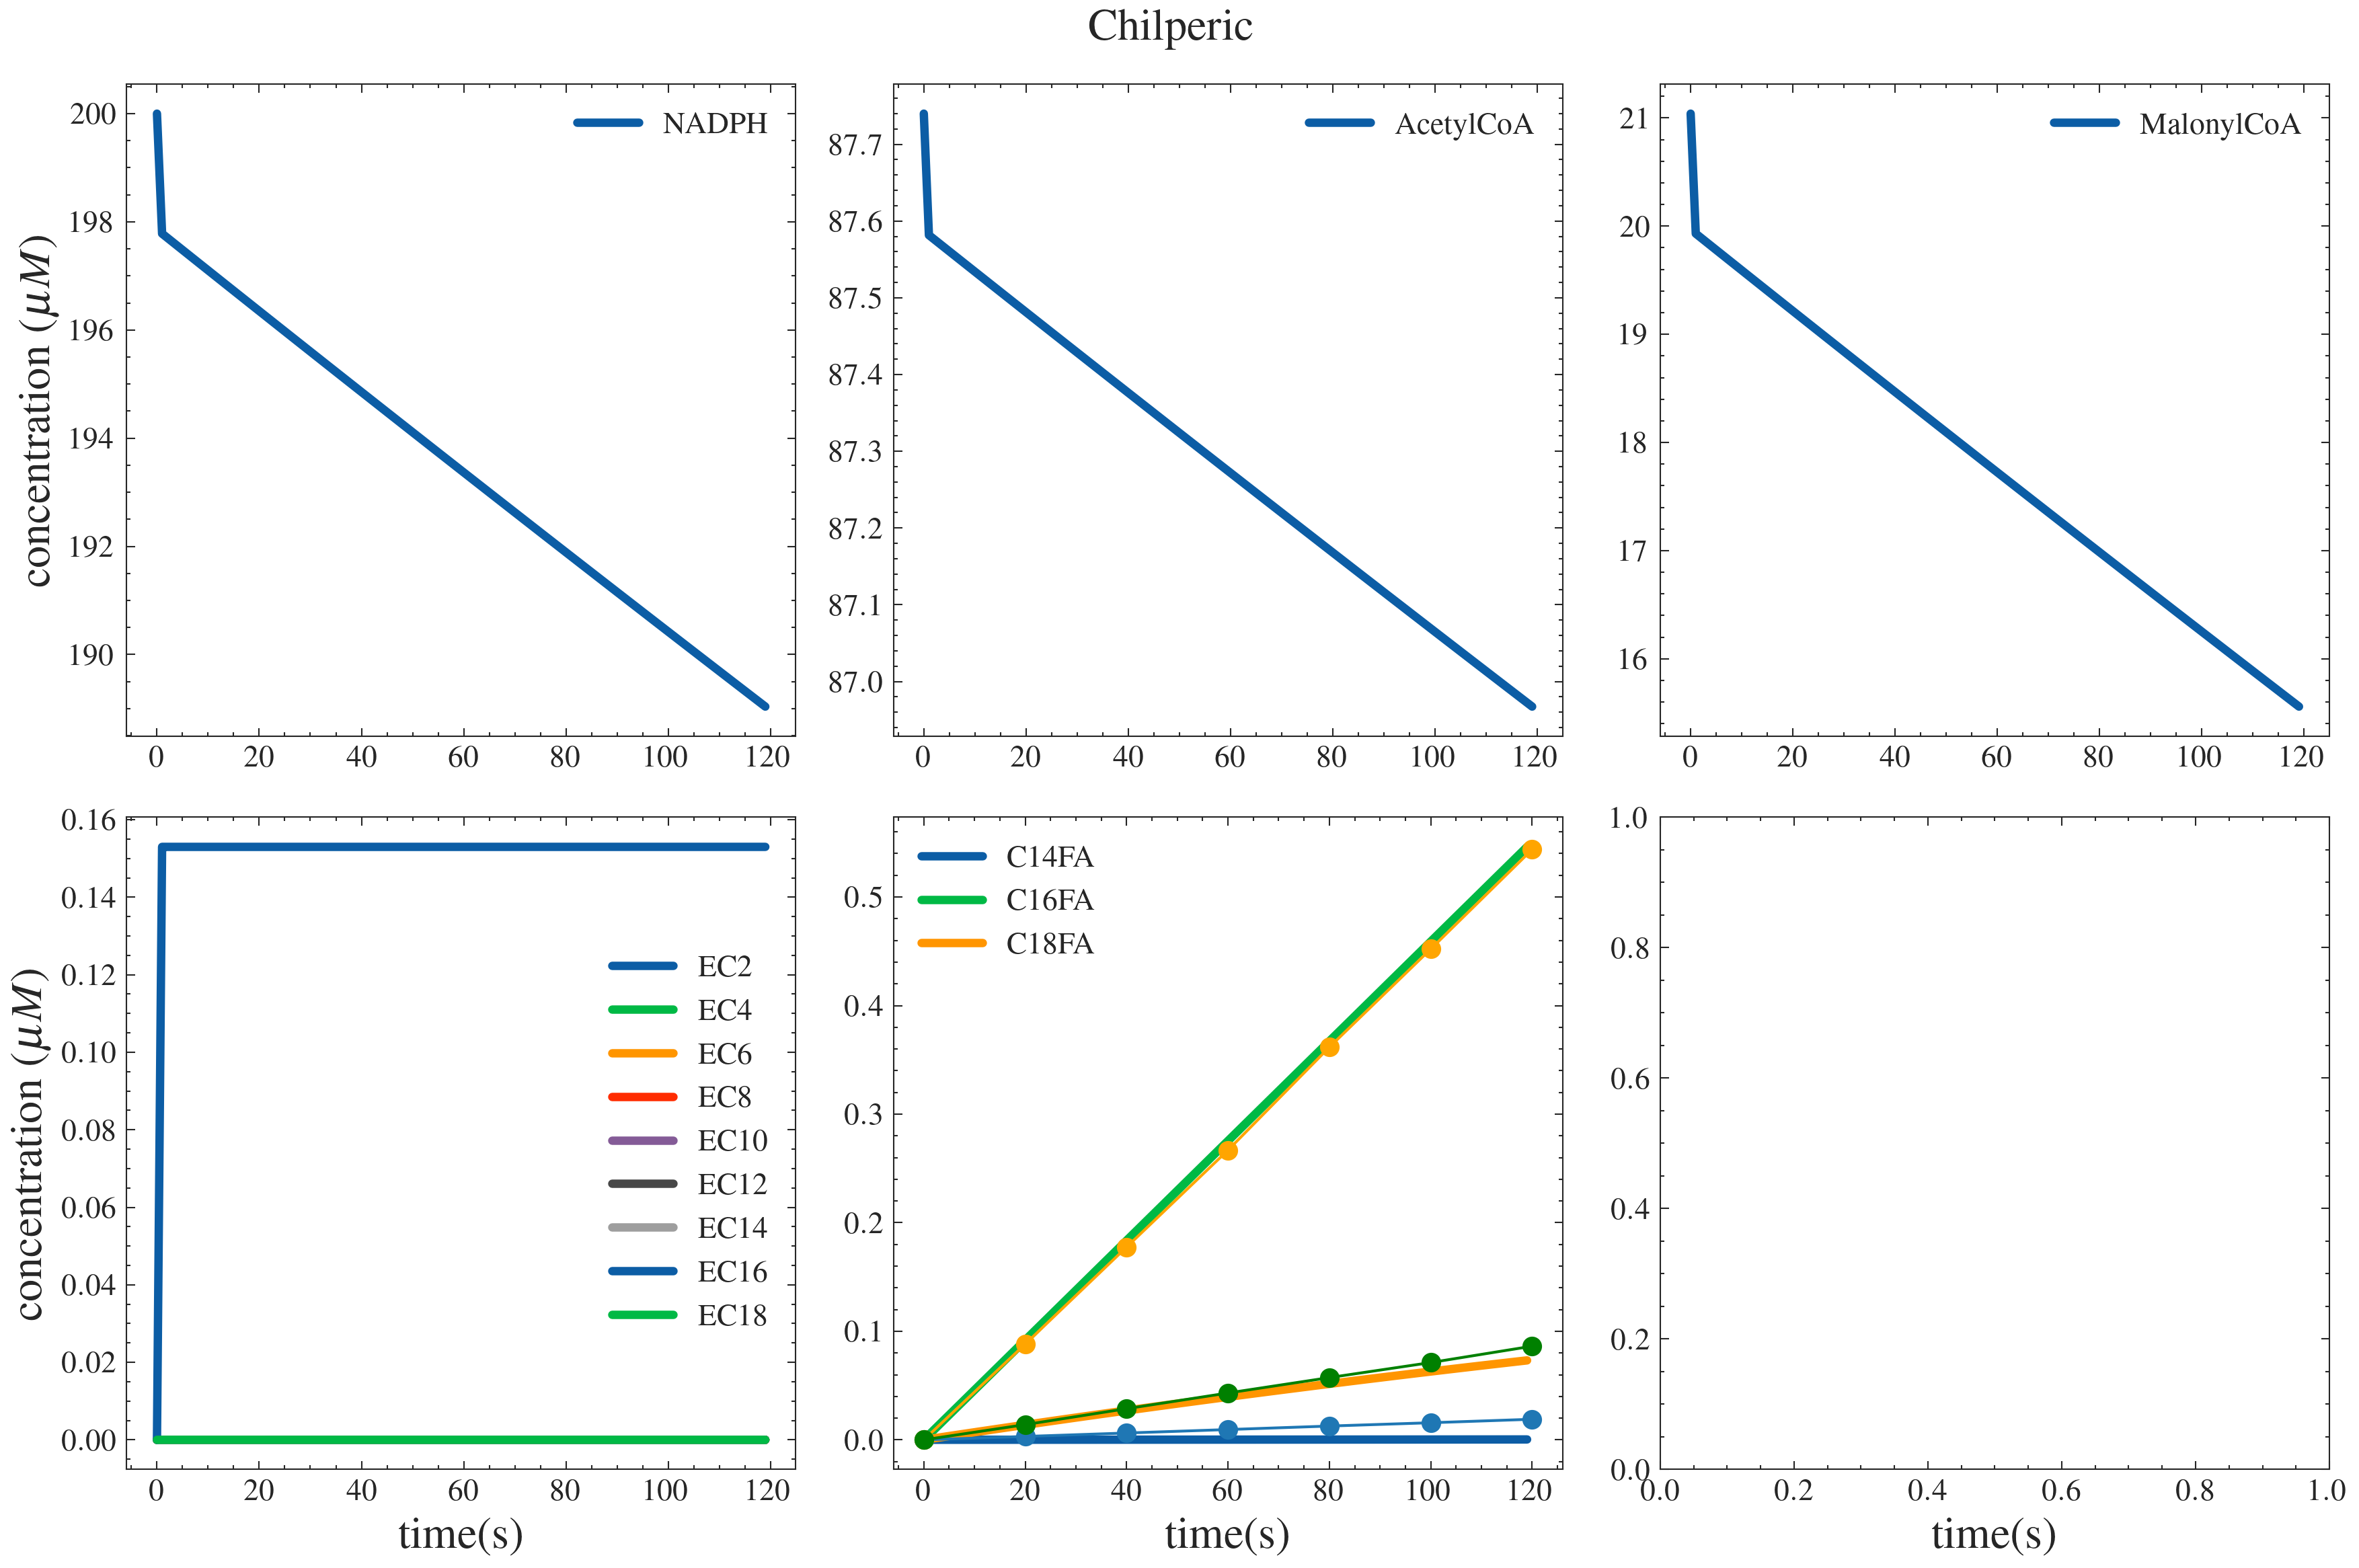

In [193]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title="Chilperic",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two , y0, max_time = time_simulations, ncp_list = ncp_list2)

for i in range(3):
    axs[1, 1].plot(time_initial_phase, data_initial_phase[:, i], "o-", color=colors[i])


### check the parameters on long run

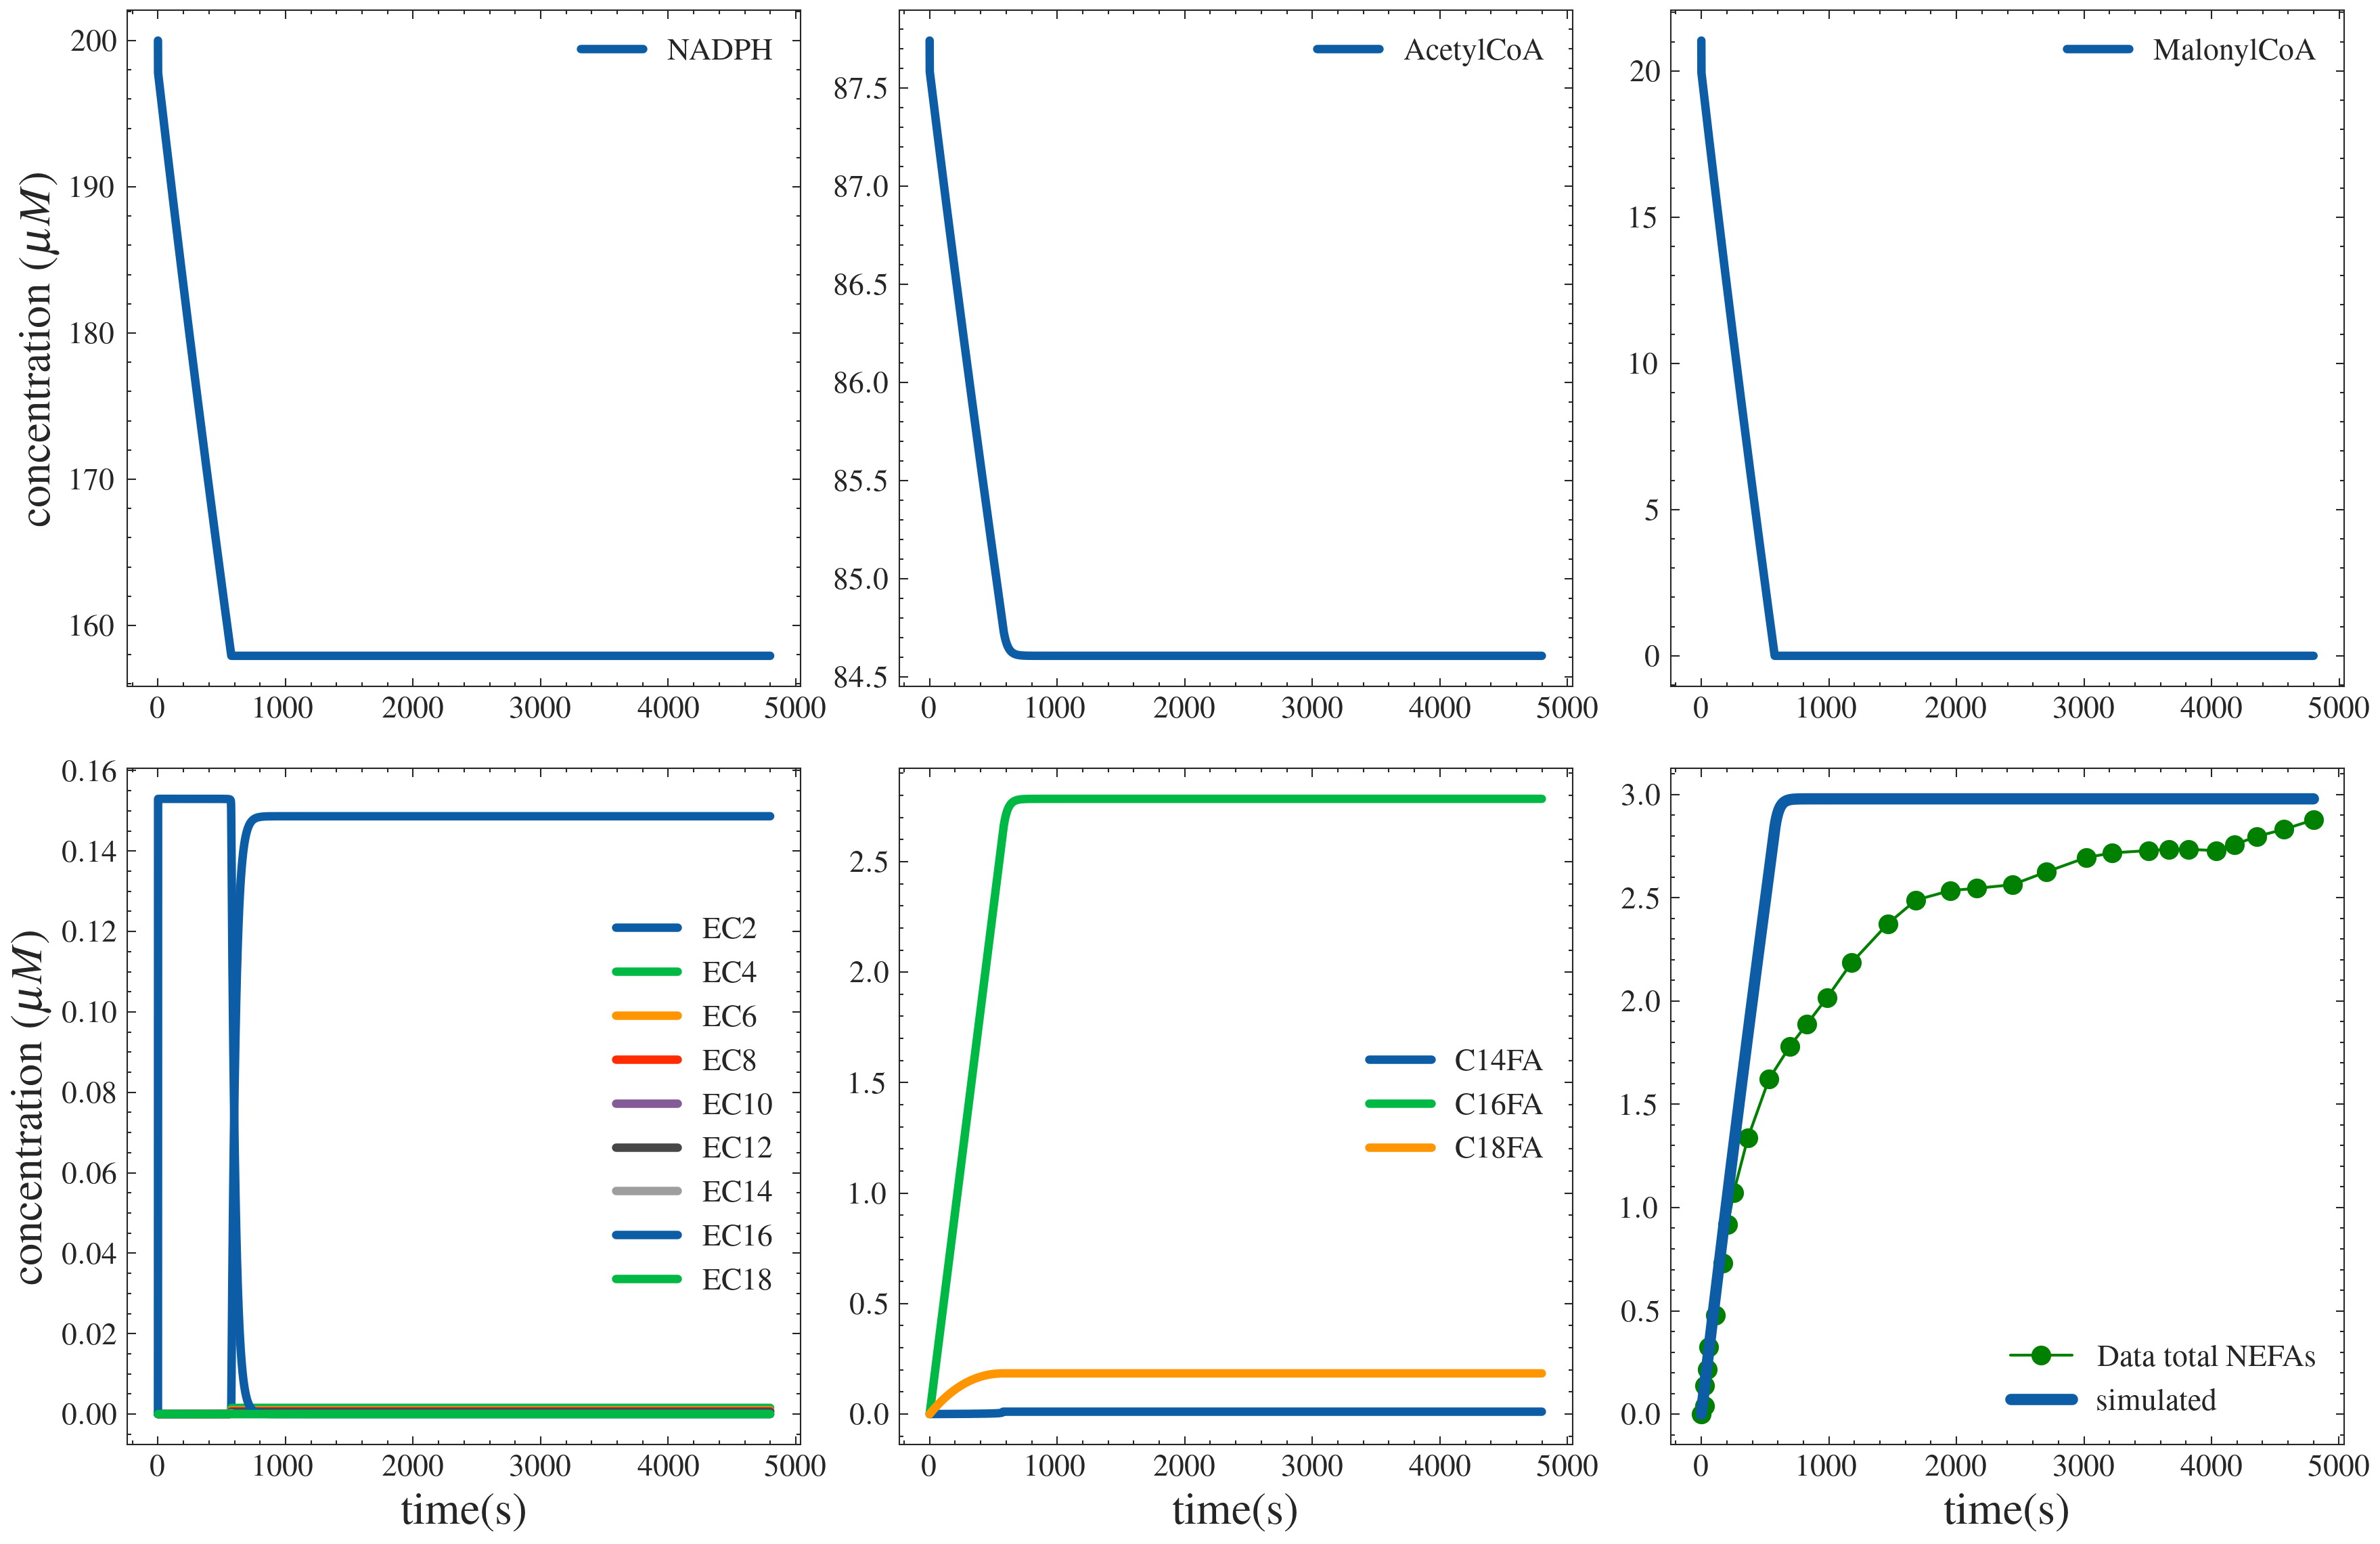

In [194]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fitting_two ,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids= total_fatty_acid(system,par_fitting_two , y0, max_time = time_simulations, ncp_list = ncp_list2)

axs[1, 2].plot(time_simulations, total_nefas1,  "o-", color=colors[i])
axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
axs[1, 2].legend(
    [
    "Data total NEFAs",
    "simulated"
    ],)
fig.patch.set_alpha(0.0) # to make the axis transparent 
plt.savefig(RESULTS_DIR /"long_sim.eps", bbox_inches="tight")

# Conclusion 

- We can fit simultaneously the initial phase and the long run  data to the model. Which allows us to conclude that the model is missing some features. 

-The strategy to correct the transient and the steady state data. We suggest to explore three strategy 

- The sinking enzyme( the enzyme is denaturated over time ) 
- The CoA inhibition 
- The competition between the acetyl-CoA and the malonyl-CoA

For the either strategy we will keep the rapid binding assumptio given that  the chanelling is to make the reaction relatively faster. 


# Sensitivity analaysis 

In [195]:

problem = {
    "num_vars":6,
    "names": [
        "beta",
        "kappa",
        "delta",
        # "kd1",
        # "kd2",
        # "kd3",
        # "kd4",
        # "kd5",
        "kd6",
        "kd7",
        "kd8"
    ],
    "bounds": [
        [0,1e4],
        [0,1e4],
        [0,1e4],
        [0,1e4],
        [0,1e4],
        [0,1e4],
        # [0,1e1],
        # [0,1e1],
        # [0,1e1],
        # [0,1e1],
        # [0,1e1],
        
        
    ],
    
}




param_values = saltelli.sample(problem, 8192, calc_second_order=True, skip_values=8192)

def func(values: list[float], names: list[str]):
    
    param_dict=dict(zip(names, values))
    return    (
            fatty_acid_of_interest(
                system,
               param_dict,
                y0,
                max_time= time_nefas1_simulation,
                ncp_list= time_nefas1_simulation,
            )[-1]
        )

with ProcessPoolExecutor() as executor:
    names = problem["names"]
    y = list(executor.map(func, param_values, it.repeat(names)))
    #print(y)
    
Y = np.array(y)



In [196]:

paramt =  dict(zip(problem["names"],param_values[0]))
print(paramt)

func(paramt.values(), par.keys())
# for i in range(len(param_values)):
#     func(param_values[i], problem["names"])

{'beta': 1.8310546875, 'kappa': 2666.6259765625, 'delta': 2537.2314453125, 'kd6': 7969.3603515625, 'kd7': 7081.9091796875, 'kd8': 2575.0732421875}


array([0.01584572, 0.01297226, 2.60366723])

In [197]:
label_S1_ST=(r'$\beta$',
 r'$\kappa$',
 r'$\delta$',
 r'$k_{d6}$',
 r'$k_{d7}$',
 r'$k_{d8}$'
 )

label_S1_ST

('$\\beta$', '$\\kappa$', '$\\delta$', '$k_{d6}$', '$k_{d7}$', '$k_{d8}$')

In [198]:
label_list =[r'$\beta$',
 r'$\kappa$',
 r'$\delta$',
 r'$k_{d6}$',
 r'$k_{d7}$',
 r'$k_{d8}$'
]

In [199]:
label_S2 = (r"($\beta$, $\kappa$)",
 r"($\beta$, $\delta$)",
 r"($\beta$, $k_{d6}$)",
 r"($\beta$, $k_{d7}$)",
 r"($\beta$, $k_{d8}$)",
 r"($\kappa$, $\delta$)",
 r"($\kappa$, $k_{d6}$)",
 r"($\kappa$, $k_{d7}$)",
 r"($\kappa$, $k_{d8}$)",
 r"($\delta$, $k_{d6}$)",
  r"($\delta$, $k_{d7}$)",
  r"($\delta$, $k_{d8}$)",
 r"($k_{d6}$, $k_{d7}$)",
 r"($k_{d6}$, $k_{d8}$)",
 r"($k_{d7}$, $k_{d8}$)")

In [200]:
def get_combinations(lst):
      # Generate all combinations of the elements in the list
  comb_list = list(it.combinations(lst, 2))

  # Create a tuple for each combination and add it to the list of tuples
  tuple_list = []
  for comb in comb_list:
    tuple_list.append(tuple(comb))

  return tuple_list

# Test the function with a sample list
sample_list = [1, 2, 3, 4]



In [201]:
Si_C14 = sobol.analyze(problem, Y[:, 0], print_to_console=False)
Si_C16 = sobol.analyze(problem, Y[:, 1], print_to_console=False)
Si_C18 = sobol.analyze(problem, Y[:, 2], print_to_console=False)

In [202]:
Saltelli_TC14, Saltelli_1stC14, Saltelli_2stC14 = Si_C14.to_df()
Saltelli_TC16, Saltelli_1stC16, Saltelli_2stC16 = Si_C16.to_df()
Saltelli_TC18, Saltelli_1stC18, Saltelli_2stC18 = Si_C18.to_df()


In [203]:
dfS1 = pd.concat(
    {"C14":Saltelli_1stC14,
"C16":Saltelli_1stC16,
"C18":Saltelli_1stC18,
     }
)
dfS2 =pd.concat(
    {"C14":Saltelli_2stC14,
"C16":Saltelli_2stC16,
"C18":Saltelli_2stC18,
     }
)
dfST = pd.concat(
    {"C14":Saltelli_TC14,
"C16":Saltelli_TC16,
"C18":Saltelli_TC18,
     }
)


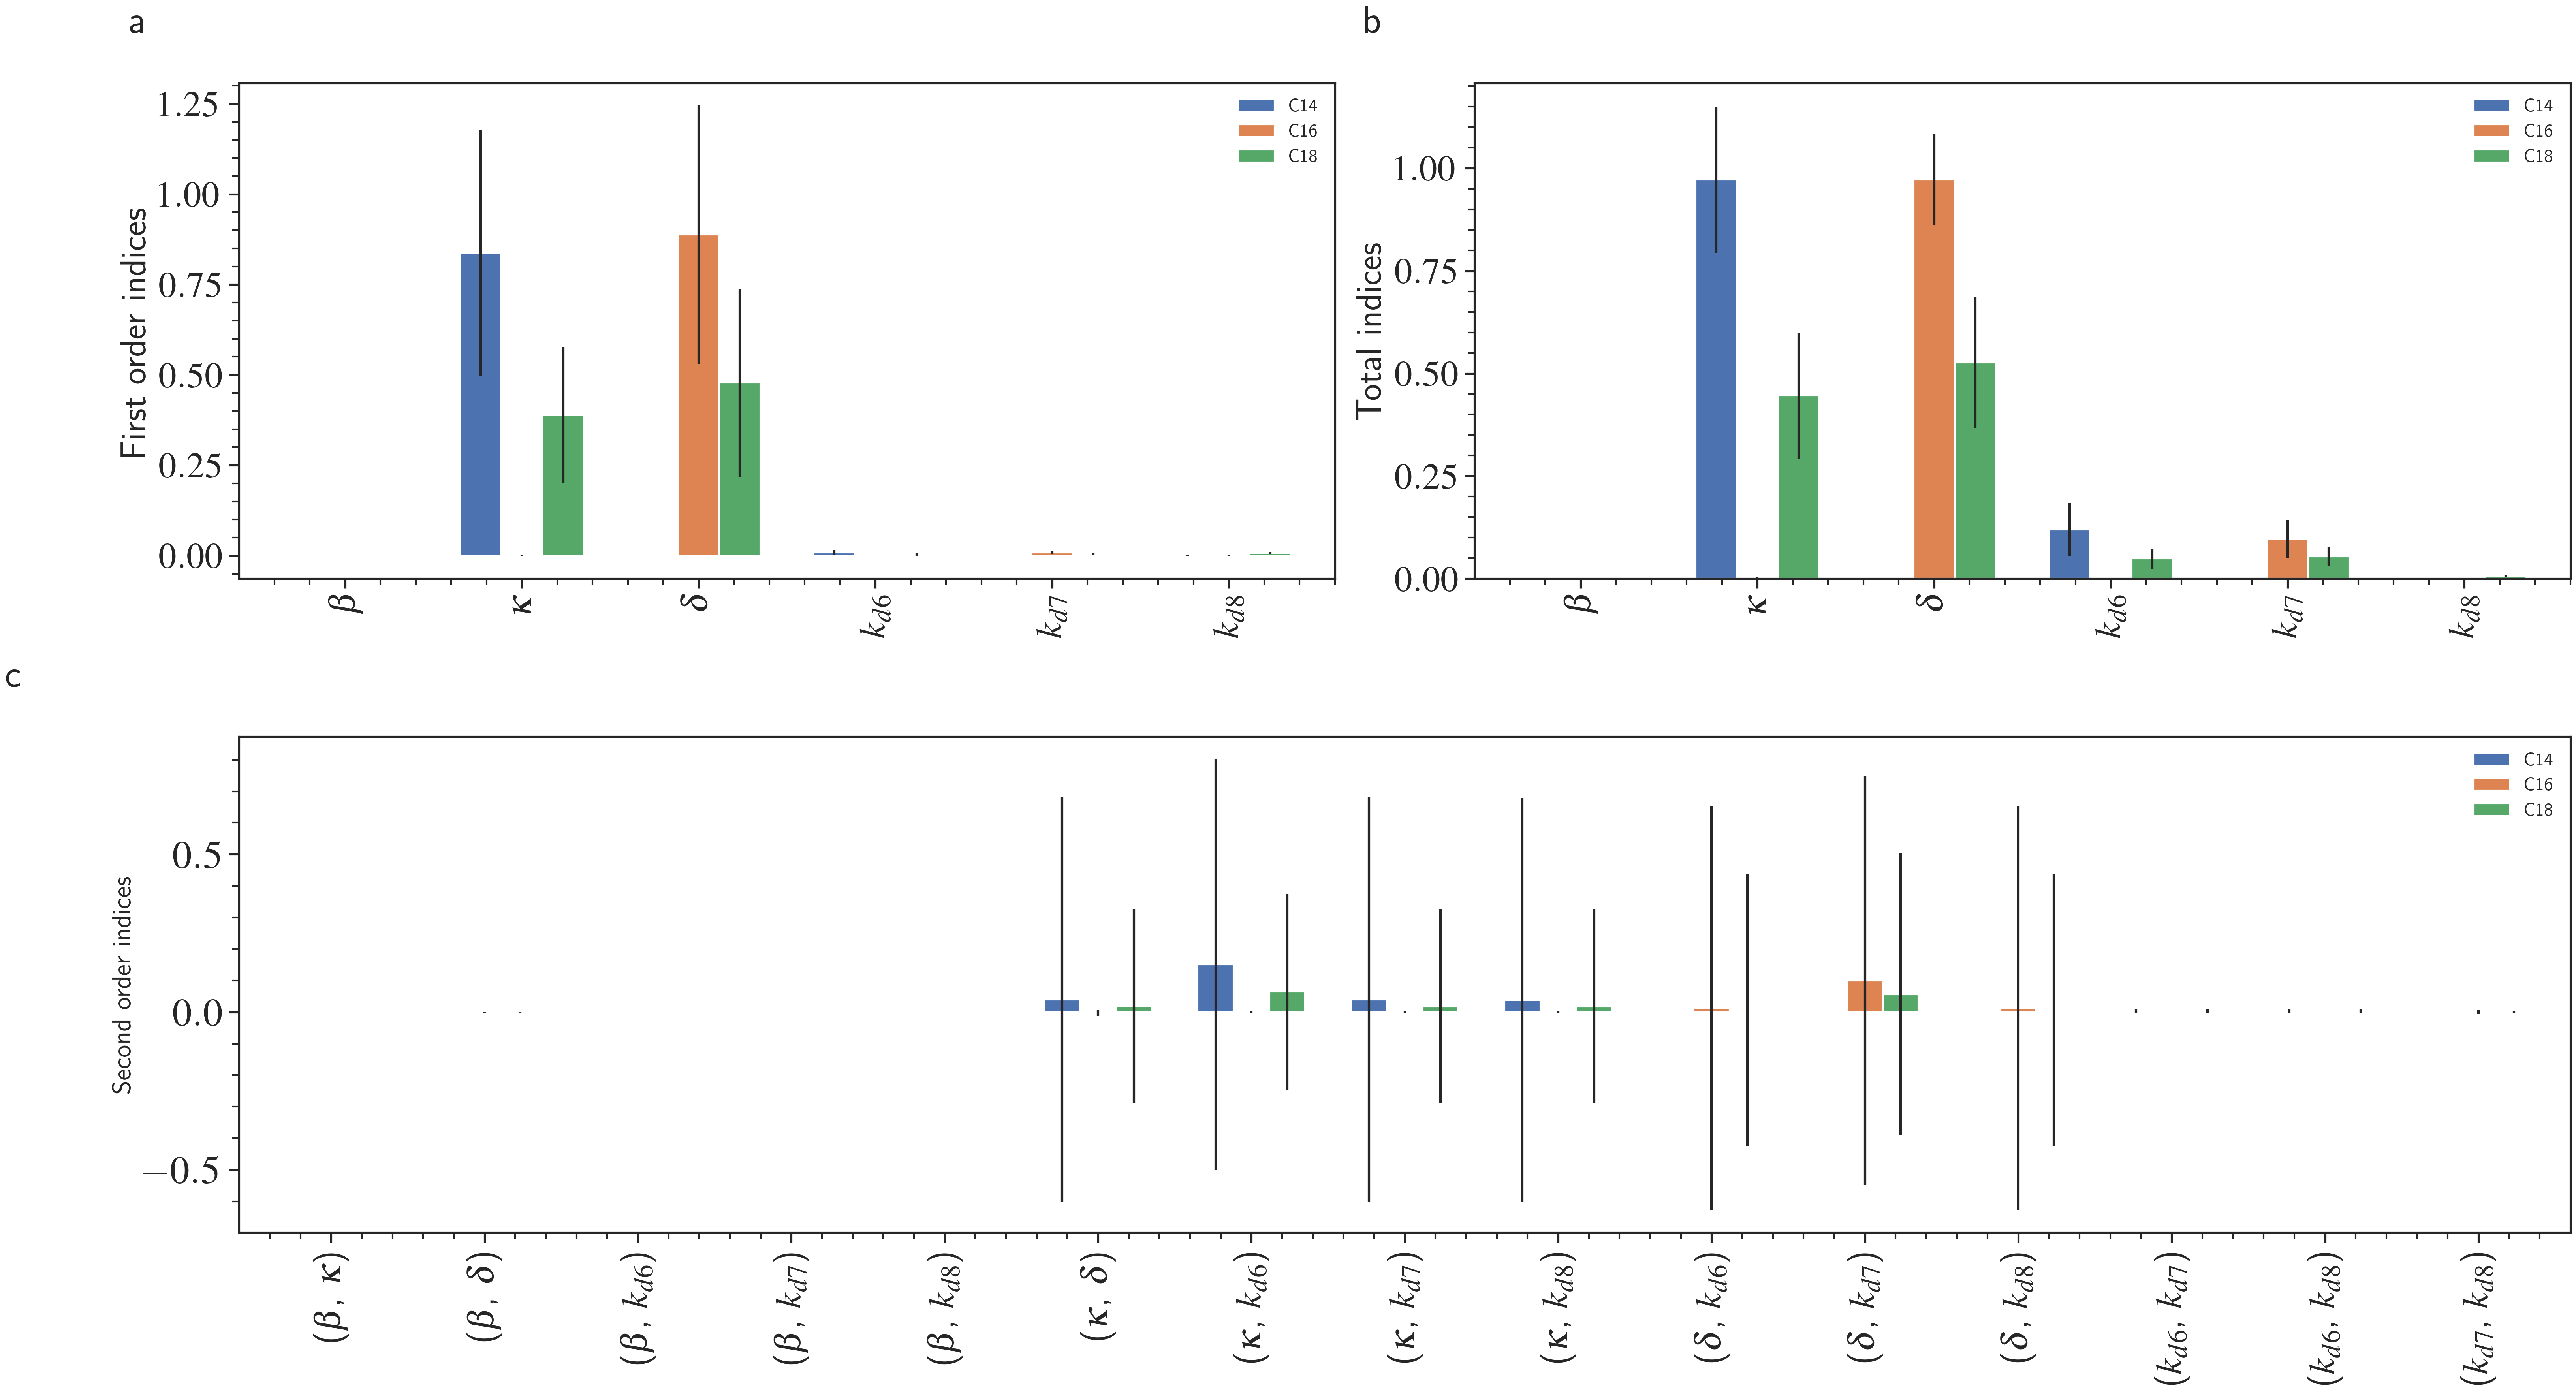

In [209]:
sns.set() 
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(22, 12))
gs = gridspec.GridSpec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

dfS1["S1"].unstack().T.plot(kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1,width =0.7 )
dfST["ST"].unstack().T.plot(kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax2,width =0.7 )
dfS2["S2"].unstack().T.plot(kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3,width =0.7  )

ax1.set_ylabel("First order indices", fontsize=22)
ax2.set_ylabel("Total indices", fontsize=22)
ax3.set_ylabel("Second order indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=22)
ax2.tick_params(axis="x", labelsize=22)
ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=22)
ax2.tick_params(axis="y", labelsize=22)
ax3.tick_params(axis="y", labelsize=24)

ax1.text(-0.1, 1.1, string.ascii_lowercase[0], transform=ax1.transAxes, 
            size=24, weight='bold')
ax2.text(-0.1, 1.1, string.ascii_lowercase[1], transform=ax2.transAxes, 
            size=24, weight='bold')
ax3.text(-0.1, 1.1, string.ascii_lowercase[2], transform=ax3.transAxes, 
            size=24, weight='bold')
ax1.set_xticklabels( label_S1_ST,fontsize=22)
ax2.set_xticklabels( label_S1_ST,fontsize=22)
ax3.set_xticklabels( label_S2,fontsize=22)


fig.patch.set_alpha(0.0)

plt.tight_layout()
fig.savefig(RESULTS_DIR /"sobol_examp1.eps", dpi =300,  bbox_inches='tight')

# Contribution of the parameters to the dynamics of C14:0

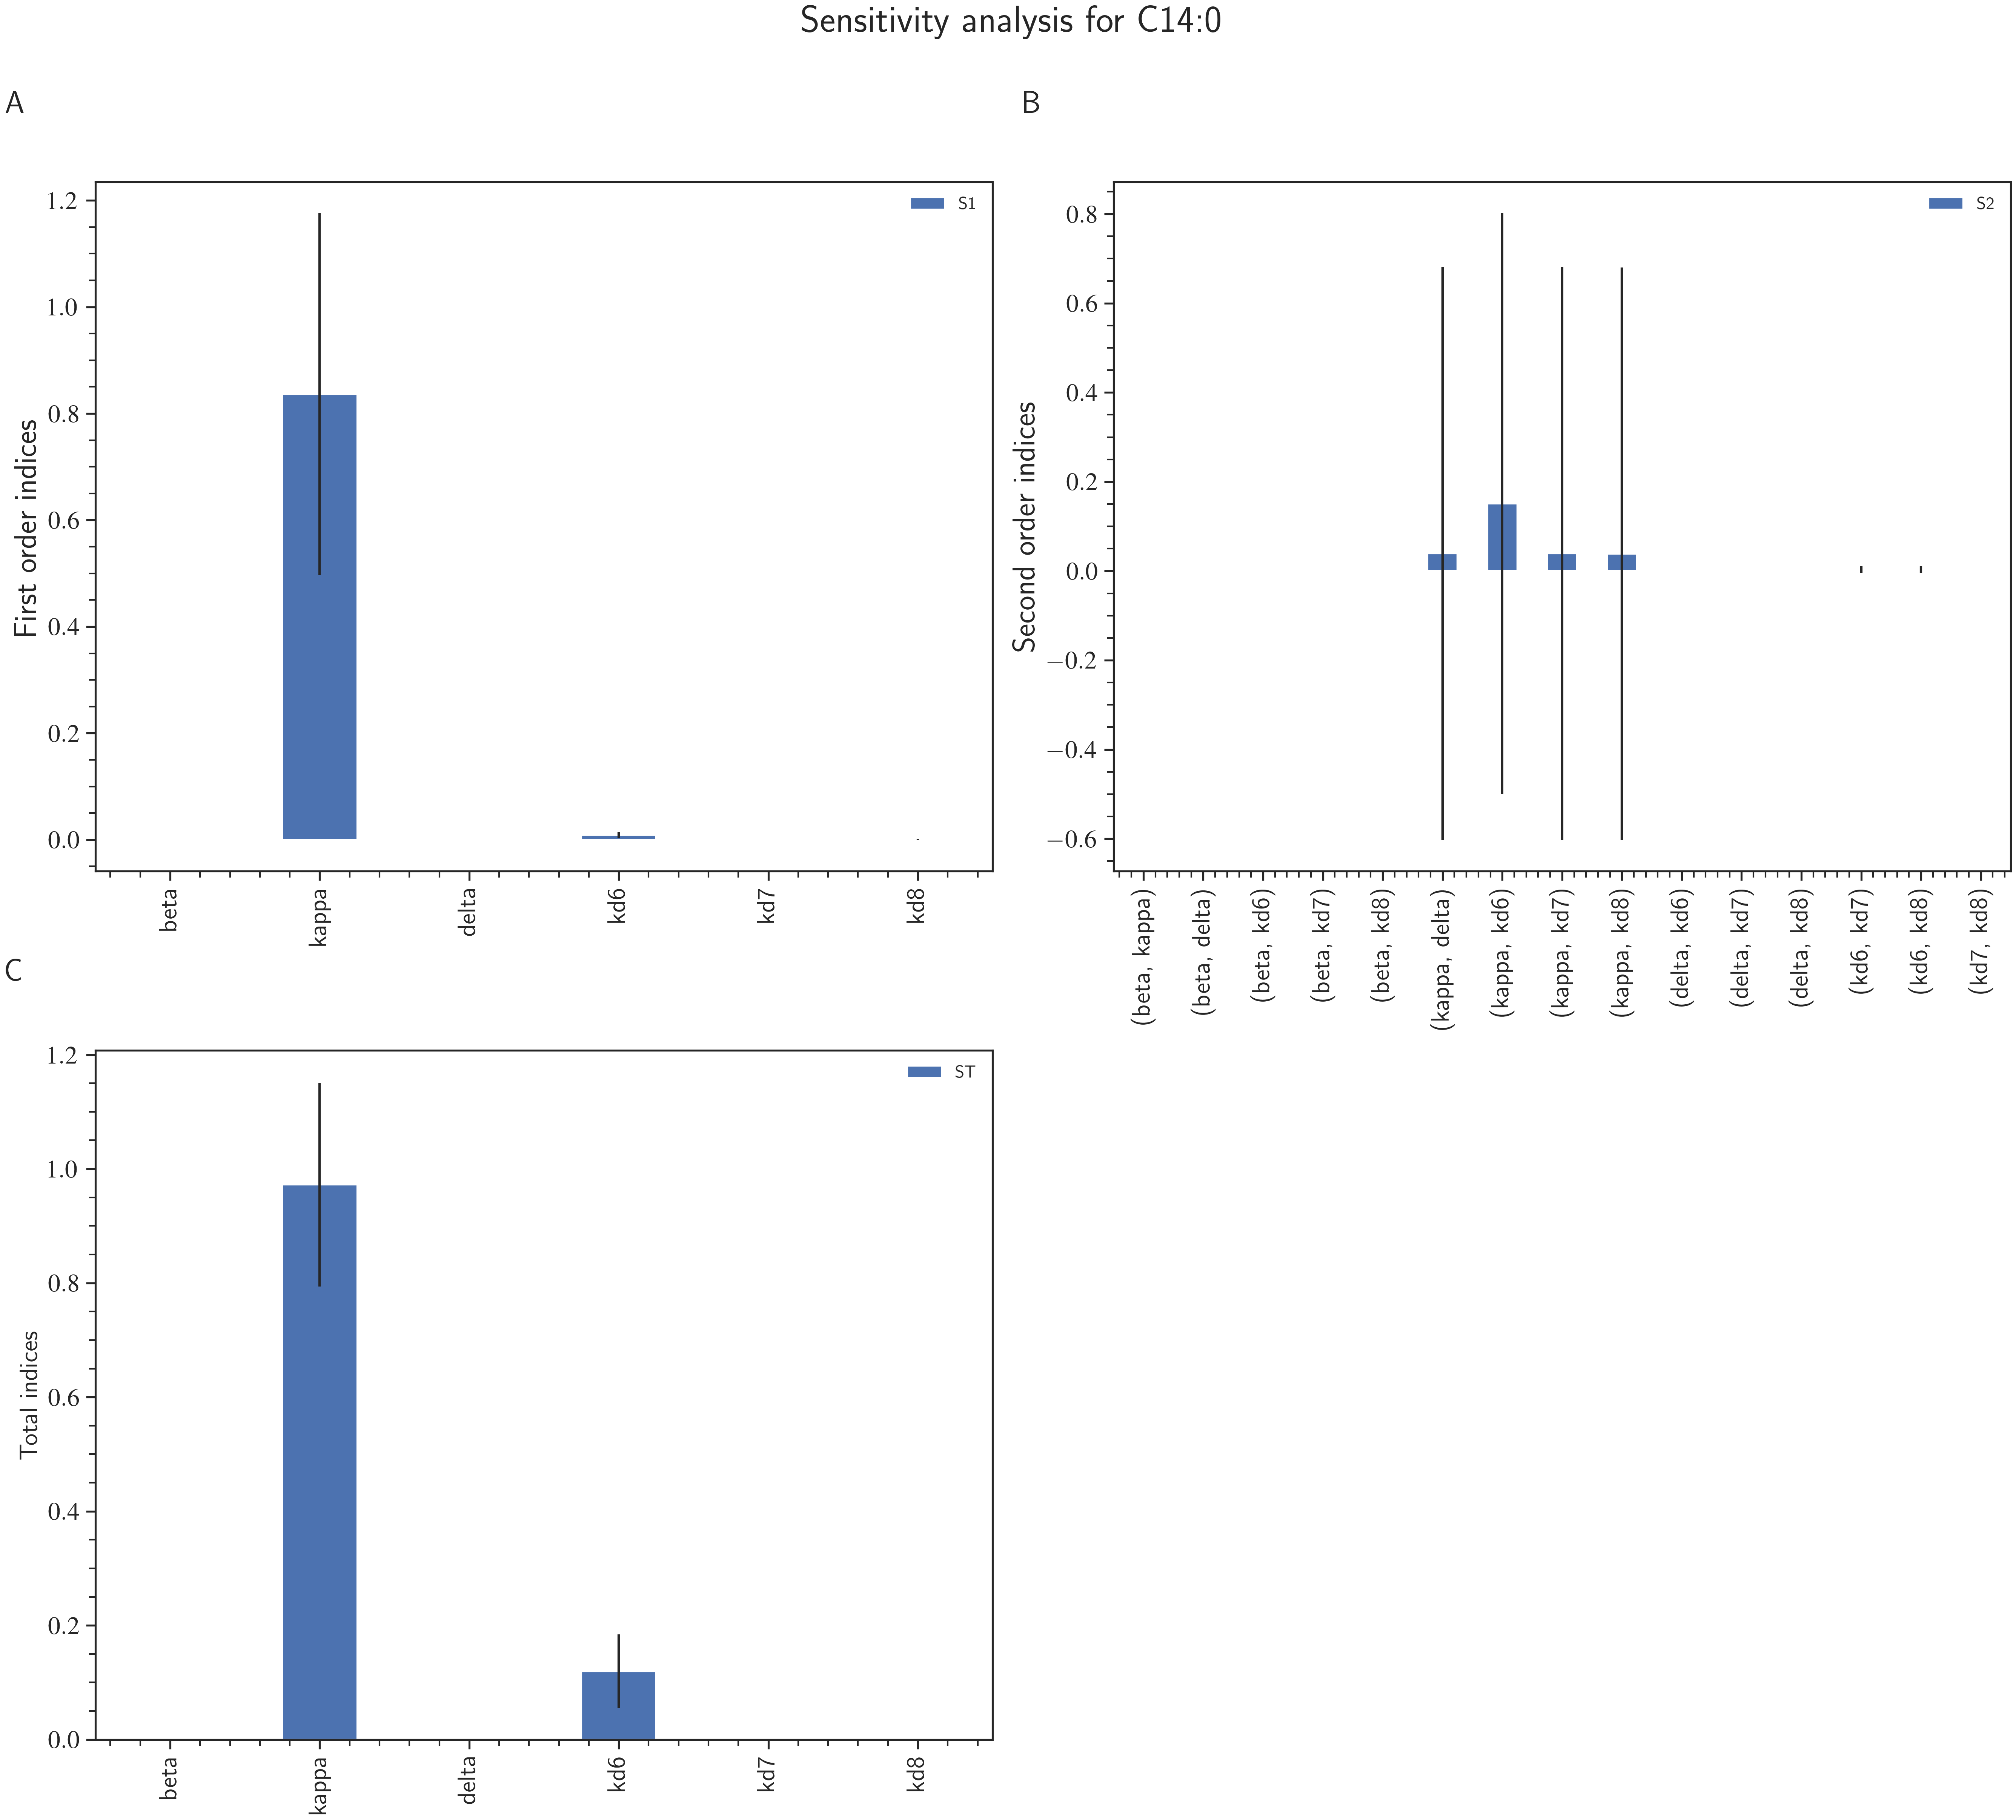

In [205]:
fig, axs = plt.subplots(2,2, figsize=(18,16))


ax1 = barplot(Saltelli_1stC14, ax=axs[0,0])
ax2 = barplot(Saltelli_2stC14, ax=axs[0,1])
ax3 = barplot(Saltelli_TC14, ax=axs[1,0])
ax1.set_ylabel("First order indices", fontsize=20)
ax2.set_ylabel("Second order indices", fontsize=20)
ax3.set_ylabel("Total indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=16)
ax2.tick_params(axis="x", labelsize=16)
ax3.tick_params(axis="x", labelsize=16)

ax1.tick_params(axis="y", labelsize=16)
ax2.tick_params(axis="y", labelsize=16)
ax3.tick_params(axis="y", labelsize=16)

ax1.text(-0.1, 1.1, string.ascii_uppercase[0], transform=ax1.transAxes, 
            size=20, weight='bold')
ax2.text(-0.1, 1.1, string.ascii_uppercase[1], transform=ax2.transAxes, 
            size=20, weight='bold')
ax3.text(-0.1, 1.1, string.ascii_uppercase[2], transform=ax3.transAxes, 
            size=20, weight='bold')
axs[-1, -1].axis('off')

# axes = axs.flat

# for n , ax in enumerate(axes):
#         ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
#             size=20, weight='bold')
#         ax.tick_params(axis="y", labelsize=18)
     
# axs[-1, -1].axis('off')   
fig.suptitle("Sensitivity analysis for C14:0", fontsize=24.0, fontname="serif", fontweight="bold", y =1.01)



#fig.suptitle("Global sensitivity analysis Topolska model", fontsize=24)
fig.tight_layout()
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR /"sobol_C14.eps",  dpi =300,  bbox_inches='tight')

# Contribution of the parameters to the dynamics of C16:0

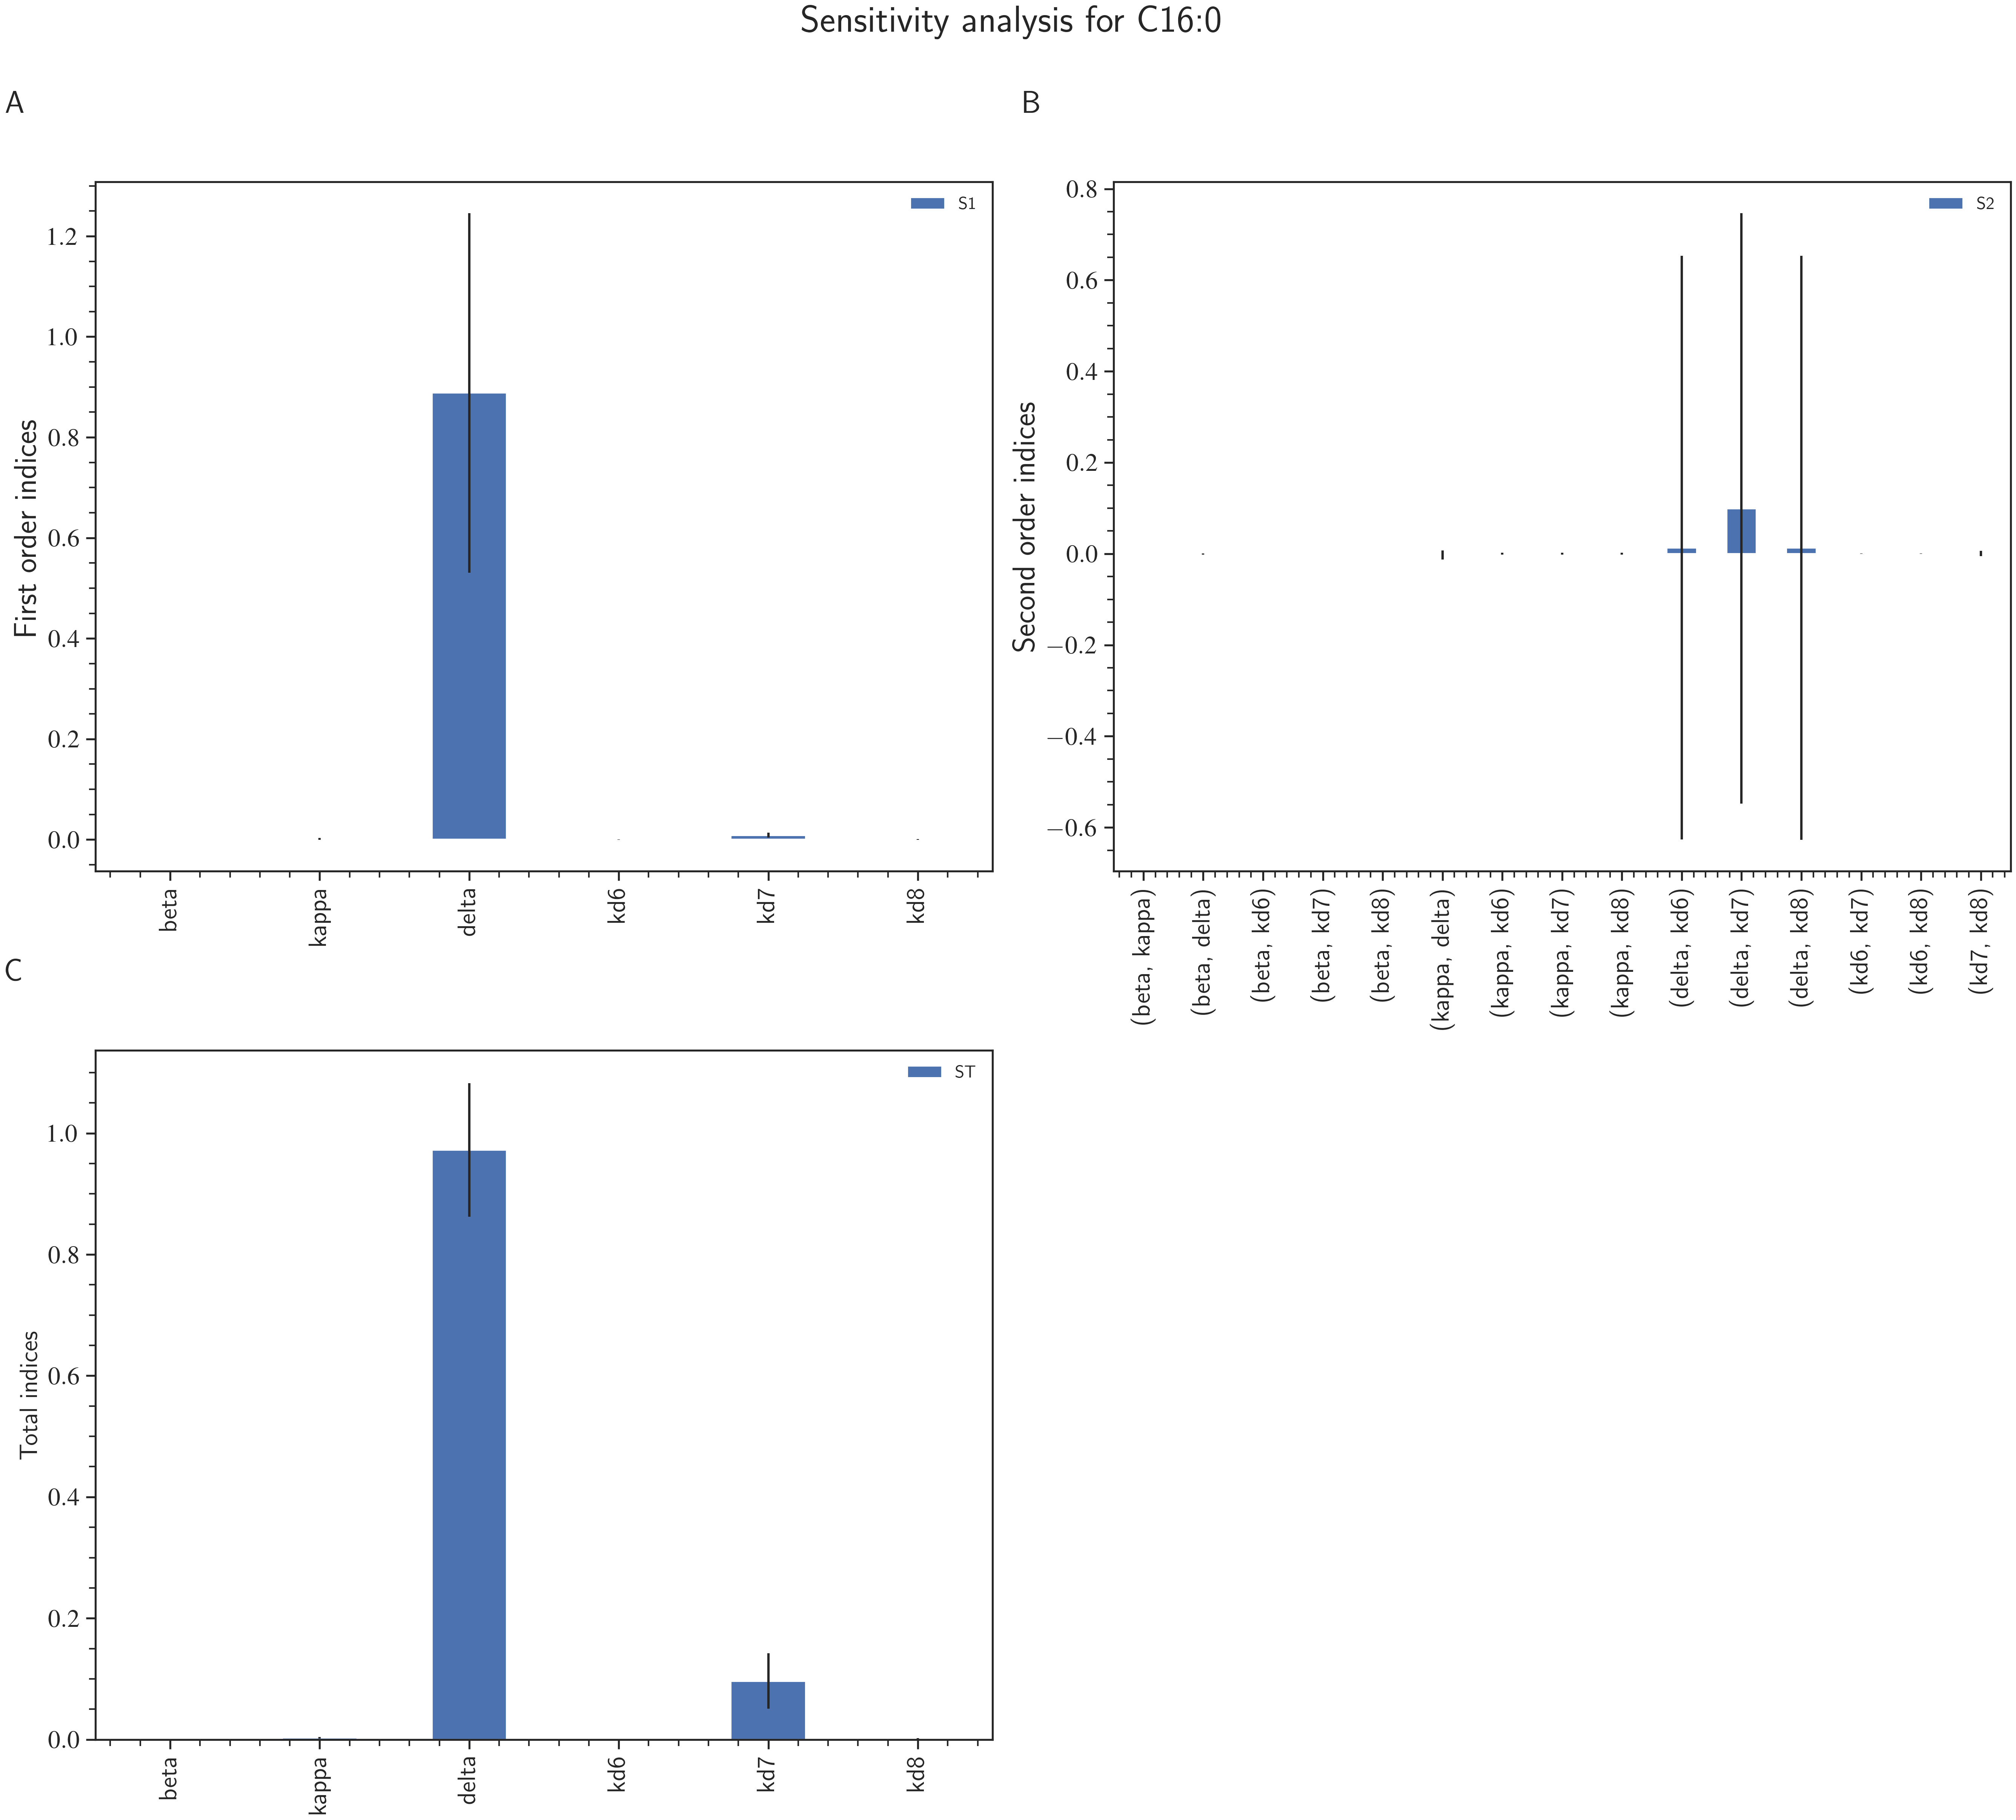

In [206]:
fig, axs = plt.subplots(2,2, figsize=(18,16))


ax1 = barplot(Saltelli_1stC16, ax=axs[0,0])
ax2 = barplot(Saltelli_2stC16, ax=axs[0,1])
ax3 = barplot(Saltelli_TC16, ax=axs[1,0])
ax1.set_ylabel("First order indices", fontsize=20)
ax2.set_ylabel("Second order indices", fontsize=20)
ax3.set_ylabel("Total indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=16)
ax2.tick_params(axis="x", labelsize=16)
ax3.tick_params(axis="x", labelsize=16)

ax1.tick_params(axis="y", labelsize=16)
ax2.tick_params(axis="y", labelsize=16)
ax3.tick_params(axis="y", labelsize=16)

ax1.text(-0.1, 1.1, string.ascii_uppercase[0], transform=ax1.transAxes, 
            size=20, weight='bold')
ax2.text(-0.1, 1.1, string.ascii_uppercase[1], transform=ax2.transAxes, 
            size=20, weight='bold')
ax3.text(-0.1, 1.1, string.ascii_uppercase[2], transform=ax3.transAxes, 
            size=20, weight='bold')
axs[-1, -1].axis('off')

# axes = axs.flat

# for n , ax in enumerate(axes):
#         ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
#             size=20, weight='bold')
#         ax.tick_params(axis="y", labelsize=18)
     
# axs[-1, -1].axis('off')   
fig.suptitle("Sensitivity analysis for C16:0", fontsize=24.0, fontname="serif", fontweight="bold", y =1.01)



#fig.suptitle("Global sensitivity analysis Topolska model", fontsize=24)
fig.tight_layout()
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR /"sobol_C16.eps",  dpi =300,  bbox_inches='tight')

# Contribution of the parameters to the dynamics of C18:0

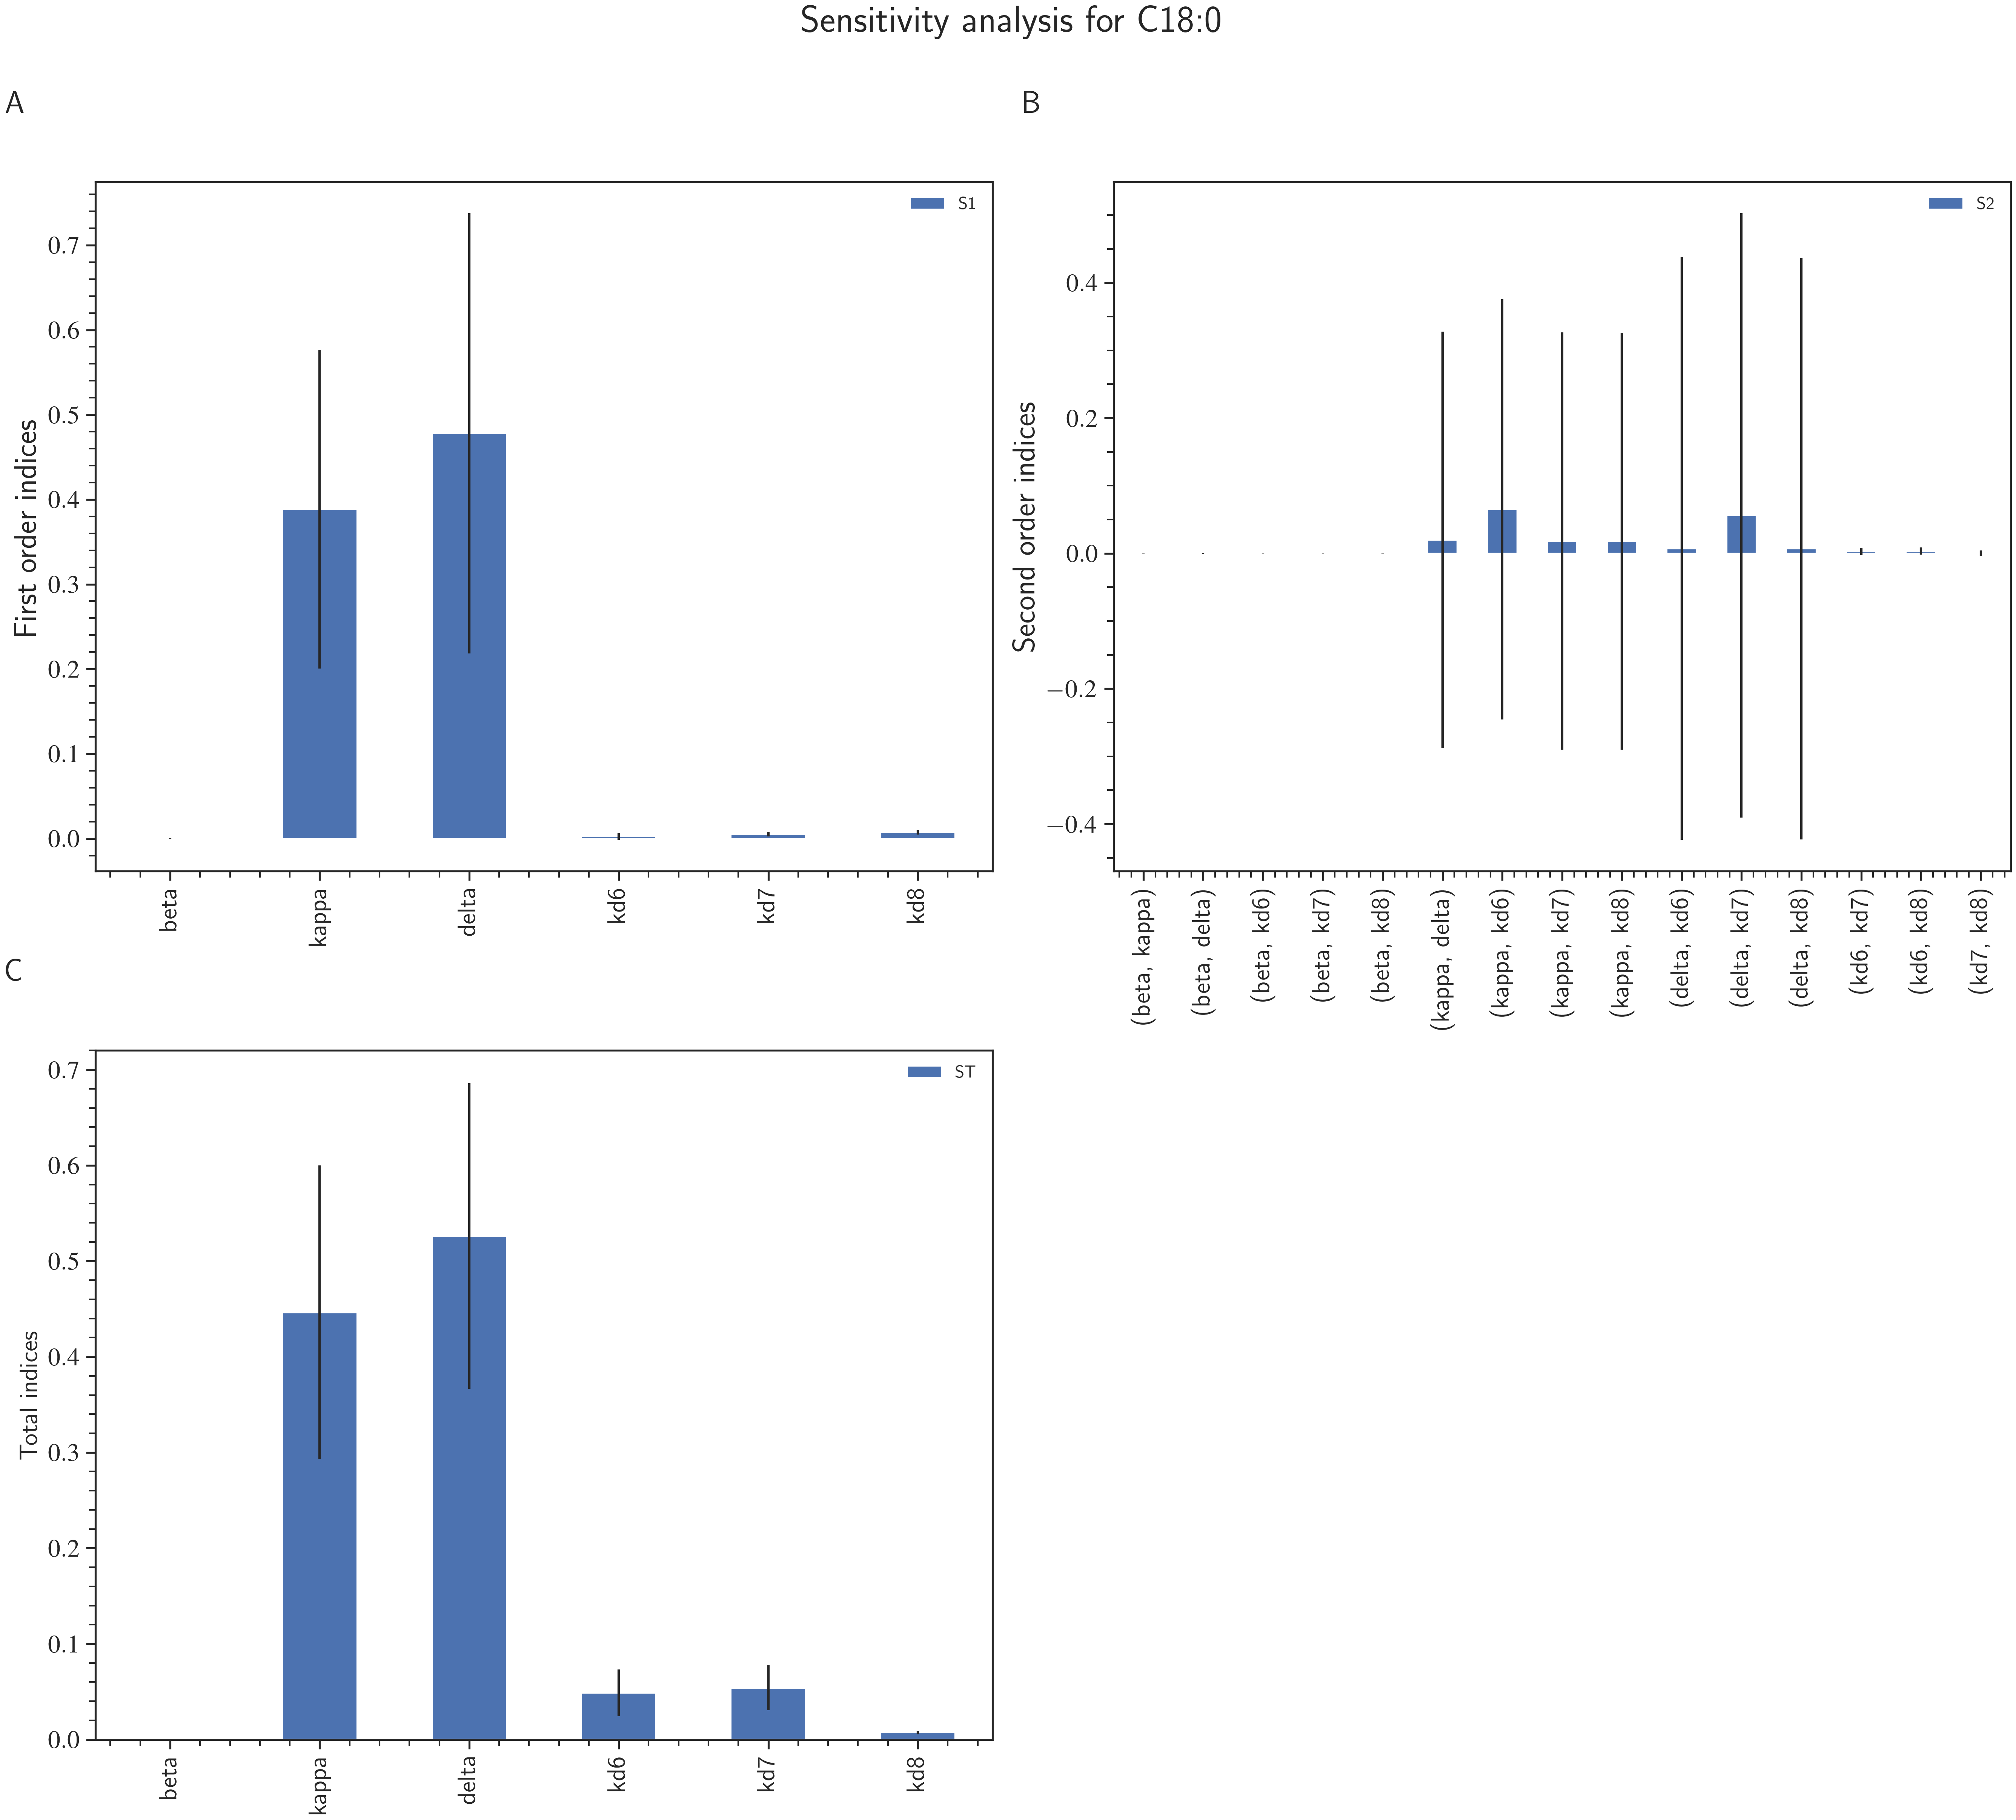

In [207]:
fig, axs = plt.subplots(2,2, figsize=(18,16))


ax1 = barplot(Saltelli_1stC18, ax=axs[0,0])
ax2 = barplot(Saltelli_2stC18, ax=axs[0,1])
ax3 = barplot(Saltelli_TC18, ax=axs[1,0])
ax1.set_ylabel("First order indices", fontsize=20)
ax2.set_ylabel("Second order indices", fontsize=20)
ax3.set_ylabel("Total indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=16)
ax2.tick_params(axis="x", labelsize=16)
ax3.tick_params(axis="x", labelsize=16)

ax1.tick_params(axis="y", labelsize=16)
ax2.tick_params(axis="y", labelsize=16)
ax3.tick_params(axis="y", labelsize=16)

ax1.text(-0.1, 1.1, string.ascii_uppercase[0], transform=ax1.transAxes, 
            size=20, weight='bold')
ax2.text(-0.1, 1.1, string.ascii_uppercase[1], transform=ax2.transAxes, 
            size=20, weight='bold')
ax3.text(-0.1, 1.1, string.ascii_uppercase[2], transform=ax3.transAxes, 
            size=20, weight='bold')
axs[-1, -1].axis('off')

# axes = axs.flat

# for n , ax in enumerate(axes):
#         ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
#             size=20, weight='bold')
#         ax.tick_params(axis="y", labelsize=18)
     
# axs[-1, -1].axis('off')   
fig.suptitle("Sensitivity analysis for C18:0", fontsize=24.0, fontname="serif", fontweight="bold", y =1.01)



#fig.suptitle("Global sensitivity analysis Topolska model", fontsize=24)
fig.tight_layout()
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR /"sobol_C18.eps",  dpi =300,  bbox_inches='tight')

# Heat map of everything together 

/tmp/ipykernel_135656/958610466.py:47: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[0,0].set_xticklabels(label_names)
/tmp/ipykernel_135656/958610466.py:48: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[0,0].set_yticklabels(label_names)
/tmp/ipykernel_135656/958610466.py:54: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[0,1].set_xticklabels(label_names)
/tmp/ipykernel_135656/958610466.py:55: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[0,1].set_yticklabels(label_names)
/tmp/ipykernel_135656/958610466.py:61: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[1,0].set_xticklabels(label_names)
/tmp/ipykernel_135656/958610466.py:62: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[1,0].set_yticklabels(label_names)


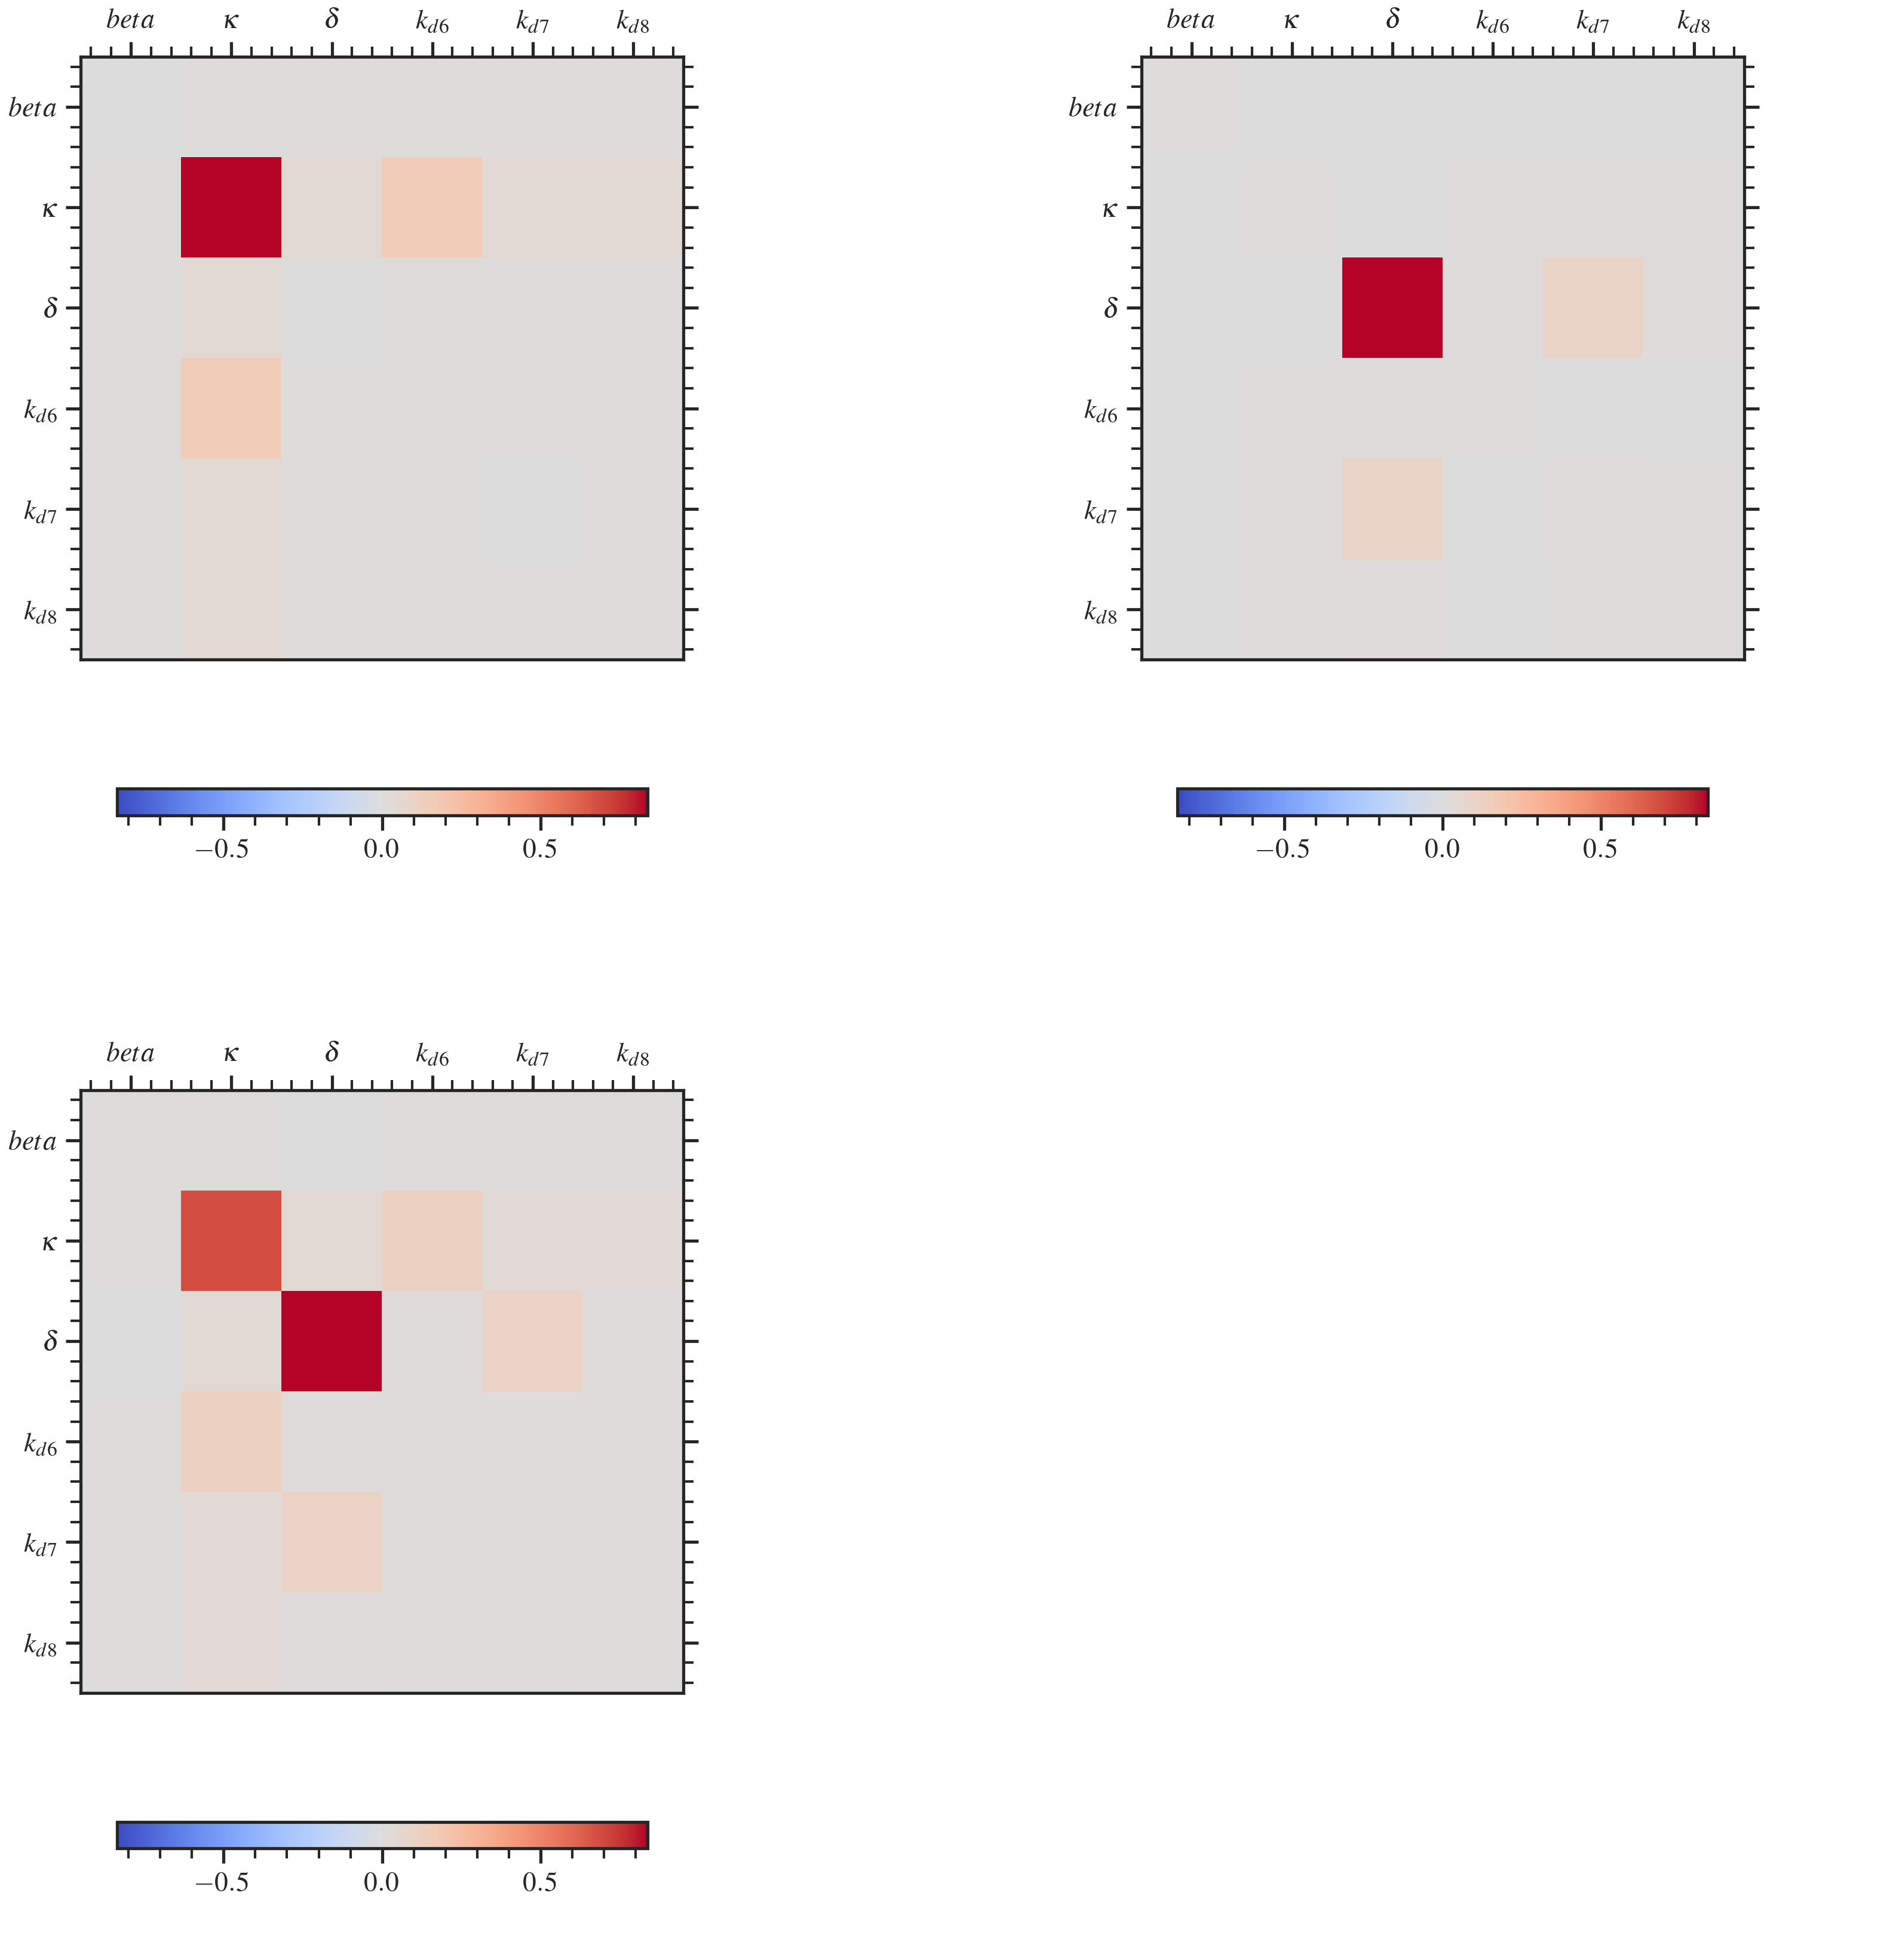

In [208]:

n_params = problem["num_vars"]
comp_matrix_C14 = np.ndarray(shape = (n_params,n_params))
comp_matrix_C16 = np.ndarray(shape = (n_params,n_params))
comp_matrix_C18 = np.ndarray(shape = (n_params,n_params))
for j in range(n_params):
    for i in range(n_params):
        if i == j:
            comp_matrix_C14[i,j] = Si_C14['S1'][i]
            comp_matrix_C16[i,j] = Si_C16['S1'][i]
            comp_matrix_C18[i,j] = Si_C18['S1'][i]
        else:
            comp_matrix_C14[i,j] = Si_C14['S2'][i,j]
            comp_matrix_C14[j,i] = Si_C14['S2'][i,j]
            comp_matrix_C16[i,j] = Si_C16['S2'][i,j]
            comp_matrix_C16[j,i] = Si_C16['S2'][i,j]
            comp_matrix_C18[i,j] = Si_C18['S2'][i,j]
            comp_matrix_C18[j,i] = Si_C18['S2'][i,j]
            
# print comp_matrix

# define labels for figure: phi = dip, d = dip direction, s = slip, subscript = fault event
label_names = ["","$beta$", "$\kappa$", "$\delta$", "$k_{d6}$", "$k_{d7}$", "$k_{d8}$", "$K_{fCoA}$", "$K_{bCoA}$"]

# Create figure
fig, axs = plt.subplots(2,2, figsize=(14,14))

im_c14 = axs[0,0].imshow(comp_matrix_C14, interpolation='nearest', cmap='coolwarm', 
               vmax = np.max(np.abs(comp_matrix_C14)),
                vmin = -np.max(np.abs(comp_matrix_C14)),

)
im_c16 = axs[0,1].imshow(comp_matrix_C16, interpolation='nearest', cmap='coolwarm', 
               vmax = np.max(np.abs(comp_matrix_C16)),
                vmin = -np.max(np.abs(comp_matrix_C16)),

)
im_c18 = axs[1,0].imshow(comp_matrix_C18, interpolation='nearest', cmap='coolwarm', 
               vmax = np.max(np.abs(comp_matrix_C18)),
                vmin = -np.max(np.abs(comp_matrix_C18)),

)


axs[0,0].yaxis.set_ticks_position("both")
axs[0,0].xaxis.set_ticks_position("top")

axs[0,0].set_xticklabels(label_names)
axs[0,0].set_yticklabels(label_names)
fig.colorbar(im_c14, ax = axs[0,0], shrink=0.6, location='bottom')

axs[0,1].yaxis.set_ticks_position("both")
axs[0,1].xaxis.set_ticks_position("top")

axs[0,1].set_xticklabels(label_names)
axs[0,1].set_yticklabels(label_names)
fig.colorbar(im_c14, ax = axs[0,1], shrink=0.6, location='bottom')

axs[1,0].yaxis.set_ticks_position("both")
axs[1,0].xaxis.set_ticks_position("top")

axs[1,0].set_xticklabels(label_names)
axs[1,0].set_yticklabels(label_names)
fig.colorbar(im_c14, ax = axs[1,0], shrink=0.6, location='bottom')
axs[-1, -1].axis('off') 

# ax.set_title("Sensitivities")

#ax.set_xlabel("Parameter Sensitivities")

#fig.colorbar(im_c14)
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR /"heat_map_SA.eps",  dpi =300,  bbox_inches='tight')